# Analysis

Python is the default kernel. An R kernel is fine if that is the language you can explain. `CHECKLIST.md` is the list that counts. The ticks on the lab page do not.

The held-out score, in the units of the decision, is computed in this notebook. The reason slide in `presentation.qmd` has to agree with it. The risk slide is the risk of the action, not this score.


## Setup

Import what you use and set the random seed. Pin those packages in `requirements.txt` and the interpreter in `.python-version`, or use `renv.lock` for R. When a result depends on the draw, record the seed in `decisions.md`. Before fitting, check each file in `data/` against the SHA-256 in `data/README.md`.


In [ ]:

# CELL 3 — SETUP (CORRECTED FOR GOOGLE COLAB)

from pathlib import Path
import os
import sys
import subprocess
import io
import zipfile
import hashlib
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import nbinom
from IPython.display import display

# 1. Reproducibility
SEED = 20261112
rng = np.random.default_rng(SEED)

# 2. Locate the GitHub project
REPO_URL = "https://github.com/ALAZAR122/aii600-final-project.git"
REPO_NAME = "aii600-final-project"

ROOT = Path.cwd()

if not (ROOT / "CHECKLIST.md").exists():

    # Check whether the repository already exists in Colab
    colab_repo = Path("/content") / REPO_NAME

    if (colab_repo / "CHECKLIST.md").exists():
        ROOT = colab_repo

    else:
        # Clone the repository if necessary
        parent = (
            Path("/content")
            if Path("/content").exists()
            else Path.cwd()
        )

        target = parent / REPO_NAME

        if not target.exists():
            print("Cloning GitHub repository...")

            subprocess.run(
                ["git", "clone", REPO_URL, str(target)],
                check=True
            )

        ROOT = target

# 3. Verify the project root
if not (ROOT / "CHECKLIST.md").exists():
    raise FileNotFoundError(
        f"CHECKLIST.md not found in {ROOT}. "
        "Verify that the repository was cloned correctly."
    )

os.chdir(ROOT)

# 4. Create required project folders
(ROOT / "fig").mkdir(parents=True, exist_ok=True)
(ROOT / "data").mkdir(parents=True, exist_ok=True)

# 5. Define the professor's decision-loss parameters
C_SHORT = 4.0
C_EXCESS = 1.0

TAU = C_SHORT / (C_SHORT + C_EXCESS)

# 6. Asymmetric capacity decision loss
def decision_loss(q, d, cs=C_SHORT, ce=C_EXCESS):
    return (
        cs * np.maximum(np.asarray(d) - np.asarray(q), 0)
        + ce * np.maximum(np.asarray(q) - np.asarray(d), 0)
    )

# 7. Negative binomial capacity quantile
def nb_quantile(mu, alpha, tau=TAU):
    mu = np.maximum(np.asarray(mu, dtype=float), 1e-6)

    if alpha <= 0:
        raise ValueError("alpha must be positive")

    size = 1.0 / float(alpha)
    probability = size / (size + mu)

    return nbinom.ppf(
        tau,
        size,
        probability
    ).astype(int)

# 8. Verify setup
print("SETUP COMPLETED SUCCESSFULLY")
print("Project root:", ROOT)
print("Python version:", sys.version.split()[0])
print("Seed:", SEED)
print("Cost ratio:", C_SHORT / C_EXCESS)
print("Capacity quantile:", TAU)
print("CHECKLIST.md found:", (ROOT / "CHECKLIST.md").exists())
print("Data folder:", ROOT / "data")
print("Figures folder:", ROOT / "fig")


SETUP COMPLETED SUCCESSFULLY
Project root: /content/aii600-final-project
Python version: 3.13.18
Seed: 20261112
Cost ratio: 4.0
Capacity quantile: 0.8
CHECKLIST.md found: True
Data folder: /content/aii600-final-project/data
Figures folder: /content/aii600-final-project/fig


## Question

Can a negative binomial predictive distribution of next-hour recorded
system-wide bicycle rentals (rentals/hour) reduce average illustrative
capacity loss versus the same hour one week earlier?

The target is completed rentals, not latent demand.

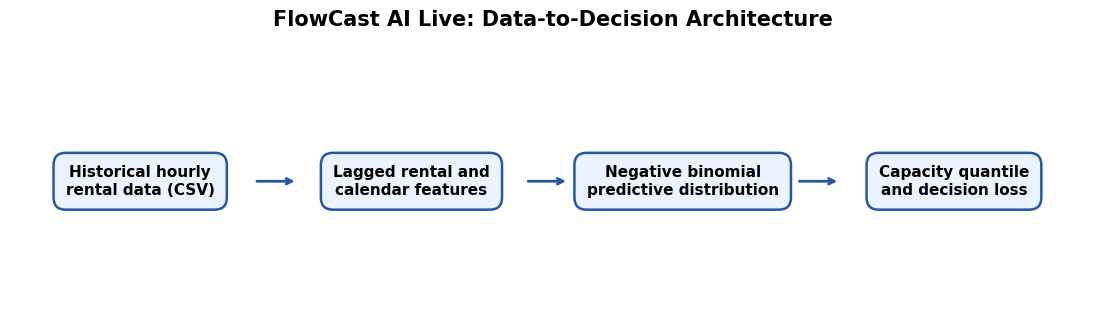

Diagram generated successfully!
Saved to: /content/aii600-final-project/fig/layers.png
File exists: True


In [ ]:

# QUESTION SECTION — LAYER DIAGRAM

import matplotlib.pyplot as plt
from pathlib import Path

# Use ROOT from Cell 3
fig_dir = ROOT / "fig"
fig_dir.mkdir(parents=True, exist_ok=True)

# Create figure
fig, ax = plt.subplots(figsize=(14, 3.5))

labels = [
    "Historical hourly\nrental data (CSV)",
    "Lagged rental and\ncalendar features",
    "Negative binomial\npredictive distribution",
    "Capacity quantile\nand decision loss"
]

# Horizontal positions of boxes
positions = [0.12, 0.37, 0.62, 0.87]

# Draw each processing layer
for i, label in enumerate(labels):
    ax.text(
        positions[i],
        0.5,
        label,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold",
        transform=ax.transAxes,
        bbox=dict(
            boxstyle="round,pad=0.8",
            facecolor="#EAF3FF",
            edgecolor="#2457A7",
            linewidth=1.8
        )
    )

# Draw connecting arrows
for i in range(len(positions) - 1):
    ax.annotate(
        "",
        xy=(positions[i + 1] - 0.105, 0.5),
        xytext=(positions[i] + 0.105, 0.5),
        xycoords="axes fraction",
        textcoords="axes fraction",
        arrowprops=dict(
            arrowstyle="->",
            linewidth=2,
            color="#2457A7"
        )
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

plt.title(
    "FlowCast AI Live: Data-to-Decision Architecture",
    fontsize=15,
    fontweight="bold",
    pad=15
)

# Save diagram
output_path = fig_dir / "layers.png"

plt.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

# Display diagram in notebook
plt.show()

print("Diagram generated successfully!")
print("Saved to:", output_path)
print("File exists:", output_path.exists())


## Data

Download the release into this folder, with `OWNER/REPO` your fork:

```bash
gh release download data --dir data --repo OWNER/REPO
```

If the terms do not let you republish the files, there is no release: run the download command in `data/README.md` instead. The upload commands are in `data/README.md` too. Read the files from `data/`. Show one plot of the raw data and one table of summary statistics before any model. Save the plot under `fig/`.

Source: UCI Bike Sharing Dataset, hour.csv, 2011–2012. Download only from UCI. A local SHA-256 is generated on initial retrieval and checked on subsequent runs. This checks local file consistency, not source authenticity. Show the raw series and descriptive table before fitting. Avoid casual and registered because they add up to the target; avoid observed weather in the target hour because it would not be available at prediction time.


hour.csv not found locally. Downloading UCI Bike Sharing dataset...
Downloaded and extracted to: /content/aii600-final-project/data/hour.csv
DATASET PREVIEW


,datetime,cnt,temp,hum
0,2011-01-01 00:00:00,16,0.24,0.81
1,2011-01-01 01:00:00,40,0.22,0.80
2,2011-01-01 02:00:00,32,0.22,0.80
3,2011-01-01 03:00:00,13,0.24,0.75
4,2011-01-01 04:00:00,1,0.24,0.75


DATASET INFORMATION
Total observations: 17379
First observation: 2011-01-01 00:00:00
Last observation: 2012-12-31 23:00:00
Missing target values: 0

SUMMARY STATISTICS


,Recorded rentals/hour
count,17379.000000
mean,189.463088
std,181.387599
min,1.000000
median,142.000000
max,977.000000


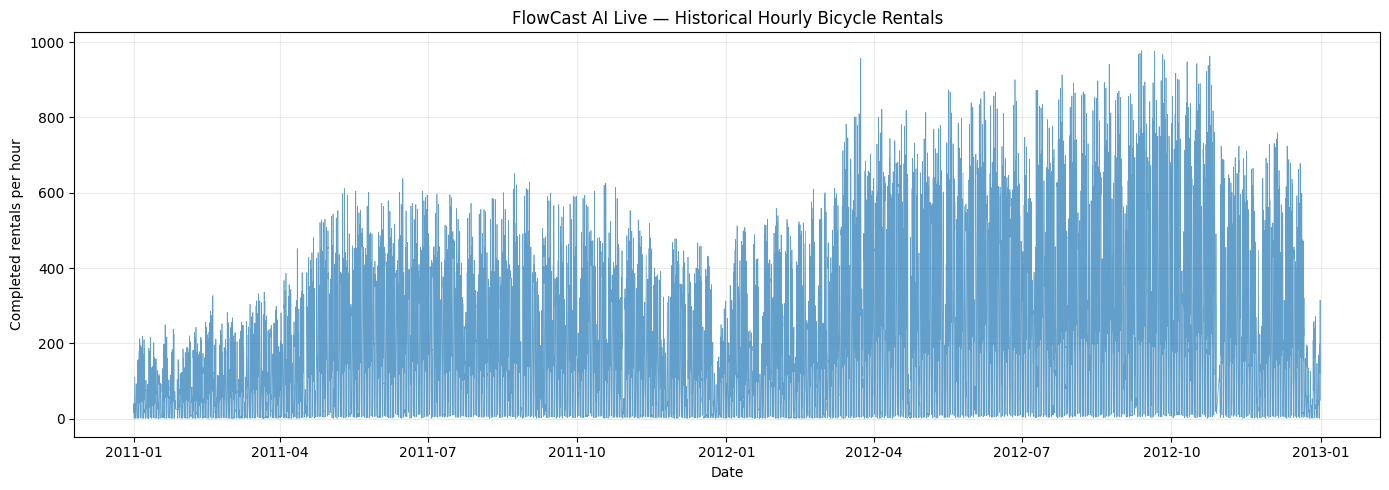

Graph saved successfully!


In [10]:
# DATA SECTION — SUMMARY AND RAW-DATA PLOT (FIXED)

import io
import zipfile
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Ensure hour.csv exists in ROOT / "data"
data_dir = ROOT / "data"
data_dir.mkdir(parents=True, exist_ok=True)
csv_path = data_dir / "hour.csv"

if not csv_path.exists():
    # First check if hour.csv exists anywhere else in the cloned repo
    existing = list(ROOT.rglob("hour.csv"))
    if existing:
        csv_path = existing[0]
        print(f"Found existing dataset at: {csv_path}")
    else:
        print("hour.csv not found locally. Downloading UCI Bike Sharing dataset...")
        url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as resp:
            with zipfile.ZipFile(io.BytesIO(resp.read())) as zf:
                zf.extract("hour.csv", path=data_dir)
        print(f"Downloaded and extracted to: {csv_path}")

# Load historical CSV
df = pd.read_csv(csv_path)

# Construct timestamps
df["datetime"] = (
    pd.to_datetime(df["dteday"])
    + pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("datetime").reset_index(drop=True)

# Display sample observations
print("DATASET PREVIEW")
display(df[["datetime", "cnt", "temp", "hum"]].head())

# Display dataset information
print("DATASET INFORMATION")
print("Total observations:", len(df))
print("First observation:", df["datetime"].min())
print("Last observation:", df["datetime"].max())
print("Missing target values:", df["cnt"].isna().sum())

# Summary statistics
print("\nSUMMARY STATISTICS")
display(
    df["cnt"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .to_frame("Recorded rentals/hour")
)

# Raw-data graph
plt.figure(figsize=(14, 5))

plt.plot(
    df["datetime"],
    df["cnt"],
    linewidth=0.5,
    alpha=0.7
)

plt.title("FlowCast AI Live — Historical Hourly Bicycle Rentals")
plt.xlabel("Date")
plt.ylabel("Completed rentals per hour")
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    ROOT / "fig" / "raw_rentals.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

## Split

Hold out data the model never sees. When the decision is about a later time, hold out a later time. Record the cutoff date, or the seed and the fraction, in `decisions.md`. Do not fit, scale, or choose features on the held-out rows.
Chronological: train before 2012-07-01; validation 2012-07-01 to 2012-09-30; test 2012-10-01 onward. Feature engineering uses only calendar values known ahead of time and prior observed counts; no future target-hour rental counts are used. Historical lag features assume the previous hour’s count is available at forecast time.


In [12]:

# ============================================================
# FLOWCAST AI LIVE — CHRONOLOGICAL DATA SPLIT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# ------------------------------------------------------------
# 1. Create a clean modeling dataset
# ------------------------------------------------------------
# Load raw dataset if not already defined
if "raw" not in globals():
    raw = pd.read_csv(ROOT / "data" / "hour.csv")
    raw["datetime"] = (
        pd.to_datetime(raw["dteday"])
        + pd.to_timedelta(raw["hr"], unit="h")
    )
    raw = raw.sort_values("datetime").reset_index(drop=True)
df = raw[["datetime", "cnt"]].copy()

df["datetime"] = pd.to_datetime(df["datetime"])
df = df.sort_values("datetime").reset_index(drop=True)

assert df["datetime"].is_unique
assert df["cnt"].notna().all()
assert (df["cnt"] >= 0).all()

# ------------------------------------------------------------
# 2. Calendar features known before the forecast hour
# ------------------------------------------------------------

df["hour"] = df["datetime"].dt.hour
df["dow"] = df["datetime"].dt.dayofweek
df["month"] = df["datetime"].dt.month
df["day_of_year"] = df["datetime"].dt.dayofyear

df["is_weekend"] = (df["dow"] >= 5).astype(int)

# Cyclical representations
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)

df["year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)
df["year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

# ------------------------------------------------------------
# 3. Construct timestamp-aligned historical lag features
# ------------------------------------------------------------

for hours, name in [
    (1, "lag1"),
    (24, "lag24"),
    (168, "lag168")
]:
    lag = df[["datetime", "cnt"]].copy()

    lag["datetime"] += pd.Timedelta(hours=hours)

    lag = lag.rename(columns={"cnt": name})

    df = df.merge(
        lag,
        on="datetime",
        how="left",
        validate="one_to_one"
    )

# Professor's named seasonal baseline
df["baseline_capacity"] = df["lag168"]

# ------------------------------------------------------------
# 4. Define the model predictors
# ------------------------------------------------------------

feature_cols = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "year_sin",
    "year_cos",
    "is_weekend",
    "lag1",
    "lag24",
    "lag168"
]

# Keep rows where all historical lag counts exist
df = df.dropna(subset=feature_cols).copy()

# ------------------------------------------------------------
# 5. Chronological train / validation / test split
# ------------------------------------------------------------

train = df[
    df["datetime"] < "2012-07-01"
].copy()

valid = df[
    (df["datetime"] >= "2012-07-01") &
    (df["datetime"] < "2012-10-01")
].copy()

test = df[
    df["datetime"] >= "2012-10-01"
].copy()

assert len(train) > 0
assert len(valid) > 0
assert len(test) > 0

assert train["datetime"].max() < valid["datetime"].min()
assert valid["datetime"].max() < test["datetime"].min()

# ------------------------------------------------------------
# 6. Create consistent statistical design matrices
# ------------------------------------------------------------

def design(frame, columns=None):

    x = frame[feature_cols].copy()

    # Stabilize the scale of historical rental counts
    for lag_name in ["lag1", "lag24", "lag168"]:
        x[lag_name] = np.log1p(x[lag_name])

    x = sm.add_constant(
        x,
        has_constant="add"
    )

    if columns is not None:
        x = x.reindex(
            columns=columns,
            fill_value=0.0
        )

    return x.astype(float)


Xtrain = design(train)
Xvalid = design(valid, Xtrain.columns)
Xtest = design(test, Xtrain.columns)

# ------------------------------------------------------------
# 7. Display the split summary
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Observations": [
        len(train),
        len(valid),
        len(test)
    ],
    "Start": [
        train["datetime"].min(),
        valid["datetime"].min(),
        test["datetime"].min()
    ],
    "End": [
        train["datetime"].max(),
        valid["datetime"].max(),
        test["datetime"].max()
    ],
    "Mean rentals/hour": [
        train["cnt"].mean(),
        valid["cnt"].mean(),
        test["cnt"].mean()
    ],
    "Std. rentals/hour": [
        train["cnt"].std(),
        valid["cnt"].std(),
        test["cnt"].std()
    ]
})

display(
    split_summary.round(2)
)

print("Training matrix:", Xtrain.shape)
print("Validation matrix:", Xvalid.shape)
print("Test matrix:", Xtest.shape)

print("\nChronological split verified.")
print("No target-hour rental counts used as predictors.")
print("Same-hour previous-week baseline retained.")


,Dataset,Observations,Start,End,Mean rentals/hour,Std. rentals/hour
0,Training,12591,2011-01-08,2012-06-30 23:00:00,171.87,161.37
1,Validation,2208,2012-07-01,2012-09-30 23:00:00,288.35,231.10
2,Test,2098,2012-10-01,2012-12-31 23:00:00,221.42,202.18


Training matrix: (12591, 11)
Validation matrix: (2208, 11)
Test matrix: (2098, 11)

Chronological split verified.
No target-hour rental counts used as predictors.
Same-hour previous-week baseline retained.


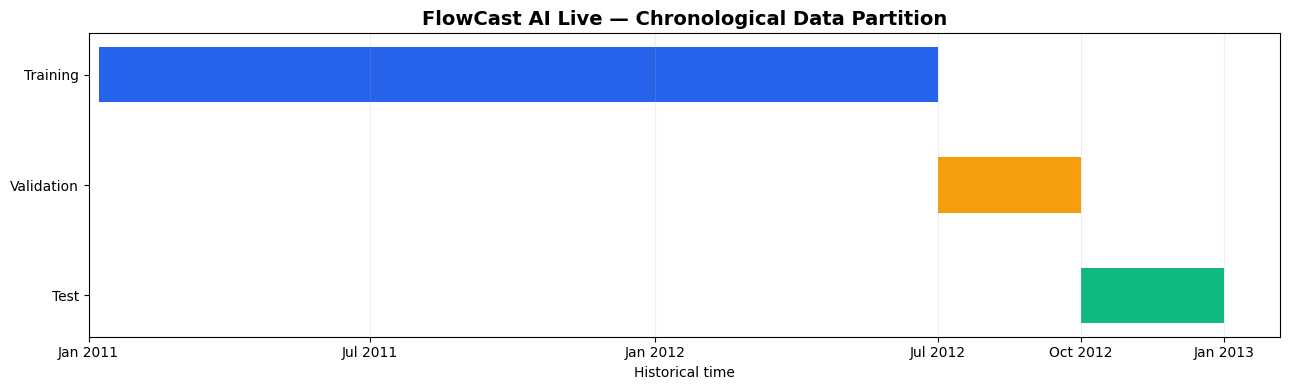

In [13]:

# ============================================================
# CHRONOLOGICAL SPLIT VISUALIZATION
# ============================================================

fig, ax = plt.subplots(figsize=(13, 4))

periods = [
    ("Training", train, "#2563EB"),
    ("Validation", valid, "#F59E0B"),
    ("Test", test, "#10B981")
]

for i, (name, subset, color) in enumerate(periods):

    ax.barh(
        y=i,
        width=(
            subset["datetime"].max()
            - subset["datetime"].min()
        ).total_seconds() / 86400,
        left=(
            subset["datetime"].min()
            - pd.Timestamp("2011-01-01")
        ).total_seconds() / 86400,
        height=0.5,
        color=color,
        label=name
    )

ax.set_yticks(range(3))
ax.set_yticklabels(["Training", "Validation", "Test"])
ax.invert_yaxis()

tick_dates = pd.to_datetime([
    "2011-01-01",
    "2011-07-01",
    "2012-01-01",
    "2012-07-01",
    "2012-10-01",
    "2013-01-01"
])

tick_positions = (
    tick_dates - pd.Timestamp("2011-01-01")
).days

ax.set_xticks(tick_positions)
ax.set_xticklabels(
    [d.strftime("%b %Y") for d in tick_dates]
)

ax.set_title(
    "FlowCast AI Live — Chronological Data Partition",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Historical time")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()

plt.savefig(
    ROOT / "fig" / "chronological_split.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [14]:

assert Xtrain.columns.equals(Xvalid.columns)
assert Xtrain.columns.equals(Xtest.columns)

assert Xtrain.notna().all().all()
assert Xvalid.notna().all().all()
assert Xtest.notna().all().all()

print("All design matrices have matching columns.")
print("No missing predictor values remain.")
print("Split section verification passed.")


All design matrices have matching columns.
No missing predictor values remain.
Split section verification passed.


## Baseline

A simple method: the mean, the last value, or a plain regression. Score it on the held-out data in the units of the decision.

## Baseline — Seasonal Naive Forecast

### Definition

The seasonal baseline uses the number of recorded bicycle rentals
from the same clock hour exactly seven days earlier as the
capacity target for the next hour.

The baseline decision rule is:

$$
\boxed{
q_t^{\mathrm{baseline}} = D_{t-168}
}
$$

where:

- $q_t^{\mathrm{baseline}}$ is the baseline capacity target for hour $t$.
- $D_{t-168}$ is the recorded rental count exactly 168 hours earlier.
- $D_t$ is the actual recorded rental count during hour $t$.

### Asymmetric Capacity-Planning Loss

The same loss function is applied to both the seasonal baseline
and the negative binomial forecasting model:

$$
\boxed{
L(q_t,D_t)
=
4\max(D_t-q_t,0)
+
\max(q_t-D_t,0)
}
$$

The shortage cost is four hypothetical units per rental,
while the excess-capacity cost is one hypothetical unit per rental.

The held-out baseline performance is measured by:

$$
\overline{L}_{\mathrm{baseline}}
=
\frac{1}{N_{\mathrm{test}}}
\sum_{t\in\mathcal{T}_{\mathrm{test}}}
L\left(q_t^{\mathrm{baseline}},D_t\right)
$$

where $N_{\mathrm{test}}$ is the number of evaluated test hours.

### Evaluation Protocol

The baseline requires no statistical model fitting.
It uses only historical rental counts available before the
forecast hour.

The baseline and negative binomial model are evaluated
on identical chronologically held-out observations using
the same asymmetric loss function.

**Decision criterion:** Lower average hypothetical loss
units per hour indicates a better capacity-planning decision.


SEASONAL BASELINE — VALIDATION AND HELD-OUT TEST


,Period,Observations,Mean loss (units/hour),MAE (rentals/hour),Mean shortage (rentals/hour),Shortage frequency
0,Validation,2208,144.399,55.998,29.467,0.495
1,Test,2098,149.752,69.564,26.729,0.433


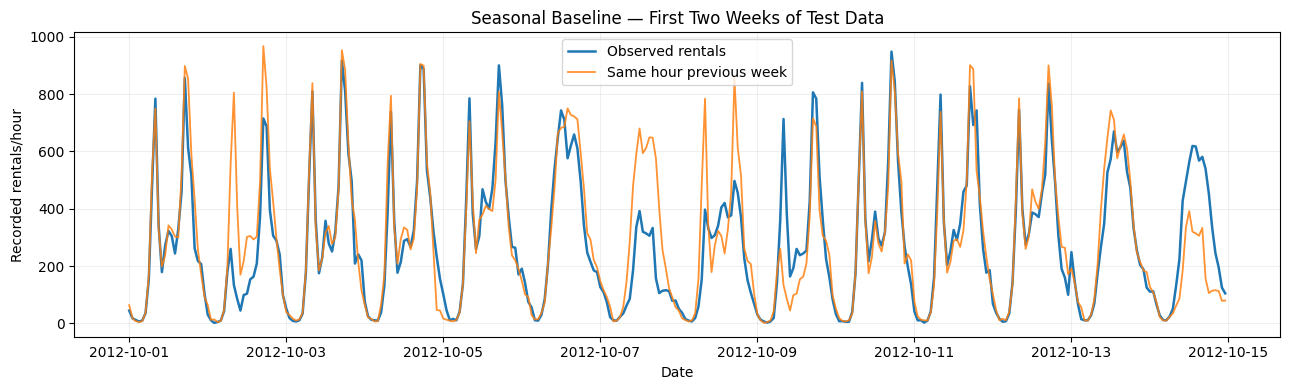

In [15]:

# ============================================================
# CELL 11 — SEASONAL BASELINE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ensure both evaluation periods contain valid baseline values
for name, frame in [("Validation", valid), ("Test", test)]:
    assert frame["baseline_capacity"].notna().all(), (
        f"{name} contains missing baseline values"
    )
    assert (frame["baseline_capacity"] >= 0).all()

    # Capacity must be an integer number of rentals
    frame["baseline_capacity"] = (
        frame["baseline_capacity"].astype(int)
    )

    # Professor's asymmetric decision loss
    frame["baseline_loss"] = decision_loss(
        frame["baseline_capacity"],
        frame["cnt"]
    )

    frame["baseline_error"] = (
        frame["cnt"] - frame["baseline_capacity"]
    )

# Summary of baseline performance
baseline_summary = pd.DataFrame({
    "Period": ["Validation", "Test"],
    "Observations": [len(valid), len(test)],
    "Mean loss (units/hour)": [
        valid["baseline_loss"].mean(),
        test["baseline_loss"].mean()
    ],
    "MAE (rentals/hour)": [
        valid["baseline_error"].abs().mean(),
        test["baseline_error"].abs().mean()
    ],
    "Mean shortage (rentals/hour)": [
        np.maximum(
            valid["cnt"] - valid["baseline_capacity"], 0
        ).mean(),
        np.maximum(
            test["cnt"] - test["baseline_capacity"], 0
        ).mean()
    ],
    "Shortage frequency": [
        (valid["cnt"] > valid["baseline_capacity"]).mean(),
        (test["cnt"] > test["baseline_capacity"]).mean()
    ]
})

print("SEASONAL BASELINE — VALIDATION AND HELD-OUT TEST")
display(baseline_summary.round(3))

# Plot a readable two-week test-period example
example = test.iloc[:24 * 14]

fig, ax = plt.subplots(figsize=(13, 4))

ax.plot(
    example["datetime"],
    example["cnt"],
    label="Observed rentals",
    linewidth=1.8
)

ax.plot(
    example["datetime"],
    example["baseline_capacity"],
    label="Same hour previous week",
    linewidth=1.3,
    alpha=0.85
)

ax.set_title("Seasonal Baseline — First Two Weeks of Test Data")
ax.set_xlabel("Date")
ax.set_ylabel("Recorded rentals/hour")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    ROOT / "fig" / "baseline_vs_observed.png",
    dpi=180,
    bbox_inches="tight"
)
plt.show()


## Model

Write the model as equations. Say what each parameter means, which assumption you trust least, and fit the model. Score it on the same held-out data, in the same units. State the uncertainty of the prediction.

The forecast target is the number of completed bicycle rentals during the next hour, measured in rentals/hour. A negative binomial regression models this nonnegative count while allowing the variance to exceed the conditional mean.


## Model — Negative Binomial Probabilistic Forecasting

### 1. Forecasting Objective

The objective is to predict the number of completed
Capital Bikeshare rentals during the next hour,
measured in rentals per hour.

A negative binomial regression is used because hourly
rental counts are nonnegative integers and may exhibit
overdispersion, meaning that their conditional variance
exceeds their conditional mean.

### 2. Negative Binomial Predictive Distribution

The next-hour rental count is modeled as:

$$
\boxed{
D_t \mid X_t
\sim
\operatorname{NB}(\mu_t,\alpha)
}
$$

where:

- $D_t$ is the recorded number of completed rentals in hour $t$.
- $X_t$ is the vector of predictors available before hour $t$.
- $\mu_t$ is the conditional expected number of rentals.
- $\alpha>0$ is the negative binomial dispersion parameter.

### 3. Conditional Mean Model

The expected rental count is linked to historical
predictors through a logarithmic link function:

$$
\boxed{
\log(\mu_t)=X_t^{\mathsf T}\beta
}
$$

Equivalently:

$$
\mu_t
=
\exp\left(X_t^{\mathsf T}\beta\right)
$$

Here, $\beta$ contains the regression coefficients
associated with calendar features and previously
observed rental counts.

### 4. Conditional Variance and Overdispersion

The NB2 variance structure is:

$$
\boxed{
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
}
$$

The additional term $\alpha\mu_t^2$ allows the
conditional variance to exceed the mean.

### 5. Capacity-Planning Decision Loss

The hypothetical decision maker chooses an integer
capacity target $q_t$ before observing $D_t$.

The asymmetric decision loss is:

$$
\boxed{
L(q_t,D_t)
=
4\max(D_t-q_t,0)
+
\max(q_t-D_t,0)
}
$$

The illustrative costs are:

$$
c_s=4,
\qquad
c_e=1
$$

Thus, the shortage-to-excess cost ratio is:

$$
\boxed{
\frac{c_s}{c_e}=4:1
}
$$

### 6. Decision-Optimal Predictive Quantile

For the stated loss function, the optimal
capacity is selected using the critical fractile:

$$
\tau
=
\frac{c_s}{c_s+c_e}
$$

Substituting the illustrative costs:

$$
\tau
=
\frac{4}{4+1}
=
0.80
$$

The capacity decision is therefore:

$$
\boxed{
q_t^*
=
F_{\operatorname{NB}}^{-1}
\left(0.80\mid\mu_t,\alpha\right)
}
$$

The resulting capacity is a nonnegative integer
representing the 80th percentile of the predicted
rental-count distribution.

**Quantile notation clarification:** The professor's
GitHub issue specifies $\tau=c_e/(c_s+c_e)$.
For the shortage and excess definitions used in the
loss function above, minimizing expected loss instead
gives $\tau=c_s/(c_s+c_e)$.

This difference remains documented pending clarification.

### 7. Model Training and Evaluation

The model is fitted using training observations
before July 1, 2012.

The evaluation periods are:

- **Training:** Before July 1, 2012.
- **Validation:** July 1–September 30, 2012.
- **Held-out test:** October 1–December 31, 2012.

The regression coefficients and dispersion parameter
are estimated using training data only.

Validation data supports model diagnostics, while
the final held-out test set measures out-of-sample
forecasting and capacity-decision performance.

### 8. Model Assumptions and Limitations

The least trusted assumption is that the conditional
relationship between historical rental counts,
calendar patterns, and future rentals remains
reasonably stable over time.

The model does not directly estimate unobserved
customer demand or customers who were unable
to obtain a bicycle.

It is a probabilistic count-regression model,
not a neural network.


In [16]:
# Discrete negative binomial estimates both coefficients and dispersion on training rows.
nbfit=sm.NegativeBinomial(train.cnt.to_numpy(),Xtrain,loglike_method='nb2').fit(disp=False,maxiter=300)
assert nbfit.mle_retvals.get('converged',False), 'NB did not converge: inspect diagnostics before reporting scores'
alpha=float(nbfit.params['alpha']);assert alpha>0
valid['nb_mean']=np.maximum(nbfit.predict(Xvalid),1e-6)
test['nb_mean']=np.maximum(nbfit.predict(Xtest),1e-6)
for frame in [valid,test]:
    frame['nb_capacity']=nb_quantile(frame.nb_mean,alpha)
    frame['nb_loss']=decision_loss(frame.nb_capacity,frame.cnt)
    size=1/alpha;p=size/(size+frame.nb_mean.to_numpy())
    frame['nb_lo']=nbinom.ppf(.05,size,p)
    frame['nb_hi']=nbinom.ppf(.95,size,p)
    frame['covered90']=((frame.cnt>=frame.nb_lo)&(frame.cnt<=frame.nb_hi))
print('NB alpha:',round(alpha,4),'Validation NB loss:',round(valid.nb_loss.mean(),3),'Validation baseline:',round(valid.baseline_loss.mean(),3))
comparison=pd.DataFrame({'Method':['Negative binomial','Same hour last week'],'Held-out mean loss (illustrative units/hour)':[test.nb_loss.mean(),test.baseline_loss.mean()]})
display(comparison)
print('Model wins/ties/loses hours:',int((test.nb_loss<test.baseline_loss).sum()),int((test.nb_loss==test.baseline_loss).sum()),int((test.nb_loss>test.baseline_loss).sum()))
print('NB 90% interval empirical coverage:',round(test.covered90.mean(),3))

NB alpha: 0.14 Validation NB loss: 124.01 Validation baseline: 144.399


,Method,Held-out mean loss (illustrative units/hour)
0,Negative binomial,105.600572
1,Same hour last week,149.751668


Model wins/ties/loses hours: 1014 22 1062
NB 90% interval empirical coverage: 0.91


In [17]:
# Confirm there are no duplicate forecast timestamps
for name, frame in [
    ("Training", train),
    ("Validation", valid),
    ("Test", test)
]:
    assert frame["datetime"].is_unique, (
        f"{name} contains duplicate timestamps"
    )

# Verify the exact chronological boundaries
assert (train["datetime"] < "2012-07-01").all()

assert (
    (valid["datetime"] >= "2012-07-01") &
    (valid["datetime"] < "2012-10-01")
).all()

assert (test["datetime"] >= "2012-10-01").all()

print("Timestamp uniqueness: PASSED")
print("Chronological boundaries: PASSED")

Timestamp uniqueness: PASSED
Chronological boundaries: PASSED


In [18]:

# CELL 2 — FIT AND EVALUATE NEGATIVE BINOMIAL REGRESSION

# Fit only on training observations
nbfit = sm.NegativeBinomial(
    train["cnt"].to_numpy(),
    Xtrain,
    loglike_method="nb2"
).fit(
    disp=False,
    maxiter=300
)

# Verify convergence
converged = bool(
    nbfit.mle_retvals.get("converged", False)
)

assert converged, (
    "NB model did not converge. Inspect diagnostics."
)

# Extract dispersion parameter
alpha = float(nbfit.params["alpha"])

assert np.isfinite(alpha) and alpha > 0

# Generate conditional mean predictions
valid["nb_mean"] = np.maximum(
    np.asarray(nbfit.predict(Xvalid), dtype=float),
    1e-6
)

test["nb_mean"] = np.maximum(
    np.asarray(nbfit.predict(Xtest), dtype=float),
    1e-6
)

# Verify predicted means
assert np.isfinite(valid["nb_mean"]).all()
assert np.isfinite(test["nb_mean"]).all()

# Evaluate both periods
for frame in [valid, test]:

    # Decision-optimal NB capacity
    frame["nb_capacity"] = nb_quantile(
        frame["nb_mean"],
        alpha,
        TAU
    )

    # Asymmetric decision loss
    frame["nb_loss"] = decision_loss(
        frame["nb_capacity"],
        frame["cnt"]
    )

    # Negative binomial parameters
    size = 1.0 / alpha

    p = size / (
        size + frame["nb_mean"].to_numpy()
    )

    # Central 90% predictive interval
    frame["nb_lo"] = nbinom.ppf(
        0.05,
        size,
        p
    )

    frame["nb_hi"] = nbinom.ppf(
        0.95,
        size,
        p
    )

    # Empirical interval coverage
    frame["covered90"] = (
        (frame["cnt"] >= frame["nb_lo"])
        &
        (frame["cnt"] <= frame["nb_hi"])
    )

# Compare model and baseline
comparison = pd.DataFrame({
    "Method": [
        "Negative binomial",
        "Same hour last week"
    ],
    "Validation mean loss (units/hour)": [
        valid["nb_loss"].mean(),
        valid["baseline_loss"].mean()
    ],
    "Held-out mean loss (units/hour)": [
        test["nb_loss"].mean(),
        test["baseline_loss"].mean()
    ]
})

print("=" * 65)
print("FLOWCAST AI LIVE — MODEL EVALUATION")
print("=" * 65)

print("Converged:", converged)
print("Estimated alpha:", round(alpha, 5))

print("\nVALIDATION AND HELD-OUT PERFORMANCE")
display(comparison.round(3))

# Paired held-out comparison
wins = int(
    (test["nb_loss"] < test["baseline_loss"]).sum()
)

ties = int(
    (test["nb_loss"] == test["baseline_loss"]).sum()
)

losses = int(
    (test["nb_loss"] > test["baseline_loss"]).sum()
)

print("\nMODEL WINS / TIES / LOSSES")
print(wins, "/", ties, "/", losses)

print(
    "\nNB 90% predictive interval coverage:",
    round(test["covered90"].mean(), 3)
)


FLOWCAST AI LIVE — MODEL EVALUATION
Converged: True
Estimated alpha: 0.14005

VALIDATION AND HELD-OUT PERFORMANCE


,Method,Validation mean loss (units/hour),Held-out mean loss (units/hour)
0,Negative binomial,124.010,105.601
1,Same hour last week,144.399,149.752



MODEL WINS / TIES / LOSSES
1014 / 22 / 1062

NB 90% predictive interval coverage: 0.91


In [19]:

# MODEL CHECK 1 — VERIFY INPUTS AND DECISION ASSUMPTIONS

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import nbinom

# Verify chronological order
assert train["datetime"].max() < valid["datetime"].min()
assert valid["datetime"].max() < test["datetime"].min()

# Verify matching design-matrix columns
assert Xtrain.columns.equals(Xvalid.columns)
assert Xtrain.columns.equals(Xtest.columns)

# Verify finite predictor values
assert np.isfinite(Xtrain.to_numpy()).all()
assert np.isfinite(Xvalid.to_numpy()).all()
assert np.isfinite(Xtest.to_numpy()).all()

# Verify nonnegative integer rental counts
for frame in [train, valid, test]:
    assert frame["cnt"].notna().all()
    assert (frame["cnt"] >= 0).all()
    assert np.all(
        frame["cnt"].to_numpy()
        == np.floor(frame["cnt"].to_numpy())
    )

# Verify baseline evaluation already exists
assert "baseline_loss" in valid.columns
assert "baseline_loss" in test.columns

# Verify decision costs
assert C_SHORT == 4.0
assert C_EXCESS == 1.0
assert np.isclose(TAU, 0.8)

print("MODEL INPUT VERIFICATION")
print("Chronological split: PASSED")
print("Predictor alignment: PASSED")
print("Nonnegative count target: PASSED")
print("Baseline availability: PASSED")
print("Decision quantile:", TAU)
print("Training observations:", len(train))
print("Validation observations:", len(valid))
print("Test observations:", len(test))


MODEL INPUT VERIFICATION
Chronological split: PASSED
Predictor alignment: PASSED
Nonnegative count target: PASSED
Baseline availability: PASSED
Decision quantile: 0.8
Training observations: 12591
Validation observations: 2208
Test observations: 2098


In [20]:
nbfit = sm.NegativeBinomial(
    train.cnt.to_numpy(),
    Xtrain,
    loglike_method="nb2"
).fit(disp=False, maxiter=300)

In [21]:

# DISPLAY NEGATIVE BINOMIAL MODEL RESULTS

from IPython.display import display

print("=" * 65)
print("FLOWCAST AI LIVE — NEGATIVE BINOMIAL REGRESSION")
print("=" * 65)

# Display the complete statistical model summary
display(nbfit.summary())

# Check convergence
converged = nbfit.mle_retvals.get("converged", False)

print("\nMODEL DIAGNOSTICS")
print("Converged:", converged)
print("Training observations:", len(train))
print("Number of predictors:", Xtrain.shape[1])
print("Log-likelihood:", round(nbfit.llf, 3))
print("AIC:", round(nbfit.aic, 3))

# Estimated dispersion parameter
alpha = float(nbfit.params["alpha"])

print("\nNEGATIVE BINOMIAL DISPERSION")
print("Estimated alpha:", round(alpha, 5))

if alpha > 0:
    print("Positive dispersion: YES")

if converged:
    print("\nModel fitting completed successfully.")
else:
    print("\nWARNING: Model did not converge.")
    print("Do not interpret its estimates until investigated.")


FLOWCAST AI LIVE — NEGATIVE BINOMIAL REGRESSION


<class 'statsmodels.iolib.summary.Summary'>
"""
                     NegativeBinomial Regression Results                      
==============================================================================
Dep. Variable:                      y   No. Observations:                12591
Model:               NegativeBinomial   Df Residuals:                    12580
Method:                           MLE   Df Model:                           10
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:                  0.1769
Time:                        23:42:24   Log-Likelihood:                -63688.
converged:                       True   LL-Null:                       -77375.
Covariance Type:            nonrobust   LLR p-value:                     0.000
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0962      0.023      4.250      0.000       0.052       0.141
hour_sin       0.1264      0.007     18.382      0.000       0.113       0.140
hour_cos      -0.1292      0.006    -19.963      0.000      -0.142      -0.117
dow_sin       -0.0188      0.008     -2.231      0.026      -0.035      -0.002
dow_cos        0.0136      0.005      2.582      0.010       0.003       0.024
year_sin       0.0208      0.005      4.002      0.000       0.011       0.031
year_cos       0.0093      0.005      1.696      0.090      -0.001       0.020
is_weekend    -0.0575      0.013     -4.318      0.000      -0.084      -0.031
lag1           0.4460      0.005     82.715      0.000       0.435       0.457
lag24          0.1887      0.005     36.929      0.000       0.179       0.199
lag168         0.3640      0.005     67.000      0.000       0.353       0.375
alpha          0.1400      0.002     68.696      0.000       0.136       0.144
==============================================================================
"""


MODEL DIAGNOSTICS
Converged: True
Training observations: 12591
Number of predictors: 11
Log-likelihood: -63688.256
AIC: 127400.512

NEGATIVE BINOMIAL DISPERSION
Estimated alpha: 0.14005
Positive dispersion: YES

Model fitting completed successfully.


In [22]:
# Detailed parameter table
parameter_table = pd.DataFrame({
    "Coefficient": nbfit.params,
    "Standard error": nbfit.bse,
    "P-value": nbfit.pvalues
})

print("\nNEGATIVE BINOMIAL PARAMETER ESTIMATES")
display(parameter_table.round(5))


NEGATIVE BINOMIAL PARAMETER ESTIMATES


,Coefficient,Standard error,P-value
const,0.09619,0.02263,0.00002
hour_sin,0.12640,0.00688,0.00000
hour_cos,-0.12920,0.00647,0.00000
dow_sin,-0.01877,0.00841,0.02566
dow_cos,0.01359,0.00526,0.00983
year_sin,0.02082,0.00520,0.00006
year_cos,0.00925,0.00545,0.08983
is_weekend,-0.05746,0.01331,0.00002
lag1,0.44596,0.00539,0.00000
lag24,0.18869,0.00511,0.00000


In [23]:

# CELL 4 — DISPLAY FIRST 10 MODEL PREDICTIONS

from IPython.display import display

# Ensure the model converged
assert nbfit.mle_retvals.get("converged", False)

# Validation predictions
validation_preview = valid[
    [
        "datetime",
        "cnt",
        "nb_mean",
        "nb_capacity",
        "nb_loss",
        "nb_lo",
        "nb_hi"
    ]
].head(10).copy()

validation_preview.columns = [
    "Date and time",
    "Actual rentals",
    "Predicted mean",
    "Recommended capacity",
    "Decision loss",
    "90% lower bound",
    "90% upper bound"
]

print("=" * 65)
print("FIRST 10 VALIDATION PREDICTIONS")
print("=" * 65)

display(validation_preview.round(2))

# Held-out test predictions
test_preview = test[
    [
        "datetime",
        "cnt",
        "nb_mean",
        "nb_capacity",
        "nb_loss",
        "nb_lo",
        "nb_hi"
    ]
].head(10).copy()

test_preview.columns = [
    "Date and time",
    "Actual rentals",
    "Predicted mean",
    "Recommended capacity",
    "Decision loss",
    "90% lower bound",
    "90% upper bound"
]

print("\n" + "=" * 65)
print("FIRST 10 HELD-OUT TEST PREDICTIONS")
print("=" * 65)

display(test_preview.round(2))


FIRST 10 VALIDATION PREDICTIONS


,Date and time,Actual rentals,Predicted mean,Recommended capacity,Decision loss,90% lower bound,90% upper bound
13003,2012-07-01 00:00:00,149,124.53,162,13.0,57.0,212.0
13004,2012-07-01 01:00:00,93,113.34,148,55.0,52.0,193.0
13005,2012-07-01 02:00:00,90,93.29,122,32.0,42.0,160.0
13006,2012-07-01 03:00:00,33,63.95,84,51.0,28.0,110.0
13007,2012-07-01 04:00:00,4,24.19,32,28.0,10.0,43.0
13008,2012-07-01 05:00:00,10,8.26,12,2.0,2.0,16.0
13009,2012-07-01 06:00:00,27,23.19,31,4.0,9.0,41.0
13010,2012-07-01 07:00:00,50,60.70,80,30.0,27.0,105.0
13011,2012-07-01 08:00:00,142,118.96,155,13.0,54.0,203.0
13012,2012-07-01 09:00:00,219,242.50,315,96.0,113.0,411.0



FIRST 10 HELD-OUT TEST PREDICTIONS


,Date and time,Actual rentals,Predicted mean,Recommended capacity,Decision loss,90% lower bound,90% upper bound
15211,2012-10-01 00:00:00,45,68.93,90,45.0,31.0,118.0
15212,2012-10-01 01:00:00,18,39.44,52,34.0,17.0,69.0
15213,2012-10-01 02:00:00,12,20.26,27,15.0,8.0,36.0
15214,2012-10-01 03:00:00,7,14.19,19,12.0,5.0,26.0
15215,2012-10-01 04:00:00,10,9.52,13,3.0,3.0,18.0
15216,2012-10-01 05:00:00,36,20.57,28,32.0,8.0,37.0
15217,2012-10-01 06:00:00,155,72.58,95,240.0,33.0,125.0
15218,2012-10-01 07:00:00,483,256.40,333,600.0,120.0,434.0
15219,2012-10-01 08:00:00,784,583.62,756,112.0,275.0,985.0
15220,2012-10-01 09:00:00,340,613.60,795,455.0,289.0,1036.0


In [24]:

# CELL 5 — MATHEMATICAL MODEL CONSISTENCY

# Extract regression coefficients
beta = nbfit.params.drop("alpha")

# Verify the log-link mean equation
mu_equation = np.exp(
    Xtest.to_numpy() @ beta.to_numpy()
)

assert np.allclose(
    np.maximum(mu_equation, 1e-6),
    test["nb_mean"].to_numpy(),
    rtol=1e-5,
    atol=1e-6
)

# Calculate the NB2 variance
test["nb_variance"] = (
    test["nb_mean"]
    + alpha * test["nb_mean"] ** 2
)

test["nb_std"] = np.sqrt(
    test["nb_variance"]
)

print("LOG-LINK MEAN EQUATION: VERIFIED")
print("NB2 VARIANCE FORMULA: CALCULATED")

print("\nFIRST 10 TEST DISTRIBUTION MOMENTS")
display(
    test[
        [
            "datetime",
            "nb_mean",
            "nb_variance",
            "nb_std"
        ]
    ].head(10).round(3)
)


LOG-LINK MEAN EQUATION: VERIFIED
NB2 VARIANCE FORMULA: CALCULATED

FIRST 10 TEST DISTRIBUTION MOMENTS


,datetime,nb_mean,nb_variance,nb_std
15211,2012-10-01 00:00:00,68.926,734.266,27.097
15212,2012-10-01 01:00:00,39.439,257.275,16.040
15213,2012-10-01 02:00:00,20.258,77.731,8.817
15214,2012-10-01 03:00:00,14.191,42.392,6.511
15215,2012-10-01 04:00:00,9.521,22.215,4.713
15216,2012-10-01 05:00:00,20.565,79.797,8.933
15217,2012-10-01 06:00:00,72.578,810.287,28.466
15218,2012-10-01 07:00:00,256.397,9463.106,97.278
15219,2012-10-01 08:00:00,583.620,48285.919,219.741
15220,2012-10-01 09:00:00,613.602,53342.971,230.961


## Simulation check

Draw data from the model with known parameters and compare it with the real data. If the fit can recover those parameters, show that it does.


The simulation evaluates whether the negative binomial estimation procedure can recover parameters from data generated under known conditions.

First, 3,000 synthetic hourly counts are generated from a negative binomial distribution with known mean \(\mu=120\) and dispersion \(\alpha=0.3\). A constant-only negative binomial model is fitted to recover these values.

The experiment is repeated across independent simulated datasets to examine estimation variability rather than relying on a single random draw.

Second, the trained regression model generates synthetic counts conditional on the historical held-out predictors. Comparing their distribution with observed test counts provides a model-checking diagnostic. This is a predictive simulation, not evidence of present-day operational accuracy.

All random experiments use the recorded seed `20261112` for reproducibility.



# Simulation Check — FlowCast AI Live

## Purpose and Statistical Motivation

FlowCast AI Live evaluates a negative binomial (NB2) predictive model for risk-aware hourly bicycle-sharing capacity planning using historical completed rental counts.

Rather than producing only a point forecast, the model estimates the conditional probability distribution:

$$
\boxed{
D_t\mid X_t\sim\operatorname{NB2}(\mu_t,\alpha)
}
$$

where $D_t$ denotes completed rentals during hour $t$, $X_t$ is the predictor vector, $\mu_t$ is the conditional expected rental count, and $\alpha>0$ is the overdispersion parameter.

The model assumes:

$$
\mathbb{E}[D_t\mid X_t]=\mu_t
$$

$$
\operatorname{Var}(D_t\mid X_t)
=\mu_t+\alpha\mu_t^2
$$

The simulation check addresses two distinct statistical questions:

1. **Known-parameter recovery:** Can the NB2 estimation procedure recover known generating parameters from synthetic observations under correctly specified conditions?

2. **Held-out predictive simulation:** Can the fitted FlowCast AI Live regression reproduce selected distributional characteristics of historical held-out hourly rental counts?

These experiments assess estimation reliability and historical predictive adequacy separately.

---

## Experiment 1 — Known-Parameter Recovery

### 1.1 Data-Generating Process

Generate $n=3000$ independent synthetic hourly rental counts:

$$
\boxed{
D_i^{\mathrm{sim}}
\overset{\mathrm{iid}}{\sim}
\operatorname{NB2}(\mu_0,\alpha_0),
\qquad i=1,\ldots,3000
}
$$

with known generating parameters:

$$
\boxed{
\mu_0=120,\qquad \alpha_0=0.3
}
$$

The theoretical expected count is:

$$
\mathbb{E}[D_i^{\mathrm{sim}}]=\mu_0=120
$$

Under the NB2 parameterization, the theoretical variance is:

$$
\begin{aligned}
\operatorname{Var}(D_i^{\mathrm{sim}})
&=\mu_0+\alpha_0\mu_0^2\\
&=120+0.3(120)^2\\
&=120+4320\\
&=\boxed{4440}
\end{aligned}
$$

The corresponding standard deviation is:

$$
\boxed{
\sigma_0=\sqrt{4440}\approx66.63
}
$$

The variance-to-mean ratio is:

$$
\begin{aligned}
\frac{\operatorname{Var}(D)}{\mathbb{E}[D]}
&=\frac{\mu_0+\alpha_0\mu_0^2}{\mu_0}\\
&=1+\alpha_0\mu_0\\
&=1+(0.3)(120)\\
&=\boxed{37}
\end{aligned}
$$

Since the variance-to-mean ratio exceeds one, the generating process exhibits substantial overdispersion relative to a Poisson distribution.

### 1.2 NB2 Parameter Conversion

SciPy implements the negative binomial distribution using a shape-probability representation.

The shape parameter is:

$$
r_0=\frac{1}{\alpha_0}
$$

Therefore:

$$
\boxed{
r_0=\frac{1}{0.3}
=\frac{10}{3}
\approx3.3333
}
$$

The probability parameter is:

$$
p_0=\frac{r_0}{r_0+\mu_0}
$$

Equivalently:

$$
p_0=\frac{1}{1+\alpha_0\mu_0}
$$

Substituting the known parameters:

$$
\begin{aligned}
p_0
&=\frac{1}{1+(0.3)(120)}\\
&=\frac{1}{37}\\
&\approx\boxed{0.02703}
\end{aligned}
$$

Consequently:

$$
\boxed{
D_i^{\mathrm{sim}}
\sim
\operatorname{NB}
\left(
\frac{10}{3},
\frac{1}{37}
\right)
}
$$

The probability mass function is:

$$
P(D_i=d)
=
\frac{\Gamma(d+r_0)}
{\Gamma(r_0)\Gamma(d+1)}
p_0^{r_0}(1-p_0)^d
$$

where:

$$
d\in\{0,1,2,\ldots\}
$$

This conversion preserves the NB2 mean and variance.

### 1.3 Constant-Only Negative Binomial Estimation

Fit a constant-only NB2 regression to the synthetic observations:

$$
\boxed{
\log(\mu_i)=\beta_0
}
$$

Therefore:

$$
\mu_i=\exp(\beta_0)
$$

The recovered conditional mean is:

$$
\boxed{
\widehat{\mu}
=
\exp(\widehat{\beta}_0)
}
$$

The estimated dispersion parameter is:

$$
\boxed{
\widehat{\alpha}
=
\widehat{\alpha}_{\mathrm{NB2}}
}
$$

The known true intercept is:

$$
\begin{aligned}
\beta_{0,\mathrm{true}}
&=\log(\mu_0)\\
&=\log(120)\\
&\approx\boxed{4.78749}
\end{aligned}
$$

The estimation procedure maximizes the NB2 log-likelihood:

$$
\boxed{
(\widehat{\beta}_0,\widehat{\alpha})
=
\underset{\beta_0\in\mathbb R,\ \alpha>0}
{\operatorname{arg\,max}}
\sum_{i=1}^{n}
\log P(D_i^{\mathrm{sim}}\mid\beta_0,\alpha)
}
$$

The parameter-recovery targets are:

$$
\boxed{
\widehat{\mu}\approx120,
\qquad
\widehat{\alpha}\approx0.3
}
$$

### 1.4 Single-Sample Recovery Errors

The signed mean estimation error is:

$$
e_\mu=\widehat{\mu}-\mu_0
=\widehat{\mu}-120
$$

The signed dispersion estimation error is:

$$
e_\alpha=\widehat{\alpha}-\alpha_0
=\widehat{\alpha}-0.3
$$

Absolute errors are:

$$
\boxed{
AE_\mu=|\widehat{\mu}-120|
}
$$

$$
\boxed{
AE_\alpha=|\widehat{\alpha}-0.3|
}
$$

Relative percentage errors are:

$$
\boxed{
RE_\mu=
\frac{|\widehat{\mu}-120|}{120}\times100\%
}
$$

$$
\boxed{
RE_\alpha=
\frac{|\widehat{\alpha}-0.3|}{0.3}\times100\%
}
$$

Smaller absolute and relative errors indicate closer recovery of the known generating parameters.

### 1.5 Repeated Monte Carlo Recovery

Repeat the parameter-recovery experiment across:

$$
\boxed{
R_{\mathrm{attempted}}=100
}
$$

independent datasets, each containing:

$$
n=3000
$$

synthetic observations.

For successfully converged replication $j$, estimate:

$$
\widehat{\boldsymbol{\theta}}_j
=
\begin{pmatrix}
\widehat{\mu}_j\\
\widehat{\alpha}_j
\end{pmatrix}
$$

Let $R$ denote the number of successfully converged fits, with:

$$
1\leq R\leq100
$$

The empirical mean estimate for parameter $\theta\in\{\mu,\alpha\}$ is:

$$
\boxed{
\overline{\widehat{\theta}}
=
\frac{1}{R}
\sum_{j=1}^{R}
\widehat{\theta}_j
}
$$

Empirical bias is:

$$
\boxed{
\operatorname{Bias}(\widehat{\theta})
=
\frac{1}{R}
\sum_{j=1}^{R}
(\widehat{\theta}_j-\theta_0)
}
$$

The empirical variance is:

$$
\boxed{
\widehat{\operatorname{Var}}(\widehat{\theta})
=
\frac{1}{R-1}
\sum_{j=1}^{R}
\left(
\widehat{\theta}_j-
\overline{\widehat{\theta}}
\right)^2
}
$$

The empirical standard deviation is:

$$
\boxed{
SD(\widehat{\theta})
=
\sqrt{
\widehat{\operatorname{Var}}(\widehat{\theta})
}
}
$$

The root mean squared error is:

$$
\boxed{
\operatorname{RMSE}(\widehat{\theta})
=
\sqrt{
\frac{1}{R}
\sum_{j=1}^{R}
(\widehat{\theta}_j-\theta_0)^2
}
}
$$

For the mean parameter:

$$
\boxed{
\operatorname{RMSE}(\widehat{\mu})
=
\sqrt{
\frac{1}{R}
\sum_{j=1}^{R}
(\widehat{\mu}_j-120)^2
}
}
$$

For the dispersion parameter:

$$
\boxed{
\operatorname{RMSE}(\widehat{\alpha})
=
\sqrt{
\frac{1}{R}
\sum_{j=1}^{R}
(\widehat{\alpha}_j-0.3)^2
}
}
$$

The convergence rate is:

$$
\boxed{
CR=
\frac{R}{R_{\mathrm{attempted}}}
\times100\%
=
\frac{R}{100}\times100\%
}
$$

Attempted and successfully converged fits are reported separately.

Bias, standard deviation, and RMSE are computed from successfully converged fits. The empirical standard deviation requires at least two successful fits.

These experiments evaluate finite-sample estimation performance at $n=3000$. They do not independently establish asymptotic consistency as sample size increases.

---

## Experiment 2 — Held-Out Predictive Simulation

### 2.1 Trained FlowCast AI Live Regression

The main negative binomial regression was previously estimated using training observations only.

For historical held-out hour $t$:

$$
\boxed{
\log(\widehat{\mu}_t)
=
X_t^{\mathsf T}\widehat{\boldsymbol{\beta}}
}
$$

Equivalently:

$$
\boxed{
\widehat{\mu}_t
=
\exp\left(
X_t^{\mathsf T}\widehat{\boldsymbol{\beta}}
\right)
}
$$

The fitted conditional variance is:

$$
\boxed{
\widehat{\operatorname{Var}}(D_t\mid X_t)
=
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
$$

The fitted dispersion parameter captures additional count variability beyond the Poisson mean-variance relationship.

### 2.2 Conditional Predictive Simulation

Generate:

$$
\boxed{
B=500
}
$$

synthetic predictive trajectories conditional on historical held-out predictors and previously fitted model parameters.

For held-out hour $t$ and simulation replication $b$:

$$
\boxed{
D_t^{(b)}
\mid X_t,\widehat{\boldsymbol{\beta}},
\widehat{\alpha}
\sim
\operatorname{NB2}
(\widehat{\mu}_t,\widehat{\alpha})
}
$$

where:

$$
b=1,\ldots,500
$$

The corresponding SciPy parameters are:

$$
\boxed{
\widehat r=\frac{1}{\widehat{\alpha}}
}
$$

and:

$$
\begin{aligned}
\widehat p_t
&=\frac{\widehat r}
{\widehat r+\widehat{\mu}_t}\\
&=\boxed{
\frac{1}
{1+\widehat{\alpha}\widehat{\mu}_t}
}
\end{aligned}
$$

Therefore:

$$
D_t^{(b)}
\sim
\operatorname{NB}
(\widehat r,\widehat p_t)
$$

For $m$ held-out hours, the simulation matrix is:

$$
\boxed{
\mathbf D^{\mathrm{sim}}
=
\begin{bmatrix}
D_1^{(1)} & \cdots & D_m^{(1)}\\
D_1^{(2)} & \cdots & D_m^{(2)}\\
\vdots & \ddots & \vdots\\
D_1^{(500)} & \cdots & D_m^{(500)}
\end{bmatrix}
\in\mathbb N_0^{500\times m}
}
$$

Each trajectory contains one synthetic count for every historical held-out hour.

Conditional independence across hours is assumed in this simulation. Consequently, the generated trajectories do not reproduce residual temporal dependence that may remain after conditioning on the predictors.

### 2.3 Distributional Comparison

The observed historical held-out counts are:

$$
\mathbf D^{\mathrm{obs}}
=
(D_1^{\mathrm{obs}},\ldots,D_m^{\mathrm{obs}})
$$

The observed sample mean is:

$$
\boxed{
\overline D_{\mathrm{obs}}
=
\frac{1}{m}
\sum_{t=1}^{m}D_t^{\mathrm{obs}}
}
$$

For simulation replication $b$, the simulated sample mean is:

$$
\boxed{
\overline D_{\mathrm{sim}}^{(b)}
=
\frac{1}{m}
\sum_{t=1}^{m}D_t^{(b)}
}
$$

The observed sample variance is:

$$
\boxed{
s_{\mathrm{obs}}^2
=
\frac{1}{m-1}
\sum_{t=1}^{m}
\left(
D_t^{\mathrm{obs}}
-
\overline D_{\mathrm{obs}}
\right)^2
}
$$

The simulated sample variance is:

$$
\boxed{
s_{\mathrm{sim},b}^2
=
\frac{1}{m-1}
\sum_{t=1}^{m}
\left(
D_t^{(b)}
-
\overline D_{\mathrm{sim}}^{(b)}
\right)^2
}
$$

The corresponding standard deviations are:

$$
s_{\mathrm{obs}}
=
\sqrt{s_{\mathrm{obs}}^2}
$$

$$
s_{\mathrm{sim},b}
=
\sqrt{s_{\mathrm{sim},b}^2}
$$

Empirical quantiles are compared at:

$$
\boxed{
q\in
\{0.05,0.25,0.50,0.75,0.95\}
}
$$

The observed empirical quantile is:

$$
Q_q^{\mathrm{obs}}
=
Q_q(\mathbf D^{\mathrm{obs}})
$$

For simulation replication $b$:

$$
Q_q^{(b)}
=
Q_q(\mathbf D_{\mathrm{sim}}^{(b)})
$$

Comparisons include means, variances, standard deviations, quantiles, and overlaid empirical count histograms.

The marginal variance across historical held-out hours reflects both within-hour NB2 variability and variation in the conditional means.

For a randomly selected held-out hour $T$:

$$
\boxed{
\operatorname{Var}(D_T)
=
\mathbb E_T
\left[
\mu_T+\alpha\mu_T^2
\right]
+
\operatorname{Var}_T(\mu_T)
}
$$

The first component represents average conditional count variance, while the second represents variation in expected rental counts across hours.

### 2.4 Simulation-Based Reference Intervals

For any summary statistic $T$, calculate its value separately for each simulated trajectory:

$$
T^{(1)},T^{(2)},\ldots,T^{(500)}
$$

The central 95% simulation-based reference interval is:

$$
\boxed{
I_T^{95\%}
=
\left[
Q_{0.025}(T^{(1:B)}),
Q_{0.975}(T^{(1:B)})
\right]
}
$$

The observed statistic is:

$$
T_{\mathrm{obs}}
=
T(\mathbf D^{\mathrm{obs}})
$$

The diagnostic evaluates whether:

$$
\boxed{
T_{\mathrm{obs}}\in I_T^{95\%}
}
$$

An observed statistic outside the reference interval indicates disagreement for that particular diagnostic under the fitted model's simulation assumptions.

These reference intervals represent variability in simulated statistics conditional on the fitted model. They are not confidence intervals for unknown population parameters.

### 2.5 Hourly Predictive Intervals and Coverage

For each held-out hour, calculate the lower and upper quantiles of the fitted negative binomial predictive distribution.

The central 95% predictive interval is:

$$
L_t^{95}
=
F_{\mathrm{NB}}^{-1}
\left(
0.025;
\widehat{\mu}_t,
\widehat{\alpha}
\right)
$$

$$
U_t^{95}
=
F_{\mathrm{NB}}^{-1}
\left(
0.975;
\widehat{\mu}_t,
\widehat{\alpha}
\right)
$$

Therefore:

$$
\boxed{
PI_t^{95\%}
=
[L_t^{95},U_t^{95}]
}
$$

The empirical held-out 95% coverage is:

$$
\boxed{
\widehat C_{95}
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t^{95}
\leq D_t^{\mathrm{obs}}
\leq U_t^{95}
\right)
}
$$

For consistency with the preceding model evaluation, also calculate the central 90% predictive interval:

$$
L_t^{90}
=
F_{\mathrm{NB}}^{-1}
\left(
0.05;
\widehat{\mu}_t,
\widehat{\alpha}
\right)
$$

$$
U_t^{90}
=
F_{\mathrm{NB}}^{-1}
\left(
0.95;
\widehat{\mu}_t,
\widehat{\alpha}
\right)
$$

Thus:

$$
\boxed{
PI_t^{90\%}
=
[L_t^{90},U_t^{90}]
}
$$

The empirical 90% held-out coverage is:

$$
\boxed{
\widehat C_{90}
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t^{90}
\leq D_t^{\mathrm{obs}}
\leq U_t^{90}
\right)
}
$$

Nominal coverage levels are compared with empirical held-out coverage.

Because the predictive distribution is discrete, central predictive intervals may exhibit coverage above their nominal levels.

These intervals are conditional on fitted parameters and do not incorporate parameter-estimation uncertainty.

---

## Statistical Interpretation and Limitations

### Experiment 1 — Estimation Reliability

The first experiment evaluates whether the NB2 estimation procedure can recover the known generating parameters:

$$
\boxed{
\boldsymbol{\theta}_0
=
\begin{pmatrix}
120\\
0.3
\end{pmatrix}
}
$$

using the recovered estimates:

$$
\widehat{\boldsymbol{\theta}}
=
\begin{pmatrix}
\widehat{\mu}\\
\widehat{\alpha}
\end{pmatrix}
$$

Estimation accuracy is assessed through:

$$
\boxed{
\operatorname{Bias}(\widehat{\theta}),
\quad
SD(\widehat{\theta}),
\quad
\operatorname{RMSE}(\widehat{\theta}),
\quad
CR
}
$$

The experiment evaluates finite-sample recovery under a correctly specified NB2 generating process.

### Experiment 2 — Historical Predictive Adequacy

The second experiment evaluates whether the fitted regression reproduces selected statistical characteristics of historical held-out observations.

The examined properties include:

$$
\boxed{
\mathbb E[D_t\mid X_t],
\quad
\operatorname{Var}(D_t\mid X_t),
\quad
Q_q(D_t\mid X_t)
}
$$

alongside empirical summary statistics and predictive interval coverage.

Agreement with historical observations provides evidence of predictive adequacy for the examined diagnostics but does not prove that the actual rental data follow an NB2 distribution.

### Model Limitations

The simulations condition on the fitted parameters:

$$
\widehat{\boldsymbol{\beta}},
\qquad
\widehat{\alpha}
$$

and the recorded historical predictors:

$$
X_t
$$

They do not incorporate:

- Parameter-estimation uncertainty.
- Residual temporal dependence between rental hours.
- Distribution shifts between historical and future observations.
- Changes in present-day bicycle-sharing operations.
- Unobserved demand beyond completed rentals.
- Realized operational or financial outcomes.

Consequently:

$$
\boxed{
\text{Historical Predictive Agreement}
\not\Rightarrow
\text{Present-Day Operational Accuracy}
}
$$

Likewise:

$$
\boxed{
\text{Predictive Model Fit}
\not\Rightarrow
\text{Realized Capacity Savings}
}
$$

The main decision evaluation remains the held-out comparison of asymmetric capacity loss against the same-hour previous-week baseline.

The simulation experiments complement that evaluation but do not replace it.

---

## Reproducibility

All random experiments use the recorded master seed:

$$
\boxed{
S_{\mathrm{master}}=20261112
}
$$

Independent pseudo-random streams are derived from this seed for the known-parameter recovery and held-out predictive simulation experiments.

The experimental configuration is:

$$
\boxed{
\begin{aligned}
n_{\mathrm{recovery}}&=3000\\
R_{\mathrm{attempted}}&=100\\
B_{\mathrm{predictive}}&=500\\
S_{\mathrm{master}}&=20261112
\end{aligned}
}
$$

The random seed, negative binomial parameterization, simulation counts, software versions, and convergence outcomes are recorded to support reproducibility.

---

## Analytical Objective

The two experiments provide complementary statistical evidence:

$$
\boxed{
\begin{aligned}
\text{Experiment 1}
&\longrightarrow
\text{Estimation Reliability}\\[6pt]
\text{Experiment 2}
&\longrightarrow
\text{Historical Predictive Adequacy}
\end{aligned}
}
$$

Experiment 1 measures how accurately the estimation procedure recovers known generating parameters under correctly specified simulation conditions.

Experiment 2 evaluates whether the fitted FlowCast AI Live regression reproduces selected distributional properties of historical held-out rental counts.

The numerical results from the actual simulation determine whether parameter recovery, predictive distributional agreement, and interval coverage are satisfactory.

No favorable result is assumed before the experiments are executed.


In [25]:

# S1 — SIMULATION CONFIGURATION AND REPRODUCIBILITY

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import scipy
import warnings

from scipy.stats import nbinom
from IPython.display import display
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Recorded master seed and experiment settings
SIM_SEED = 20261112
TRUE_MU = 120.0
TRUE_ALPHA = 0.30
N_SIM = 3000
N_REPEATS = 100
N_PRED_SIM = 500

# Independent streams derived from the same master seed
seed_sequence = np.random.SeedSequence(SIM_SEED)
child_seeds = seed_sequence.spawn(3)

initial_rng = np.random.default_rng(child_seeds[0])
recovery_rng = np.random.default_rng(child_seeds[1])
predictive_rng = np.random.default_rng(child_seeds[2])

# Verify previously fitted FlowCast AI Live model
assert nbfit.mle_retvals.get("converged", False)
assert np.isfinite(alpha) and alpha > 0

# Verify historical held-out data and model predictions
required_columns = ["datetime", "cnt", "nb_mean"]

assert all(col in test.columns for col in required_columns)
assert len(test) > 1
assert test["datetime"].is_unique
assert test["datetime"].is_monotonic_increasing

assert np.isfinite(test["cnt"].to_numpy()).all()
assert np.isfinite(test["nb_mean"].to_numpy()).all()
assert (test["nb_mean"] > 0).all()
assert (test["cnt"] >= 0).all()
assert np.all(
    test["cnt"].to_numpy()
    == np.floor(test["cnt"].to_numpy())
)

print("=" * 70)
print("FLOWCAST AI LIVE — SIMULATION CONFIGURATION")
print("=" * 70)

configuration = pd.DataFrame({
    "Setting": [
        "Master random seed",
        "Known mean",
        "Known dispersion",
        "Synthetic counts per dataset",
        "Recovery experiments",
        "Predictive trajectories",
        "Historical held-out hours",
        "Main-model dispersion"
    ],
    "Value": [
        SIM_SEED,
        TRUE_MU,
        TRUE_ALPHA,
        N_SIM,
        N_REPEATS,
        N_PRED_SIM,
        len(test),
        round(alpha, 6)
    ]
})

display(configuration)

print("\nSOFTWARE VERSIONS")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Statsmodels:", sm.__version__)

print("\nMain regression convergence: VERIFIED")
print("Historical test predictions: VERIFIED")


FLOWCAST AI LIVE — SIMULATION CONFIGURATION


,Setting,Value
0,Master random seed,2.026111e+07
1,Known mean,1.200000e+02
2,Known dispersion,3.000000e-01
3,Synthetic counts per dataset,3.000000e+03
4,Recovery experiments,1.000000e+02
5,Predictive trajectories,5.000000e+02
6,Historical held-out hours,2.098000e+03
7,Main-model dispersion,1.400490e-01



SOFTWARE VERSIONS
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Statsmodels: 0.15.0

Main regression convergence: VERIFIED
Historical test predictions: VERIFIED


NB2 PARAMETER CONVERSION


,Parameter,Value
0,NB2 mean,120.00000
1,NB2 dispersion,0.30000
2,SciPy shape r,3.33333
3,SciPy probability p,0.02703
4,True intercept log(mu),4.78749
5,Variance-to-mean ratio,37.00000



THEORETICAL VS SIMULATED MOMENTS


,Statistic,Theoretical,Simulated sample
0,Mean,120.000,121.528
1,Variance,4440.000,4708.795
2,Standard deviation,66.633,68.621



FIRST 10 SYNTHETIC HOURLY COUNTS


,Synthetic hour,Generated rentals
0,1,72
1,2,125
2,3,118
3,4,59
4,5,332
5,6,80
6,7,128
7,8,23
8,9,71
9,10,167


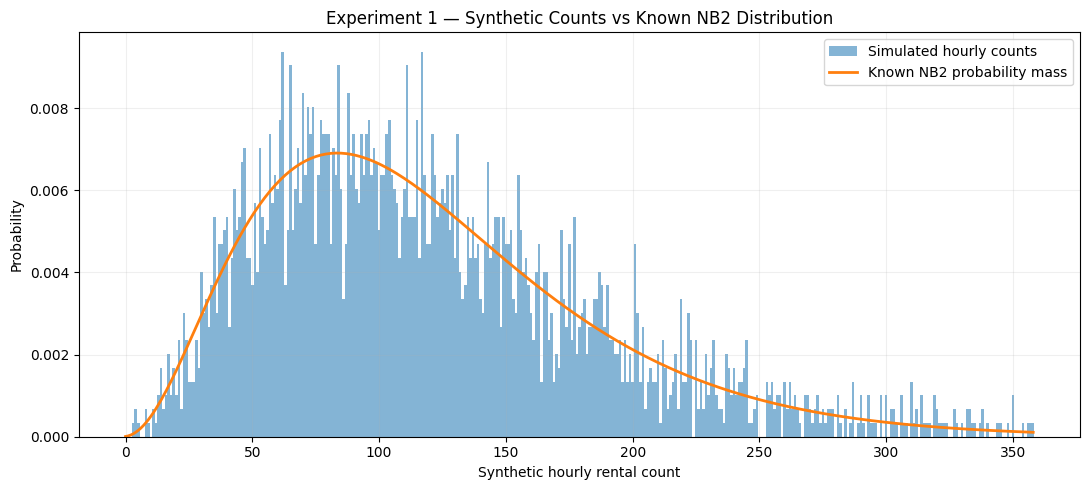

In [26]:

# S2 — KNOWN-PARAMETER DATA GENERATION

# NB2 to SciPy negative binomial conversion
true_size = 1.0 / TRUE_ALPHA
true_p = true_size / (true_size + TRUE_MU)

# Generate synthetic counts
synthetic_counts = nbinom.rvs(
    n=true_size,
    p=true_p,
    size=N_SIM,
    random_state=initial_rng
)

# Theoretical distributional moments
theoretical_mean = TRUE_MU
theoretical_variance = (
    TRUE_MU + TRUE_ALPHA * TRUE_MU**2
)
theoretical_std = np.sqrt(theoretical_variance)
variance_mean_ratio = theoretical_variance / TRUE_MU
true_intercept = np.log(TRUE_MU)

# Check the SciPy parameterization
assert np.isclose(
    nbinom.mean(true_size, true_p),
    theoretical_mean
)
assert np.isclose(
    nbinom.var(true_size, true_p),
    theoretical_variance
)

# Empirical moments from 3,000 counts
sample_mean = np.mean(synthetic_counts)
sample_variance = np.var(synthetic_counts, ddof=1)
sample_std = np.std(synthetic_counts, ddof=1)

parameter_conversion = pd.DataFrame({
    "Parameter": [
        "NB2 mean",
        "NB2 dispersion",
        "SciPy shape r",
        "SciPy probability p",
        "True intercept log(mu)",
        "Variance-to-mean ratio"
    ],
    "Value": [
        TRUE_MU,
        TRUE_ALPHA,
        true_size,
        true_p,
        true_intercept,
        variance_mean_ratio
    ]
})

moment_table = pd.DataFrame({
    "Statistic": [
        "Mean",
        "Variance",
        "Standard deviation"
    ],
    "Theoretical": [
        theoretical_mean,
        theoretical_variance,
        theoretical_std
    ],
    "Simulated sample": [
        sample_mean,
        sample_variance,
        sample_std
    ]
})

print("NB2 PARAMETER CONVERSION")
display(parameter_conversion.round(5))

print("\nTHEORETICAL VS SIMULATED MOMENTS")
display(moment_table.round(3))

print("\nFIRST 10 SYNTHETIC HOURLY COUNTS")
display(
    pd.DataFrame({
        "Synthetic hour": np.arange(1, 11),
        "Generated rentals": synthetic_counts[:10]
    })
)

# Compare empirical and theoretical distributions
upper = int(max(
    np.quantile(synthetic_counts, 0.995),
    nbinom.ppf(0.995, true_size, true_p)
))

x = np.arange(upper + 1)

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    synthetic_counts,
    bins=np.arange(upper + 2) - 0.5,
    density=True,
    alpha=0.55,
    label="Simulated hourly counts"
)

ax.plot(
    x,
    nbinom.pmf(x, true_size, true_p),
    linewidth=2,
    label="Known NB2 probability mass"
)

ax.set_title(
    "Experiment 1 — Synthetic Counts vs Known NB2 Distribution"
)
ax.set_xlabel("Synthetic hourly rental count")
ax.set_ylabel("Probability")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


In [27]:

# S3 — SINGLE-DATASET PARAMETER RECOVERY

# Constant-only design matrix
X_synthetic = pd.DataFrame({
    "const": np.ones(N_SIM)
})

# Fit the same NB2 estimator used by FlowCast AI Live
recovery_fit = sm.NegativeBinomial(
    synthetic_counts,
    X_synthetic,
    loglike_method="nb2"
).fit(
    disp=False,
    maxiter=300
)

# Convergence verification
recovery_converged = bool(
    recovery_fit.mle_retvals.get("converged", False)
)

assert recovery_converged, (
    "Known-parameter recovery model did not converge."
)

# Recover intercept, mean, and dispersion
recovered_beta0 = float(
    recovery_fit.params["const"]
)

recovered_mu = float(
    np.exp(recovered_beta0)
)

recovered_alpha = float(
    recovery_fit.params["alpha"]
)

assert np.isfinite(recovered_mu)
assert np.isfinite(recovered_alpha)
assert recovered_alpha > 0

# Signed, absolute, and relative errors
mu_error = recovered_mu - TRUE_MU
alpha_error = recovered_alpha - TRUE_ALPHA

recovery_table = pd.DataFrame({
    "Parameter": [
        "Mean (mu)",
        "Dispersion (alpha)"
    ],
    "Known value": [
        TRUE_MU,
        TRUE_ALPHA
    ],
    "Recovered value": [
        recovered_mu,
        recovered_alpha
    ],
    "Signed error": [
        mu_error,
        alpha_error
    ],
    "Absolute error": [
        abs(mu_error),
        abs(alpha_error)
    ],
    "Relative error (%)": [
        100 * abs(mu_error) / TRUE_MU,
        100 * abs(alpha_error) / TRUE_ALPHA
    ]
})

print("=" * 70)
print("EXPERIMENT 1 — SINGLE-SAMPLE PARAMETER RECOVERY")
print("=" * 70)

print("Converged:", recovery_converged)
print("Known intercept:", round(true_intercept, 5))
print("Recovered intercept:", round(recovered_beta0, 5))

display(recovery_table.round(5))

print("\nCONSTANT-ONLY NB2 MODEL SUMMARY")
print(recovery_fit.summary())


EXPERIMENT 1 — SINGLE-SAMPLE PARAMETER RECOVERY
Converged: True
Known intercept: 4.78749
Recovered intercept: 4.80014


,Parameter,Known value,Recovered value,Signed error,Absolute error,Relative error (%)
0,Mean (mu),120.0,121.52767,1.52767,1.52767,1.27306
1,Dispersion (alpha),0.3,0.30948,0.00948,0.00948,3.15939



CONSTANT-ONLY NB2 MODEL SUMMARY
                     NegativeBinomial Regression Results                      
Dep. Variable:                      y   No. Observations:                 3000
Model:               NegativeBinomial   Df Residuals:                     2999
Method:                           MLE   Df Model:                            0
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:               6.239e-12
Time:                        23:57:17   Log-Likelihood:                -16603.
converged:                       True   LL-Null:                       -16603.
Covariance Type:            nonrobust   LLR p-value:                       nan
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.8001      0.010    466.446      0.000       4.780       4.820
alpha          0.3095      0.008     39.276      0.000       0.294       0.325


In [28]:

# S4 — REPEATED MONTE CARLO PARAMETER RECOVERY

recovery_records = []

for repetition in range(1, N_REPEATS + 1):

    # New independent sample with the same known parameters
    counts = nbinom.rvs(
        n=true_size,
        p=true_p,
        size=N_SIM,
        random_state=recovery_rng
    )

    converged = False
    mu_hat = np.nan
    alpha_hat = np.nan
    failure_reason = ""

    try:
        # Capture fitting warnings without hiding failures
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")

            fit = sm.NegativeBinomial(
                counts,
                X_synthetic,
                loglike_method="nb2"
            ).fit(
                disp=False,
                maxiter=300
            )

        converged = bool(
            fit.mle_retvals.get("converged", False)
        )

        if converged:
            mu_hat = float(np.exp(fit.params["const"]))
            alpha_hat = float(fit.params["alpha"])

            if not (
                np.isfinite(mu_hat)
                and np.isfinite(alpha_hat)
                and alpha_hat > 0
            ):
                converged = False
                failure_reason = "Non-finite or invalid estimates"

        if not converged and not failure_reason:
            failure_reason = "Optimizer did not converge"

        if caught and not failure_reason:
            warning_types = sorted({
                type(w.message).__name__ for w in caught
            })
            failure_reason = "Warnings: " + ", ".join(warning_types)

    except Exception as exc:
        failure_reason = (
            f"{type(exc).__name__}: {str(exc)[:120]}"
        )

    if not converged:
        mu_hat = np.nan
        alpha_hat = np.nan

    recovery_records.append({
        "Repetition": repetition,
        "Converged": converged,
        "Estimated mu": mu_hat,
        "Estimated alpha": alpha_hat,
        "Diagnostic": failure_reason
    })

recovery_results = pd.DataFrame(recovery_records)

successful_recoveries = recovery_results.loc[
    recovery_results["Converged"]
].copy()

n_success = len(successful_recoveries)
convergence_rate = n_success / N_REPEATS

assert n_success >= 2, (
    "Fewer than two successful fits: "
    "cannot estimate recovery variability."
)

successful_recoveries["Mu error"] = (
    successful_recoveries["Estimated mu"] - TRUE_MU
)

successful_recoveries["Alpha error"] = (
    successful_recoveries["Estimated alpha"] - TRUE_ALPHA
)

print("REPEATED PARAMETER RECOVERY")
print("Attempted fits:", N_REPEATS)
print("Successful fits:", n_success)
print("Failed fits:", N_REPEATS - n_success)
print("Convergence rate:", f"{convergence_rate:.2%}")

print("\nFIRST 10 EXPERIMENTS")
display(recovery_results.head(10).round(5))

if n_success < N_REPEATS:
    print("\nFAILED-FIT DIAGNOSTICS")
    display(
        recovery_results.loc[
            ~recovery_results["Converged"]
        ]
    )


REPEATED PARAMETER RECOVERY
Attempted fits: 100
Successful fits: 100
Failed fits: 0
Convergence rate: 100.00%

FIRST 10 EXPERIMENTS


,Repetition,Converged,Estimated mu,Estimated alpha,Diagnostic
0,1,True,119.87733,0.30695,
1,2,True,120.76800,0.29951,
2,3,True,120.44400,0.28783,
3,4,True,119.74200,0.30685,
4,5,True,122.32433,0.30583,
5,6,True,119.98700,0.28932,
6,7,True,120.47367,0.29607,
7,8,True,120.38133,0.29578,
8,9,True,119.49800,0.30042,
9,10,True,118.46300,0.29928,


EXPERIMENT 1 — REPEATED PARAMETER RECOVERY RESULTS


,Parameter,Known value,Average estimate,Bias,Estimate variance,Estimate SD,RMSE
0,Mean (mu),120.0,119.92915,-0.07085,1.52201,1.23370,1.22956
1,Dispersion (alpha),0.3,0.29852,-0.00148,0.00005,0.00714,0.00726


Attempted experiments: 100
Successful estimates: 100
Convergence rate: 100.00%


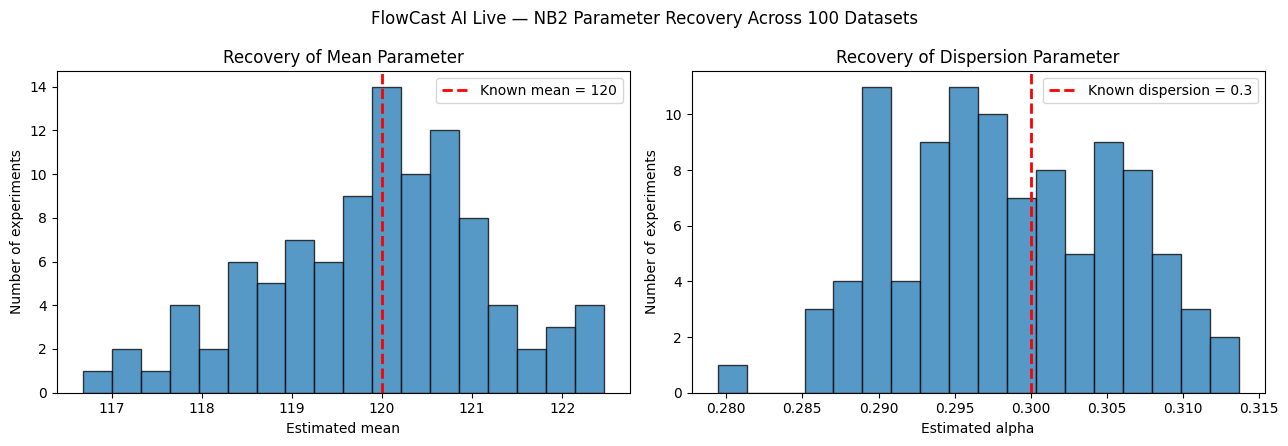

In [29]:

# S5 — MONTE CARLO RECOVERY ACCURACY AND VARIABILITY

mu_estimates = successful_recoveries[
    "Estimated mu"
].to_numpy()

alpha_estimates = successful_recoveries[
    "Estimated alpha"
].to_numpy()

mu_errors = mu_estimates - TRUE_MU
alpha_errors = alpha_estimates - TRUE_ALPHA

# Bias, empirical variance, SD, and RMSE
recovery_summary = pd.DataFrame({
    "Parameter": [
        "Mean (mu)",
        "Dispersion (alpha)"
    ],
    "Known value": [
        TRUE_MU,
        TRUE_ALPHA
    ],
    "Average estimate": [
        mu_estimates.mean(),
        alpha_estimates.mean()
    ],
    "Bias": [
        mu_errors.mean(),
        alpha_errors.mean()
    ],
    "Estimate variance": [
        mu_estimates.var(ddof=1),
        alpha_estimates.var(ddof=1)
    ],
    "Estimate SD": [
        mu_estimates.std(ddof=1),
        alpha_estimates.std(ddof=1)
    ],
    "RMSE": [
        np.sqrt(np.mean(mu_errors**2)),
        np.sqrt(np.mean(alpha_errors**2))
    ]
})

print("=" * 70)
print("EXPERIMENT 1 — REPEATED PARAMETER RECOVERY RESULTS")
print("=" * 70)

display(recovery_summary.round(5))

print("Attempted experiments:", N_REPEATS)
print("Successful estimates:", n_success)
print("Convergence rate:", f"{convergence_rate:.2%}")

# Two recovery histograms
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.5)
)

axes[0].hist(
    mu_estimates,
    bins=18,
    alpha=0.75,
    edgecolor="black"
)

axes[0].axvline(
    TRUE_MU,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Known mean = 120"
)

axes[0].set_title("Recovery of Mean Parameter")
axes[0].set_xlabel("Estimated mean")
axes[0].set_ylabel("Number of experiments")
axes[0].legend()

axes[1].hist(
    alpha_estimates,
    bins=18,
    alpha=0.75,
    edgecolor="black"
)

axes[1].axvline(
    TRUE_ALPHA,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Known dispersion = 0.3"
)

axes[1].set_title("Recovery of Dispersion Parameter")
axes[1].set_xlabel("Estimated alpha")
axes[1].set_ylabel("Number of experiments")
axes[1].legend()

fig.suptitle(
    "FlowCast AI Live — NB2 Parameter Recovery Across 100 Datasets"
)

fig.tight_layout()
plt.show()


In [30]:

# S6 — CONDITIONAL HELD-OUT PREDICTIVE SIMULATION

# Historical held-out observations and fitted means
observed_counts = test["cnt"].to_numpy()
test_mu = test["nb_mean"].to_numpy()

# Use main FlowCast AI Live model dispersion
test_alpha = float(alpha)

# NB2 to SciPy conversion
test_size = 1.0 / test_alpha
test_p = test_size / (test_size + test_mu)

# Verify parameterization
assert np.allclose(
    nbinom.mean(test_size, test_p),
    test_mu
)

assert np.allclose(
    nbinom.var(test_size, test_p),
    test_mu + test_alpha * test_mu**2
)

# Generate 500 complete synthetic held-out trajectories
# Shape: simulations × held-out hours
predictive_counts = nbinom.rvs(
    n=test_size,
    p=test_p,
    size=(N_PRED_SIM, len(test_mu)),
    random_state=predictive_rng
)

assert predictive_counts.shape == (
    N_PRED_SIM, len(test)
)

assert np.isfinite(predictive_counts).all()
assert (predictive_counts >= 0).all()

# Hour-specific predictive simulation mean
simulated_hourly_mean = predictive_counts.mean(axis=0)

# Theoretical conditional variance
test_conditional_variance = (
    test_mu + test_alpha * test_mu**2
)

# Preview of the first ten historical hours
predictive_preview = pd.DataFrame({
    "Datetime": test["datetime"].to_numpy(),
    "Observed rentals": observed_counts,
    "Fitted conditional mean": test_mu,
    "Simulated mean": simulated_hourly_mean,
    "NB2 conditional variance": test_conditional_variance
})

print("=" * 70)
print("EXPERIMENT 2 — HELD-OUT PREDICTIVE SIMULATION")
print("=" * 70)

print("Predictive trajectories:", N_PRED_SIM)
print("Held-out hours:", len(test_mu))
print("Simulation matrix shape:", predictive_counts.shape)

print("\nFIRST 10 HELD-OUT HOURS")
display(predictive_preview.head(10).round(3))


EXPERIMENT 2 — HELD-OUT PREDICTIVE SIMULATION
Predictive trajectories: 500
Held-out hours: 2098
Simulation matrix shape: (500, 2098)

FIRST 10 HELD-OUT HOURS


,Datetime,Observed rentals,Fitted conditional mean,Simulated mean,NB2 conditional variance
0,2012-10-01 00:00:00,45,68.926,69.286,734.266
1,2012-10-01 01:00:00,18,39.439,39.816,257.275
2,2012-10-01 02:00:00,12,20.258,20.086,77.731
3,2012-10-01 03:00:00,7,14.191,14.038,42.392
4,2012-10-01 04:00:00,10,9.521,10.170,22.215
5,2012-10-01 05:00:00,36,20.565,20.184,79.797
6,2012-10-01 06:00:00,155,72.578,72.924,810.287
7,2012-10-01 07:00:00,483,256.397,256.638,9463.106
8,2012-10-01 08:00:00,784,583.620,580.268,48285.919
9,2012-10-01 09:00:00,340,613.602,623.926,53342.971


OBSERVED VS SIMULATED DISTRIBUTION


,Statistic,Observed test,Pooled predictive simulation
0,Mean,221.422,229.391
1,Variance,40877.996,50133.072
2,Standard deviation,202.183,223.904
3,5th percentile,6.000,8.000
4,25th percentile,46.000,50.000
5,Median,174.000,168.000
6,75th percentile,329.000,338.000
7,95th percentile,637.150,674.000



MARGINAL VARIANCE DECOMPOSITION


,Component,Value
0,Average conditional NB2 variance,12807.402
1,Between-hour fitted-mean variance,37252.154
2,Model-implied marginal variance,50059.556
3,Observed held-out sample variance,40877.996
4,Pooled simulated sample variance,50133.072


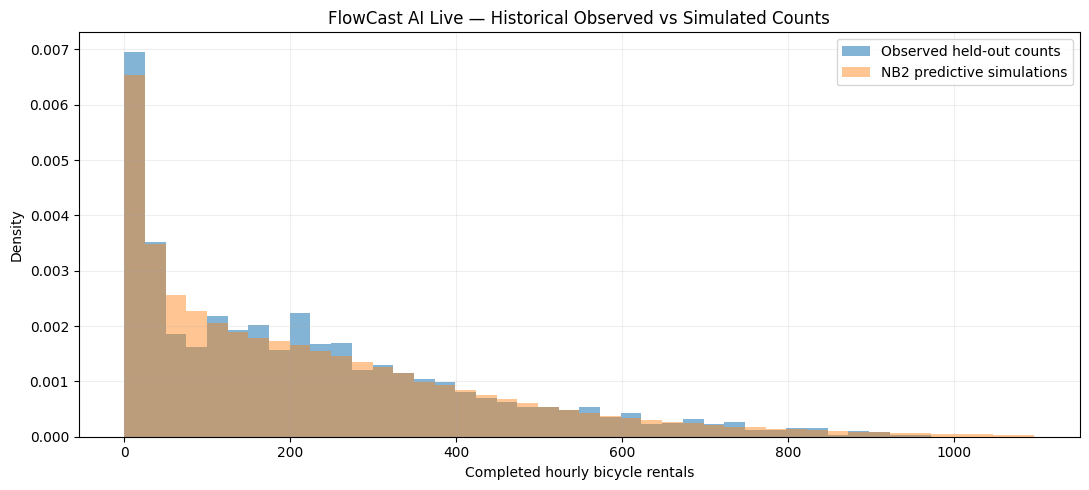

In [31]:

# S7 — OBSERVED VS SIMULATED DISTRIBUTIONAL COMPARISON

# Pooled simulated counts for marginal histogram
simulated_all = predictive_counts.ravel()

# Distribution summary function
def distribution_stats(values):
    return {
        "Mean": np.mean(values),
        "Variance": np.var(values, ddof=1),
        "Standard deviation": np.std(values, ddof=1),
        "5th percentile": np.quantile(values, 0.05),
        "25th percentile": np.quantile(values, 0.25),
        "Median": np.quantile(values, 0.50),
        "75th percentile": np.quantile(values, 0.75),
        "95th percentile": np.quantile(values, 0.95)
    }

observed_summary = distribution_stats(observed_counts)
simulated_summary = distribution_stats(simulated_all)

distribution_comparison = pd.DataFrame({
    "Statistic": list(observed_summary.keys()),
    "Observed test": list(observed_summary.values()),
    "Pooled predictive simulation": list(
        simulated_summary.values()
    )
})

print("OBSERVED VS SIMULATED DISTRIBUTION")
display(distribution_comparison.round(3))

# Theoretical marginal variance decomposition
average_conditional_variance = (
    test_conditional_variance.mean()
)

between_hour_variance = np.var(
    test_mu, ddof=0
)

model_implied_marginal_variance = (
    average_conditional_variance
    + between_hour_variance
)

variance_decomposition = pd.DataFrame({
    "Component": [
        "Average conditional NB2 variance",
        "Between-hour fitted-mean variance",
        "Model-implied marginal variance",
        "Observed held-out sample variance",
        "Pooled simulated sample variance"
    ],
    "Value": [
        average_conditional_variance,
        between_hour_variance,
        model_implied_marginal_variance,
        observed_counts.var(ddof=1),
        simulated_all.var(ddof=1)
    ]
})

print("\nMARGINAL VARIANCE DECOMPOSITION")
display(variance_decomposition.round(3))

# Plot empirical distributions using common bins
upper = max(
    np.quantile(observed_counts, 0.995),
    np.quantile(simulated_all, 0.995)
)

bins = np.linspace(0, max(upper, 1), 45)

fig, ax = plt.subplots(figsize=(11, 5))

ax.hist(
    observed_counts,
    bins=bins,
    density=True,
    alpha=0.55,
    label="Observed held-out counts"
)

ax.hist(
    simulated_all,
    bins=bins,
    density=True,
    alpha=0.45,
    label="NB2 predictive simulations"
)

ax.set_title(
    "FlowCast AI Live — Historical Observed vs Simulated Counts"
)

ax.set_xlabel("Completed hourly bicycle rentals")
ax.set_ylabel("Density")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


SIMULATION-BASED REFERENCE INTERVAL CHECK


,Statistic,Observed value,Simulated mean statistic,95% lower reference,95% upper reference,Inside interval
0,Mean,221.422,229.391,224.732,233.852,False
1,Variance,40877.996,50151.371,46435.727,54329.813,False
2,Standard deviation,202.183,223.899,215.490,233.088,False
3,5th percentile,6.000,8.104,7.000,9.000,False
4,25th percentile,46.000,50.168,47.250,53.000,False
5,Median,174.000,168.534,162.000,175.000,True
6,75th percentile,329.000,338.417,327.869,349.394,True
7,95th percentile,637.150,673.357,641.704,702.975,False



Statistics inside reference intervals: 2 of 8


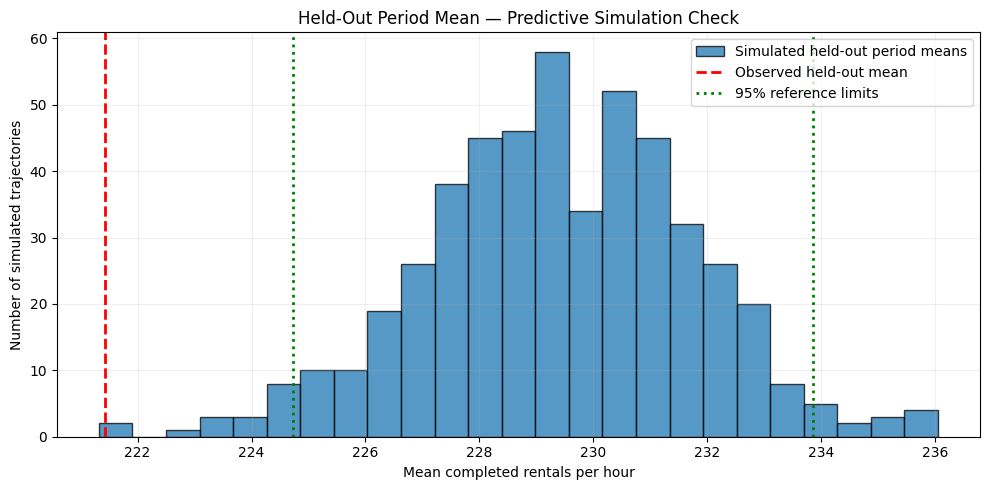


OBSERVED PERIOD MEAN: 221.422
95% SIMULATION REFERENCE INTERVAL: [224.732 233.852]


In [32]:

# S8 — SIMULATION-BASED REFERENCE INTERVALS

# Compute each statistic separately for every trajectory
simulated_statistics = {
    "Mean": predictive_counts.mean(axis=1),
    "Variance": predictive_counts.var(axis=1, ddof=1),
    "Standard deviation": predictive_counts.std(
        axis=1, ddof=1
    ),
    "5th percentile": np.quantile(
        predictive_counts, 0.05, axis=1
    ),
    "25th percentile": np.quantile(
        predictive_counts, 0.25, axis=1
    ),
    "Median": np.quantile(
        predictive_counts, 0.50, axis=1
    ),
    "75th percentile": np.quantile(
        predictive_counts, 0.75, axis=1
    ),
    "95th percentile": np.quantile(
        predictive_counts, 0.95, axis=1
    )
}

reference_records = []

for statistic, observed_value in observed_summary.items():

    simulated_values = simulated_statistics[statistic]

    # Central 95% reference interval
    lower, upper = np.quantile(
        simulated_values,
        [0.025, 0.975]
    )

    # Compare the observed statistic with the interval
    inside = bool(
        lower <= observed_value <= upper
    )

    reference_records.append({
        "Statistic": statistic,
        "Observed value": observed_value,
        "Simulated mean statistic": np.mean(simulated_values),
        "95% lower reference": lower,
        "95% upper reference": upper,
        "Inside interval": inside
    })

reference_table = pd.DataFrame(reference_records)

print("=" * 70)
print("SIMULATION-BASED REFERENCE INTERVAL CHECK")
print("=" * 70)

display(reference_table.round(3))

n_inside = int(
    reference_table["Inside interval"].sum()
)

print(
    "\nStatistics inside reference intervals:",
    n_inside,
    "of",
    len(reference_table)
)

# Visualize the simulated distribution of the period mean
simulated_period_means = simulated_statistics["Mean"]

observed_period_mean = observed_summary["Mean"]

mean_lower, mean_upper = np.quantile(
    simulated_period_means,
    [0.025, 0.975]
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.hist(
    simulated_period_means,
    bins=25,
    edgecolor="black",
    alpha=0.75,
    label="Simulated held-out period means"
)

ax.axvline(
    observed_period_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Observed held-out mean"
)

ax.axvline(
    mean_lower,
    color="green",
    linestyle=":",
    linewidth=2,
    label="95% reference limits"
)

ax.axvline(
    mean_upper,
    color="green",
    linestyle=":",
    linewidth=2
)

ax.set_title(
    "Held-Out Period Mean — Predictive Simulation Check"
)

ax.set_xlabel("Mean completed rentals per hour")
ax.set_ylabel("Number of simulated trajectories")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

print("\nOBSERVED PERIOD MEAN:", round(observed_period_mean, 3))
print(
    "95% SIMULATION REFERENCE INTERVAL:",
    np.round([mean_lower, mean_upper], 3)
)


HOURLY NEGATIVE BINOMIAL PREDICTIVE INTERVALS


,Interval,Nominal coverage,Empirical coverage,Coverage difference,Average width (rentals)
0,Central 90%,0.90,0.9104,0.0104,281.7612
1,Central 95%,0.95,0.9418,-0.0082,337.3265



FIRST 10 HELD-OUT PREDICTIVE INTERVALS


,datetime,cnt,nb_mean,nb_lo90,nb_hi90,nb_lo95,nb_hi95,covered90,covered95
15211,2012-10-01 00:00:00,45,68.926,31.0,118.0,26.0,131.0,True,True
15212,2012-10-01 01:00:00,18,39.439,17.0,69.0,14.0,76.0,True,True
15213,2012-10-01 02:00:00,12,20.258,8.0,36.0,6.0,40.0,True,True
15214,2012-10-01 03:00:00,7,14.191,5.0,26.0,4.0,29.0,True,True
15215,2012-10-01 04:00:00,10,9.521,3.0,18.0,2.0,20.0,True,True
15216,2012-10-01 05:00:00,36,20.565,8.0,37.0,6.0,41.0,True,True
15217,2012-10-01 06:00:00,155,72.578,33.0,125.0,27.0,138.0,False,False
15218,2012-10-01 07:00:00,483,256.397,120.0,434.0,102.0,479.0,False,False
15219,2012-10-01 08:00:00,784,583.620,275.0,985.0,235.0,1086.0,True,True
15220,2012-10-01 09:00:00,340,613.602,289.0,1036.0,247.0,1142.0,True,True


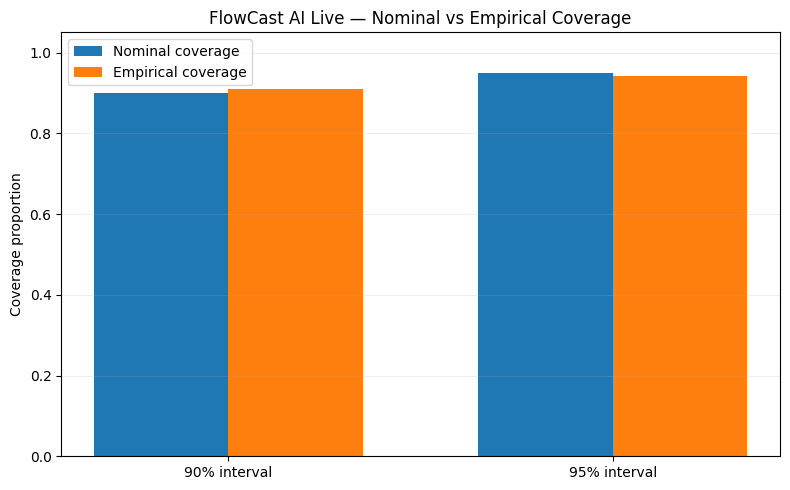

In [33]:

# S9 — HOURLY PREDICTIVE INTERVALS AND COVERAGE

# Use fitted NB2 parameters from the main model
size = 1.0 / alpha
p = size / (size + test_mu)

# Central 90% predictive interval
test["nb_lo90"] = nbinom.ppf(
    0.05, size, p
)

test["nb_hi90"] = nbinom.ppf(
    0.95, size, p
)

# Central 95% predictive interval
test["nb_lo95"] = nbinom.ppf(
    0.025, size, p
)

test["nb_hi95"] = nbinom.ppf(
    0.975, size, p
)

# Observed interval membership
test["covered90"] = (
    (test["cnt"] >= test["nb_lo90"])
    &
    (test["cnt"] <= test["nb_hi90"])
)

test["covered95"] = (
    (test["cnt"] >= test["nb_lo95"])
    &
    (test["cnt"] <= test["nb_hi95"])
)

# Interval widths
test["width90"] = (
    test["nb_hi90"] - test["nb_lo90"]
)

test["width95"] = (
    test["nb_hi95"] - test["nb_lo95"]
)

# Empirical coverage
coverage90 = float(test["covered90"].mean())
coverage95 = float(test["covered95"].mean())

# Coverage and width comparison
coverage_table = pd.DataFrame({
    "Interval": [
        "Central 90%",
        "Central 95%"
    ],
    "Nominal coverage": [
        0.90,
        0.95
    ],
    "Empirical coverage": [
        coverage90,
        coverage95
    ],
    "Coverage difference": [
        coverage90 - 0.90,
        coverage95 - 0.95
    ],
    "Average width (rentals)": [
        test["width90"].mean(),
        test["width95"].mean()
    ]
})

print("=" * 70)
print("HOURLY NEGATIVE BINOMIAL PREDICTIVE INTERVALS")
print("=" * 70)

display(coverage_table.round(4))

print("\nFIRST 10 HELD-OUT PREDICTIVE INTERVALS")

display(
    test[
        [
            "datetime",
            "cnt",
            "nb_mean",
            "nb_lo90",
            "nb_hi90",
            "nb_lo95",
            "nb_hi95",
            "covered90",
            "covered95"
        ]
    ].head(10).round(3)
)

# Compare nominal and empirical coverage
fig, ax = plt.subplots(figsize=(8, 5))

x = np.arange(2)
bar_width = 0.35

ax.bar(
    x - bar_width / 2,
    [0.90, 0.95],
    bar_width,
    label="Nominal coverage"
)

ax.bar(
    x + bar_width / 2,
    [coverage90, coverage95],
    bar_width,
    label="Empirical coverage"
)

ax.set_xticks(x)
ax.set_xticklabels(["90% interval", "95% interval"])
ax.set_ylabel("Coverage proportion")
ax.set_ylim(0, 1.05)

ax.set_title(
    "FlowCast AI Live — Nominal vs Empirical Coverage"
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()


In [34]:

# S10 — FINAL FLOWCAST AI LIVE SIMULATION SUMMARY

# Retrieve parameter-recovery diagnostics
mu_bias = float(mu_errors.mean())
alpha_bias = float(alpha_errors.mean())

mu_sd = float(mu_estimates.std(ddof=1))
alpha_sd = float(alpha_estimates.std(ddof=1))

mu_rmse = float(np.sqrt(np.mean(mu_errors**2)))
alpha_rmse = float(np.sqrt(np.mean(alpha_errors**2)))

# Retrieve predictive simulation diagnostics
observed_mean = float(observed_summary["Mean"])
simulated_mean = float(simulated_summary["Mean"])

observed_variance = float(observed_summary["Variance"])
simulated_variance = float(simulated_summary["Variance"])

# Consolidated summary
final_simulation_summary = pd.DataFrame({
    "Experiment": [
        "Parameter recovery",
        "Parameter recovery",
        "Parameter recovery",
        "Parameter recovery",
        "Parameter recovery",
        "Parameter recovery",
        "Parameter recovery",
        "Predictive simulation",
        "Predictive simulation",
        "Predictive simulation",
        "Predictive simulation",
        "Predictive simulation",
        "Predictive simulation",
        "Predictive simulation"
    ],
    "Diagnostic": [
        "Attempted recovery fits",
        "Successful recovery fits",
        "Convergence rate",
        "Mean parameter bias",
        "Dispersion parameter bias",
        "Mean parameter SD",
        "Dispersion parameter SD",
        "Predictive trajectories",
        "Observed hourly mean",
        "Simulated hourly mean",
        "Observed hourly variance",
        "Simulated hourly variance",
        "90% hourly interval coverage",
        "95% hourly interval coverage"
    ],
    "Value": [
        N_REPEATS,
        n_success,
        convergence_rate,
        mu_bias,
        alpha_bias,
        mu_sd,
        alpha_sd,
        N_PRED_SIM,
        observed_mean,
        simulated_mean,
        observed_variance,
        simulated_variance,
        coverage90,
        coverage95
    ]
})

print("=" * 75)
print("FLOWCAST AI LIVE — FINAL SIMULATION RESULTS")
print("=" * 75)

display(final_simulation_summary.round(5))

print("\nPARAMETER RECOVERY RMSE")
print("Mean RMSE:", round(mu_rmse, 5))
print("Dispersion RMSE:", round(alpha_rmse, 5))

print("\nPREDICTIVE REFERENCE INTERVAL RESULTS")
display(reference_table.round(3))

print("\nMODEL INTERVAL COVERAGE")
display(coverage_table.round(4))

print("\nREPRODUCIBILITY RECORD")
print("Master seed:", SIM_SEED)
print("Synthetic sample size:", N_SIM)
print("Recovery attempts:", N_REPEATS)
print("Predictive trajectories:", N_PRED_SIM)
print("Main NB2 model refitted on test data: NO")

print("\nINTERPRETATION")
print(
    "Experiment 1 evaluates NB2 estimation reliability "
    "under known generating conditions."
)
print(
    "Experiment 2 evaluates selected historical "
    "predictive distributional characteristics."
)
print(
    "Neither experiment demonstrates present-day "
    "operational accuracy or realized savings."
)


FLOWCAST AI LIVE — FINAL SIMULATION RESULTS


,Experiment,Diagnostic,Value
0,Parameter recovery,Attempted recovery fits,100.00000
1,Parameter recovery,Successful recovery fits,100.00000
2,Parameter recovery,Convergence rate,1.00000
3,Parameter recovery,Mean parameter bias,-0.07085
4,Parameter recovery,Dispersion parameter bias,-0.00148
5,Parameter recovery,Mean parameter SD,1.23370
6,Parameter recovery,Dispersion parameter SD,0.00714
7,Predictive simulation,Predictive trajectories,500.00000
8,Predictive simulation,Observed hourly mean,221.42183
9,Predictive simulation,Simulated hourly mean,229.39114



PARAMETER RECOVERY RMSE
Mean RMSE: 1.22956
Dispersion RMSE: 0.00726

PREDICTIVE REFERENCE INTERVAL RESULTS


,Statistic,Observed value,Simulated mean statistic,95% lower reference,95% upper reference,Inside interval
0,Mean,221.422,229.391,224.732,233.852,False
1,Variance,40877.996,50151.371,46435.727,54329.813,False
2,Standard deviation,202.183,223.899,215.490,233.088,False
3,5th percentile,6.000,8.104,7.000,9.000,False
4,25th percentile,46.000,50.168,47.250,53.000,False
5,Median,174.000,168.534,162.000,175.000,True
6,75th percentile,329.000,338.417,327.869,349.394,True
7,95th percentile,637.150,673.357,641.704,702.975,False



MODEL INTERVAL COVERAGE


,Interval,Nominal coverage,Empirical coverage,Coverage difference,Average width (rentals)
0,Central 90%,0.90,0.9104,0.0104,281.7612
1,Central 95%,0.95,0.9418,-0.0082,337.3265



REPRODUCIBILITY RECORD
Master seed: 20261112
Synthetic sample size: 3000
Recovery attempts: 100
Predictive trajectories: 500
Main NB2 model refitted on test data: NO

INTERPRETATION
Experiment 1 evaluates NB2 estimation reliability under known generating conditions.
Experiment 2 evaluates selected historical predictive distributional characteristics.
Neither experiment demonstrates present-day operational accuracy or realized savings.


## Residuals and calibration

Plot the residuals against time or against the prediction, and say whether the error looks like noise or like bias. Check calibration on the held-out data. Say how the error grows as the forecast moves further from the data.


# Residuals and Calibration — FlowCast AI Live

## Purpose and Statistical Motivation

FlowCast AI Live uses negative binomial (NB2) regression to estimate the conditional probability distribution of completed hourly bicycle-sharing rental counts.

The fitted predictive model is:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB2}
(\widehat{\mu}_t,\widehat{\alpha})
}
$$

where:

- $D_t$ is the observed completed rental count during hour $t$.
- $X_t$ is the historical predictor vector.
- $\widehat{\mu}_t$ is the fitted conditional mean.
- $\widehat{\alpha}>0$ is the estimated NB2 dispersion parameter.

The fitted conditional mean is:

$$
\boxed{
\widehat{\mu}_t
=
\exp\left(
X_t^{\mathsf T}\widehat{\boldsymbol{\beta}}
\right)
}
$$

The model-implied conditional variance is:

$$
\boxed{
\widehat V_t
=
\widehat{\mu}_t
+
\widehat{\alpha}\widehat{\mu}_t^2
}
$$

This analysis evaluates whether the model's prediction errors behave approximately like unexplained random variation or exhibit systematic structure.

The diagnostics address three questions:

1. **Residual bias:** Are held-out residuals approximately centered around zero, or do they exhibit systematic patterns over time or across predicted rental demand?

2. **Predictive calibration:** Do the model's predictive probabilities and intervals agree with the observed historical rental counts?

3. **Error magnitude and growth:** How does forecast error vary across predicted demand levels and elapsed historical test time?

All primary diagnostics use the historical held-out observations from **October–December 2012**.

Let the number of held-out hourly observations be $m$:

$$
\boxed{
\mathcal D_{\mathrm{test}}
=
\left\{
(X_t,D_t)
\right\}_{t=1}^{m}
}
$$

The fitted regression parameters remain fixed throughout the evaluation.

---

## 1. Raw Residuals and Forecast Error

### 1.1 Raw Residual Definition

The raw residual for held-out hour $t$ is:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
}
$$

The sign of the residual indicates the direction of prediction error:

$$
\begin{aligned}
e_t>0
&\Longrightarrow
D_t>\widehat{\mu}_t
&&\text{(Underprediction)}
\\[6pt]
e_t<0
&\Longrightarrow
D_t<\widehat{\mu}_t
&&\text{(Overprediction)}
\\[6pt]
e_t=0
&\Longrightarrow
D_t=\widehat{\mu}_t
&&\text{(Exact point prediction)}
\end{aligned}
$$

### 1.2 Mean Error

The mean error measures average signed prediction bias:

$$
\boxed{
ME
=
\frac{1}{m}
\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)
}
$$

Interpretation:

$$
\begin{aligned}
ME>0
&\Longrightarrow
\text{Average underprediction}
\\
ME<0
&\Longrightarrow
\text{Average overprediction}
\\
ME\approx0
&\Longrightarrow
\text{Small average signed bias}
\end{aligned}
$$

A mean error near zero does not necessarily indicate accurate individual predictions because positive and negative errors can cancel.

### 1.3 Mean Absolute Error

The mean absolute error measures the average magnitude of prediction errors:

$$
\boxed{
MAE
=
\frac{1}{m}
\sum_{t=1}^{m}
\left|
D_t-\widehat{\mu}_t
\right|
}
$$

MAE is measured in completed rentals per hour.

### 1.4 Root Mean Squared Error

The root mean squared error is:

$$
\boxed{
RMSE
=
\sqrt{
\frac{1}{m}
\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)^2
}
}
$$

Squaring prediction errors gives greater weight to large deviations.

Consequently, RMSE is particularly sensitive to hours with unusually large forecasting errors.

### 1.5 Scaled Absolute Error

Mean absolute percentage error is not used as the primary metric because observed hourly rental counts can be zero or very small.

Instead, define the scaled absolute error:

$$
\boxed{
SAE_t
=
\frac{
|D_t-\widehat{\mu}_t|
}{
\max(\widehat{\mu}_t,1)
}
}
$$

The average scaled absolute error can be summarized as:

$$
\overline{SAE}
=
\frac{1}{m}
\sum_{t=1}^{m}
SAE_t
$$

This diagnostic expresses error magnitude relative to the predicted demand scale while avoiding division by zero.

It is not the project's primary asymmetric capacity decision-loss function.

---

## 2. Residuals Against Time

### 2.1 Temporal Residual Analysis

Plot the raw residuals against the chronological held-out timestamps:

$$
\boxed{
\left\{
(t,e_t)
\right\}_{t=1}^{m}
}
$$

A horizontal zero-reference line represents:

$$
e_t=0
$$

Residuals distributed irregularly around zero are more consistent with noise-like prediction errors.

However, persistent positive or negative residuals may indicate systematic forecasting bias.

### 2.2 Rolling Mean Residuals

For a rolling window containing $w$ consecutive observations, define:

$$
\boxed{
\overline e_t^{(w)}
=
\frac{1}{w}
\sum_{j=0}^{w-1}
e_{t-j}
}
$$

for:

$$
t=w,w+1,\ldots,m
$$

A rolling mean near zero suggests limited persistent signed bias within that window.

Sustained deviations from zero may indicate temporal changes in predictive performance.

The rolling mean is a descriptive diagnostic and does not establish statistical independence.

### 2.3 Temporal Diagnostic Interpretation

The residual plot is examined for:

- Persistent positive or negative errors.
- Long runs of residuals with the same sign.
- Recurring daily or weekly patterns.
- Changes in residual dispersion.
- Isolated unusually large prediction errors.

Such patterns may indicate missing predictors, temporal dependence, or changes in the relationship between predictors and rental counts.

---

## 3. Residuals Against Predicted Demand

### 3.1 Residual-Fitted Relationship

Plot raw residuals against the fitted conditional means:

$$
\boxed{
\left\{
(\widehat{\mu}_t,e_t)
\right\}_{t=1}^{m}
}
$$

The analytical objective is to examine:

$$
\mathbb E[e_t\mid\widehat{\mu}_t]
\approx0
$$

across different predicted-demand levels.

Systematic positive residuals at high predicted demand may indicate underprediction during busy hours.

Systematic negative residuals may indicate overprediction.

### 3.2 Binned Residual Analysis

Partition the held-out observations into $K$ predicted-demand bins:

$$
\mathcal B_1,\mathcal B_2,\ldots,\mathcal B_K
$$

For bin $k$, let:

$$
n_k=|\mathcal B_k|
$$

The average predicted demand is:

$$
\boxed{
\overline{\widehat{\mu}}_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
\widehat{\mu}_t
}
$$

The average signed residual is:

$$
\boxed{
\overline e_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
e_t
}
$$

The average absolute error is:

$$
\boxed{
\overline{AE}_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
|e_t|
}
$$

These summaries identify demand ranges in which the model may systematically underpredict or overpredict.

### 3.3 Expected Heteroscedasticity

Under the NB2 model:

$$
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
$$

Therefore, the model-implied standard deviation increases with the conditional mean:

$$
\boxed{
\sigma_t
=
\sqrt{
\mu_t+\alpha\mu_t^2
}
}
$$

Consequently, increasing raw residual spread at higher predicted demand levels is not, by itself, evidence of model misspecification.

Variance-standardized residuals provide a more appropriate diagnostic of unexplained dispersion.

---

## 4. Pearson Standardized Residuals

### 4.1 Pearson Residual Definition

The Pearson standardized residual adjusts the raw prediction error using the fitted NB2 conditional variance:

$$
\boxed{
r_t^P
=
\frac{
D_t-\widehat{\mu}_t
}{
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
}
$$

Equivalently:

$$
r_t^P
=
\frac{e_t}{\sqrt{\widehat V_t}}
$$

### 4.2 Theoretical Interpretation

Under a correctly specified conditional mean and variance model with known parameters:

$$
\mathbb E[r_t^P\mid X_t]=0
$$

and:

$$
\operatorname{Var}(r_t^P\mid X_t)=1
$$

For the fitted model, these relationships serve as approximate diagnostic targets.

The empirical mean Pearson residual is:

$$
\boxed{
\overline r^P
=
\frac{1}{m}
\sum_{t=1}^{m}
r_t^P
}
$$

The empirical Pearson residual variance is:

$$
\boxed{
s_P^2
=
\frac{1}{m-1}
\sum_{t=1}^{m}
(r_t^P-\overline r^P)^2
}
$$

A mean substantially different from zero may indicate systematic bias.

A variance substantially greater than one may suggest more residual variability than the fitted model predicts.

A variance substantially below one may suggest less residual variability than predicted.

Because hourly rental counts are discrete and potentially skewed, Pearson residuals are not assumed to follow an exact standard normal distribution.

---

## 5. Temporal Error Structure

### 5.1 Residual Autocorrelation

Temporal dependence is examined using residual autocorrelation at lag $k$:

$$
\boxed{
\widehat{\rho}(k)
=
\operatorname{Corr}(e_t,e_{t-k})
}
$$

A sample autocorrelation estimator is:

$$
\boxed{
\widehat{\rho}(k)
=
\frac{
\sum_{t=k+1}^{m}
(e_t-\overline e)(e_{t-k}-\overline e)
}{
\sum_{t=1}^{m}
(e_t-\overline e)^2
}
}
$$

where:

$$
\overline e
=
\frac{1}{m}
\sum_{t=1}^{m}e_t
$$

Autocorrelation is examined at selected lags to identify persistent error structure.

Values near zero indicate limited sample linear correlation at the examined lag.

Substantial positive or negative values suggest remaining temporal dependence.

### 5.2 Hour-of-Day Error Patterns

Let $\mathcal H_h$ denote the set of held-out observations occurring during hour-of-day $h$.

The average signed error for hour $h$ is:

$$
\boxed{
ME_h
=
\frac{1}{|\mathcal H_h|}
\sum_{t\in\mathcal H_h}
e_t
}
$$

where:

$$
h\in\{0,1,\ldots,23\}
$$

This identifies whether the model systematically underpredicts or overpredicts particular hours.

### 5.3 Day-of-Week Error Patterns

Let $\mathcal W_d$ represent held-out observations belonging to weekday $d$.

The average signed error is:

$$
\boxed{
ME_d
=
\frac{1}{|\mathcal W_d|}
\sum_{t\in\mathcal W_d}
e_t
}
$$

for:

$$
d\in\{1,\ldots,7\}
$$

These summaries help identify recurring calendar-related prediction errors.

Autocorrelation and calendar diagnostics are descriptive and do not independently establish causality.

---

## 6. Predictive Interval Calibration

### 6.1 Model-Implied Predictive Distribution

For each held-out hour, the fitted negative binomial predictive distribution is:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB2}
(\widehat{\mu}_t,\widehat{\alpha})
}
$$

Let:

$$
F_t(d)
=
P(D_t\leq d\mid X_t,
\widehat{\boldsymbol{\beta}},
\widehat{\alpha})
$$

denote the fitted cumulative distribution function.

### 6.2 Central Predictive Intervals

For nominal coverage probability $c$, define:

$$
\boxed{
L_t(c)
=
F_t^{-1}
\left(
\frac{1-c}{2}
\right)
}
$$

and:

$$
\boxed{
U_t(c)
=
F_t^{-1}
\left(
\frac{1+c}{2}
\right)
}
$$

The central predictive interval is:

$$
\boxed{
PI_t(c)
=
[L_t(c),U_t(c)]
}
$$

The nominal coverage levels evaluated are:

$$
\boxed{
c\in\{0.50,0.80,0.90,0.95\}
}
$$

### 6.3 Empirical Coverage

For each nominal coverage level $c$, empirical held-out coverage is:

$$
\boxed{
\widehat C(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

where the indicator function is:

$$
\mathbb I(A)
=
\begin{cases}
1,&\text{if }A\text{ is true},\\
0,&\text{otherwise}.
\end{cases}
$$

Calibration is examined by comparing:

$$
\boxed{
\widehat C(c)
\quad\text{versus}\quad
c
}
$$

A descriptive coverage difference is:

$$
\boxed{
\Delta C(c)
=
\widehat C(c)-c
}
$$

Positive differences indicate empirical coverage above the nominal level.

Negative differences indicate empirical coverage below the nominal level.

### 6.4 Predictive Interval Width

For each held-out hour, define the interval width:

$$
\boxed{
W_t(c)
=
U_t(c)-L_t(c)
}
$$

The average interval width is:

$$
\boxed{
\overline W(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
W_t(c)
}
$$

Coverage and interval width are interpreted jointly.

High empirical coverage obtained through excessively wide predictive intervals does not necessarily indicate useful predictive uncertainty.

Because the negative binomial distribution is discrete, quantile-based predictive intervals may have true coverage above the nominal level even when the fitted model is correctly specified.

---

## 7. Randomized Probability Integral Transform

### 7.1 Randomized PIT Definition

The randomized probability integral transform (PIT) evaluates the calibration of discrete predictive distributions.

For observed rental count:

$$
D_t=d_t
$$

define:

$$
\boxed{
u_t
=
F_t(d_t-1)
+
v_t
\left[
F_t(d_t)-F_t(d_t-1)
\right]
}
$$

where:

$$
\boxed{
v_t\overset{\mathrm{iid}}{\sim}
\operatorname{Uniform}(0,1)
}
$$

and $F_t$ is the fitted NB2 cumulative distribution function.

For a nonnegative count distribution:

$$
F_t(-1)=0
$$

### 7.2 Calibration Interpretation

Under a correctly specified conditional predictive distribution:

$$
\boxed{
u_t\mid X_t
\sim
\operatorname{Uniform}(0,1)
}
$$

The corresponding theoretical expectation and variance are:

$$
\mathbb E[u_t]=\frac{1}{2}
$$

$$
\operatorname{Var}(u_t)=\frac{1}{12}
$$

An approximately uniform PIT histogram is consistent with predictive distributional calibration.

Systematic deviations from uniformity may indicate:

- Biased conditional predictions.
- Incorrect predictive dispersion.
- Distributional misspecification.
- Missing explanatory structure.

Serial dependence can affect formal calibration-test assumptions.

Therefore, the randomized PIT is interpreted as diagnostic evidence rather than definitive proof of calibration.

---

## 8. Forecast Error Magnitude and Growth

### 8.1 Absolute and Squared Errors

The absolute prediction error is:

$$
\boxed{
AE_t
=
|D_t-\widehat{\mu}_t|
}
$$

The squared prediction error is:

$$
\boxed{
SE_t
=
(D_t-\widehat{\mu}_t)^2
}
$$

Absolute errors measure prediction deviations in rental-count units.

Squared errors place greater emphasis on large deviations.

### 8.2 Error Magnitude Across Predicted Demand

Group held-out observations into predicted-demand quantile bins:

$$
\mathcal B_1,\ldots,\mathcal B_K
$$

The mean absolute error within bin $k$ is:

$$
\boxed{
MAE_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
|D_t-\widehat{\mu}_t|
}
$$

The root mean squared error within bin $k$ is:

$$
\boxed{
RMSE_k
=
\sqrt{
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
(D_t-\widehat{\mu}_t)^2
}
}
$$

These statistics describe how forecast-error magnitude varies across predicted rental demand.

### 8.3 Model-Implied Error Scale

Under the fitted NB2 distribution, the predictive standard deviation is:

$$
\boxed{
\widehat{\sigma}_t
=
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
$$

The expected conditional variance increases with predicted demand:

$$
\frac{\partial \widehat V_t}
{\partial\widehat{\mu}_t}
=
1+2\widehat{\alpha}\widehat{\mu}_t
$$

Since:

$$
\widehat{\alpha}>0,
\qquad
\widehat{\mu}_t>0
$$

it follows that:

$$
\boxed{
\frac{\partial\widehat V_t}
{\partial\widehat{\mu}_t}>0
}
$$

Therefore, larger raw errors during high-demand hours may be consistent with the model's expected heteroscedasticity.

Pearson standardized residuals help distinguish expected variance growth from additional unexplained variability.

### 8.4 Error Variation Across Historical Test Time

Partition the chronological held-out period into successive calendar blocks:

$$
\mathcal T_1,\mathcal T_2,\ldots,\mathcal T_J
$$

For calendar block $j$, define:

$$
n_j=|\mathcal T_j|
$$

The block-specific mean error is:

$$
\boxed{
ME_j
=
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)
}
$$

The block-specific mean absolute error is:

$$
\boxed{
MAE_j
=
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
|D_t-\widehat{\mu}_t|
}
$$

The block-specific root mean squared error is:

$$
\boxed{
RMSE_j
=
\sqrt{
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)^2
}
}
$$

These diagnostics identify whether prediction errors increase, decrease, or fluctuate across successive portions of the historical test period.

They are **elapsed-time diagnostics**, not genuine multi-horizon forecasting experiments.

The presence of lagged historical predictors does not establish a shared forecast origin for all predictions.

---

## 9. Statistical Interpretation and Limitations

### 9.1 Residual Diagnostics

Residual analysis examines whether:

$$
\boxed{
\mathbb E[D_t-\widehat{\mu}_t\mid X_t]
\approx0
}
$$

and whether unexplained temporal or demand-dependent error patterns remain.

A small overall mean residual does not rule out systematic errors within particular demand levels or calendar periods.

### 9.2 Predictive Calibration

Calibration analysis compares empirical coverage with nominal predictive probabilities:

$$
\boxed{
\widehat C(c)\approx c
}
$$

and examines whether randomized PIT values are approximately uniform:

$$
\boxed{
u_t\sim\operatorname{Uniform}(0,1)
}
$$

These are diagnostic targets rather than assumptions about observed performance.

### 9.3 Error-Growth Analysis

Error-growth analysis examines the relationship between:

$$
\boxed{
AE_t,\quad
SE_t,\quad
\widehat{\mu}_t,\quad
\widehat{\sigma}_t
}
$$

and the progression of error metrics across historical calendar blocks.

### 9.4 Limitations

All residual and calibration diagnostics are conditional on the fitted regression parameters and historical held-out predictors.

They do not establish:

- Independence of all hourly rental errors.
- Correct specification of the NB2 distribution.
- Present-day forecasting accuracy.
- Unobserved rental demand.
- Realized operational capacity savings.

The predictive diagnostics do not incorporate parameter-estimation uncertainty.

Point-forecast errors are evaluated separately from the project's primary asymmetric capacity decision-loss function.

Therefore:

$$
\boxed{
\text{Low Point-Forecast Error}
\not\Rightarrow
\text{Optimal Capacity Decision}
}
$$

Likewise:

$$
\boxed{
\text{Historical Calibration}
\not\Rightarrow
\text{Future Operational Calibration}
}
$$

The final interpretation is based on observed diagnostic results rather than assuming unbiased or calibrated performance in advance.

---

## Reproducibility

The recorded master random seed is:

$$
\boxed{
S_{\mathrm{master}}=20261112
}
$$

Randomization is required only for the discrete randomized PIT diagnostic.

An independent pseudo-random stream derived from the master seed is used to generate:

$$
v_t\sim\operatorname{Uniform}(0,1)
$$

The remaining residual and calibration statistics are deterministic functions of the recorded held-out observations and fixed fitted predictions.

The main regression is not refitted, and held-out outcomes are not used to re-estimate its coefficients.

---

## Analytical Objective

This section combines three complementary diagnostic analyses.

**Residual analysis** evaluates systematic prediction bias and remaining temporal error structure:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
}
$$

**Calibration analysis** evaluates agreement between model-implied predictive uncertainty and historical held-out observations:

$$
\boxed{
\widehat C(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
D_t\in PI_t(c)
\right)
}
$$

**Error-growth analysis** evaluates how forecast-error magnitude varies with predicted demand and elapsed historical test time:

$$
\boxed{
AE_t=|D_t-\widehat{\mu}_t|
}
$$

Together:

$$
\boxed{
\begin{aligned}
\text{Residual Analysis}
&\longrightarrow
\text{Prediction Bias and Error Structure}
\\[6pt]
\text{Calibration Analysis}
&\longrightarrow
\text{Predictive Uncertainty Reliability}
\\[6pt]
\text{Error-Growth Analysis}
&\longrightarrow
\text{Demand- and Time-Dependent Error}
\end{aligned}
}
$$

These checks evaluate the reliability and limitations of FlowCast AI Live's historical probabilistic forecasts.

No conclusion about residual independence, predictive calibration, or operational performance is assumed before examining the actual diagnostic outputs.



In [35]:

# R1 — RESIDUAL AND CALIBRATION CONFIGURATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from scipy.stats import nbinom, kstest
from statsmodels.tsa.stattools import acf
from IPython.display import display

RESIDUAL_SEED = 20261112

# Separate reproducible random stream for PIT
pit_rng = np.random.default_rng(
    np.random.SeedSequence([RESIDUAL_SEED, 4])
)

# Verify previously fitted NB2 model
assert nbfit.mle_retvals.get("converged", False)
assert np.isfinite(alpha) and alpha > 0

required = ["datetime", "cnt", "nb_mean"]

assert all(col in test.columns for col in required)
assert len(test) > 168

# Preserve historical chronological order
residual_df = test[required].copy()
residual_df["datetime"] = pd.to_datetime(
    residual_df["datetime"]
)
residual_df = residual_df.sort_values(
    "datetime"
).reset_index(drop=True)

assert residual_df["datetime"].is_unique
assert residual_df["datetime"].notna().all()

assert np.isfinite(
    residual_df["cnt"].to_numpy()
).all()

assert np.isfinite(
    residual_df["nb_mean"].to_numpy()
).all()

assert (residual_df["nb_mean"] > 0).all()
assert (residual_df["cnt"] >= 0).all()

assert np.all(
    residual_df["cnt"].to_numpy()
    == np.floor(residual_df["cnt"].to_numpy())
)

# Verify chronological test boundaries
assert (
    residual_df["datetime"] >= pd.Timestamp("2012-10-01")
).all()

assert (
    residual_df["datetime"] < pd.Timestamp("2013-01-01")
).all()

# Model parameters for diagnostics
m = len(residual_df)
residual_alpha = float(alpha)

print("=" * 70)
print("FLOWCAST AI LIVE — RESIDUAL AND CALIBRATION CHECK")
print("=" * 70)

print("Held-out observations:", m)
print("First timestamp:", residual_df.datetime.min())
print("Last timestamp:", residual_df.datetime.max())
print("Fitted NB2 alpha:", round(residual_alpha, 6))
print("Randomized PIT seed:", RESIDUAL_SEED)
print("Training model reused: YES")
print("Test data used for model refitting: NO")


FLOWCAST AI LIVE — RESIDUAL AND CALIBRATION CHECK
Held-out observations: 2098
First timestamp: 2012-10-01 00:00:00
Last timestamp: 2012-12-31 23:00:00
Fitted NB2 alpha: 0.140049
Randomized PIT seed: 20261112
Training model reused: YES
Test data used for model refitting: NO


In [36]:

# R2 — RAW RESIDUALS AND POINT-FORECAST ERROR

# Observed completed rentals
observed = residual_df["cnt"].to_numpy(dtype=float)

# Fitted conditional mean
predicted = residual_df["nb_mean"].to_numpy(dtype=float)

# Raw signed residual: observed minus predicted
residual_df["residual"] = observed - predicted

# Absolute and squared errors
residual_df["absolute_error"] = np.abs(
    residual_df["residual"]
)

residual_df["squared_error"] = (
    residual_df["residual"] ** 2
)

# Scaled absolute error
residual_df["scaled_absolute_error"] = (
    residual_df["absolute_error"]
    / np.maximum(predicted, 1.0)
)

# Error metrics
mean_error = residual_df["residual"].mean()

mae = residual_df["absolute_error"].mean()

rmse = np.sqrt(
    residual_df["squared_error"].mean()
)

median_ae = residual_df["absolute_error"].median()

mean_scaled_ae = (
    residual_df["scaled_absolute_error"].mean()
)

# Directional error frequencies
underpredicted = (
    residual_df["residual"] > 0
).mean()

overpredicted = (
    residual_df["residual"] < 0
).mean()

point_metrics = pd.DataFrame({
    "Metric": [
        "Mean error (signed bias)",
        "Mean absolute error",
        "Root mean squared error",
        "Median absolute error",
        "Mean scaled absolute error",
        "Underprediction frequency",
        "Overprediction frequency"
    ],
    "Value": [
        mean_error,
        mae,
        rmse,
        median_ae,
        mean_scaled_ae,
        underpredicted,
        overpredicted
    ]
})

print("HELD-OUT POINT-FORECAST ERROR METRICS")
display(point_metrics.round(4))

print("\nFIRST 10 HELD-OUT RESIDUALS")
display(
    residual_df[
        [
            "datetime",
            "cnt",
            "nb_mean",
            "residual",
            "absolute_error",
            "scaled_absolute_error"
        ]
    ].head(10).round(3)
)

print("\nRESIDUAL SIGN CONVENTION")
print("Positive residual = underprediction")
print("Negative residual = overprediction")


HELD-OUT POINT-FORECAST ERROR METRICS


,Metric,Value
0,Mean error (signed bias),-7.8389
1,Mean absolute error,51.7151
2,Root mean squared error,81.5124
3,Median absolute error,28.4132
4,Mean scaled absolute error,0.2950
5,Underprediction frequency,0.3970
6,Overprediction frequency,0.6030



FIRST 10 HELD-OUT RESIDUALS


,datetime,cnt,nb_mean,residual,absolute_error,scaled_absolute_error
0,2012-10-01 00:00:00,45,68.926,-23.926,23.926,0.347
1,2012-10-01 01:00:00,18,39.439,-21.439,21.439,0.544
2,2012-10-01 02:00:00,12,20.258,-8.258,8.258,0.408
3,2012-10-01 03:00:00,7,14.191,-7.191,7.191,0.507
4,2012-10-01 04:00:00,10,9.521,0.479,0.479,0.050
5,2012-10-01 05:00:00,36,20.565,15.435,15.435,0.751
6,2012-10-01 06:00:00,155,72.578,82.422,82.422,1.136
7,2012-10-01 07:00:00,483,256.397,226.603,226.603,0.884
8,2012-10-01 08:00:00,784,583.620,200.380,200.380,0.343
9,2012-10-01 09:00:00,340,613.602,-273.602,273.602,0.446



RESIDUAL SIGN CONVENTION
Positive residual = underprediction
Negative residual = overprediction


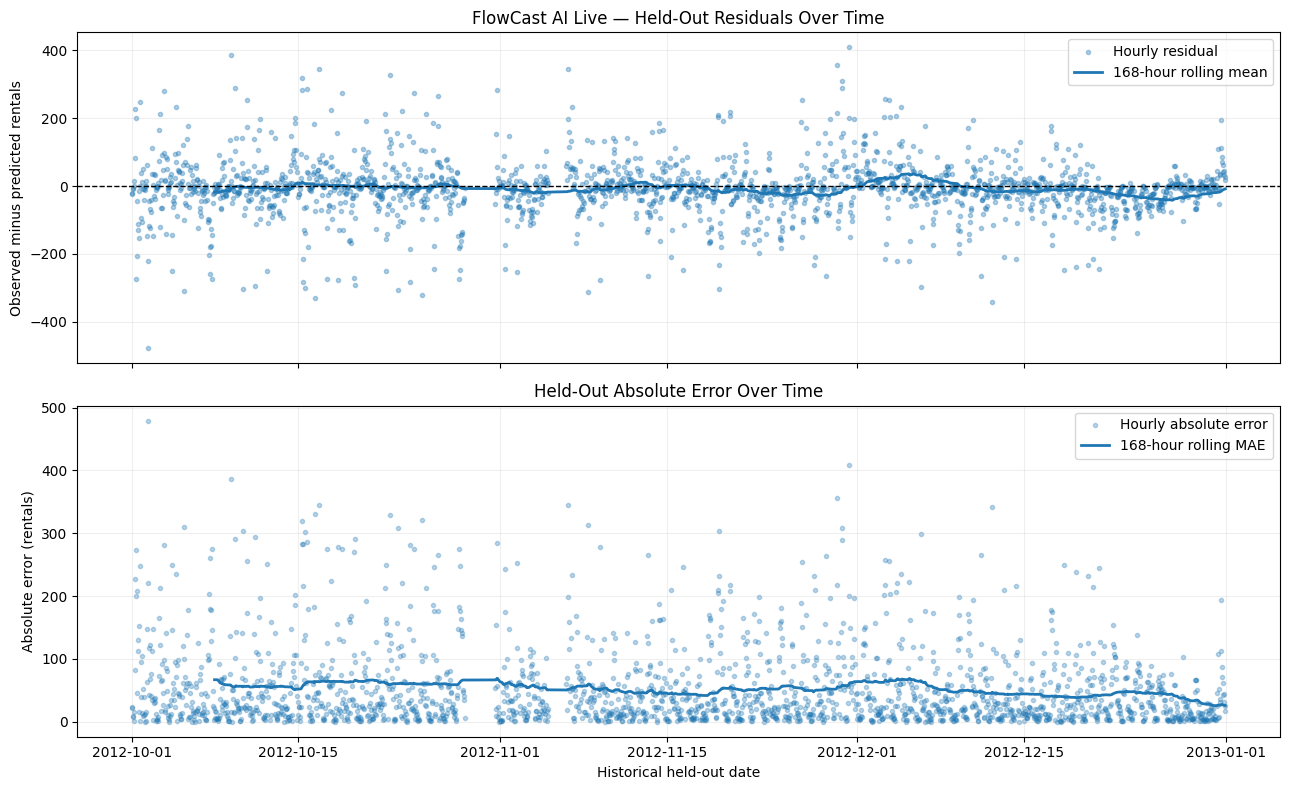

OVERALL MEAN RESIDUAL: -7.839
OVERALL MAE: 51.715


In [37]:

# R3 — RESIDUALS AGAINST HISTORICAL TIME

# Seven-day rolling mean (168 hourly observations)
residual_df["rolling_bias_168"] = (
    residual_df["residual"]
    .rolling(window=168, min_periods=168)
    .mean()
)

# Seven-day rolling mean absolute error
residual_df["rolling_mae_168"] = (
    residual_df["absolute_error"]
    .rolling(window=168, min_periods=168)
    .mean()
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 8),
    sharex=True
)

# Raw residuals over time
axes[0].scatter(
    residual_df["datetime"],
    residual_df["residual"],
    s=9,
    alpha=0.35,
    label="Hourly residual"
)

axes[0].plot(
    residual_df["datetime"],
    residual_df["rolling_bias_168"],
    linewidth=2,
    label="168-hour rolling mean"
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_title(
    "FlowCast AI Live — Held-Out Residuals Over Time"
)

axes[0].set_ylabel("Observed minus predicted rentals")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Absolute error over time
axes[1].scatter(
    residual_df["datetime"],
    residual_df["absolute_error"],
    s=9,
    alpha=0.3,
    label="Hourly absolute error"
)

axes[1].plot(
    residual_df["datetime"],
    residual_df["rolling_mae_168"],
    linewidth=2,
    label="168-hour rolling MAE"
)

axes[1].set_title(
    "Held-Out Absolute Error Over Time"
)

axes[1].set_xlabel("Historical held-out date")
axes[1].set_ylabel("Absolute error (rentals)")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()

print("OVERALL MEAN RESIDUAL:", round(mean_error, 3))
print("OVERALL MAE:", round(mae, 3))


RESIDUAL BIAS BY PREDICTED DEMAND


,n,mean_prediction,mean_residual,mae,rmse
0,210,9.723,-1.642,4.062,5.828
1,210,24.324,-1.319,10.560,13.146
2,210,57.798,-1.327,25.518,36.049
3,209,102.533,3.309,31.350,41.304
4,210,161.219,-1.171,42.420,61.366
5,210,231.222,-7.884,51.104,71.607
6,209,284.759,-24.969,62.206,79.829
7,210,347.927,-6.418,80.566,103.883
8,210,445.864,-0.240,91.962,114.387
9,210,626.900,-36.757,117.356,155.125


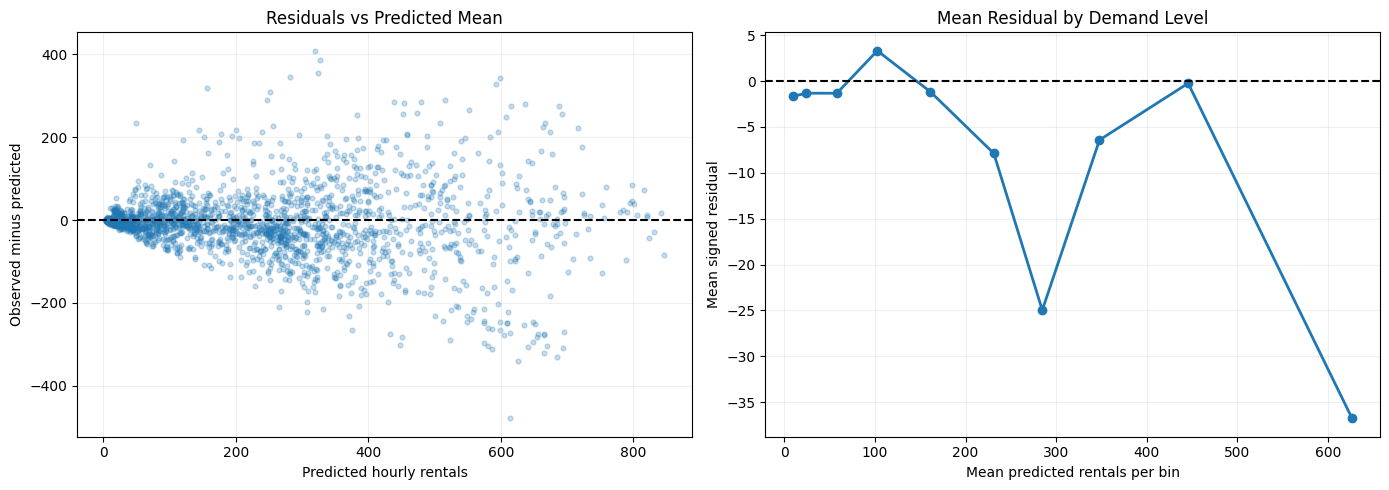

In [38]:

# R4 — RESIDUALS VS PREDICTED DEMAND

# Divide predicted means into approximately equal-frequency bins
residual_df["demand_bin"] = pd.qcut(
    residual_df["nb_mean"],
    q=10,
    duplicates="drop"
)

demand_bias = (
    residual_df.groupby(
        "demand_bin",
        observed=True
    )
    .agg(
        n=("residual", "size"),
        mean_prediction=("nb_mean", "mean"),
        mean_residual=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        )
    )
    .reset_index(drop=True)
)

print("RESIDUAL BIAS BY PREDICTED DEMAND")
display(demand_bias.round(3))

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Individual residuals
axes[0].scatter(
    residual_df["nb_mean"],
    residual_df["residual"],
    s=12,
    alpha=0.25
)

axes[0].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[0].set_title("Residuals vs Predicted Mean")
axes[0].set_xlabel("Predicted hourly rentals")
axes[0].set_ylabel("Observed minus predicted")
axes[0].grid(alpha=0.2)

# Average residual by demand level
axes[1].plot(
    demand_bias["mean_prediction"],
    demand_bias["mean_residual"],
    marker="o",
    linewidth=2
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set_title("Mean Residual by Demand Level")
axes[1].set_xlabel("Mean predicted rentals per bin")
axes[1].set_ylabel("Mean signed residual")
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()


NB2 PEARSON RESIDUAL DIAGNOSTICS


,Diagnostic,Value
0,Pearson residual mean,-0.0958
1,Pearson residual variance,1.0265
2,Pearson residual standard deviation,1.0132
3,Pearson residual RMS,1.0174
4,Fraction with absolute value > 2,0.0381


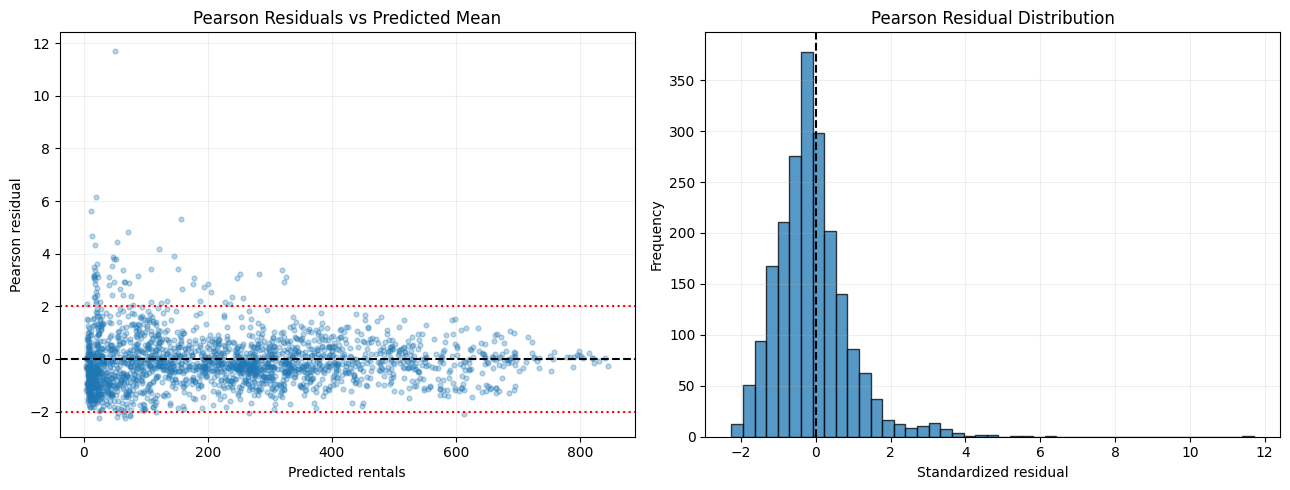

In [39]:

# R5 — PEARSON STANDARDIZED RESIDUALS

# NB2 model-implied conditional variance
residual_df["nb_variance"] = (
    residual_df["nb_mean"]
    + residual_alpha * residual_df["nb_mean"]**2
)

# Conditional standard deviation
residual_df["nb_std"] = np.sqrt(
    residual_df["nb_variance"]
)

# Pearson standardized residuals
residual_df["pearson_residual"] = (
    residual_df["residual"]
    / residual_df["nb_std"]
)

pearson_mean = residual_df[
    "pearson_residual"
].mean()

pearson_variance = residual_df[
    "pearson_residual"
].var(ddof=1)

pearson_rmse = np.sqrt(
    np.mean(
        residual_df["pearson_residual"]**2
    )
)

pearson_summary = pd.DataFrame({
    "Diagnostic": [
        "Pearson residual mean",
        "Pearson residual variance",
        "Pearson residual standard deviation",
        "Pearson residual RMS",
        "Fraction with absolute value > 2"
    ],
    "Value": [
        pearson_mean,
        pearson_variance,
        np.sqrt(pearson_variance),
        pearson_rmse,
        (
            np.abs(
                residual_df["pearson_residual"]
            ) > 2
        ).mean()
    ]
})

print("NB2 PEARSON RESIDUAL DIAGNOSTICS")
display(pearson_summary.round(4))

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].scatter(
    residual_df["nb_mean"],
    residual_df["pearson_residual"],
    s=12,
    alpha=0.3
)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].axhline(2, color="red", linestyle=":")
axes[0].axhline(-2, color="red", linestyle=":")

axes[0].set_title("Pearson Residuals vs Predicted Mean")
axes[0].set_xlabel("Predicted rentals")
axes[0].set_ylabel("Pearson residual")
axes[0].grid(alpha=0.2)

axes[1].hist(
    residual_df["pearson_residual"],
    bins=45,
    edgecolor="black",
    alpha=0.75
)

axes[1].axvline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set_title("Pearson Residual Distribution")
axes[1].set_xlabel("Standardized residual")
axes[1].set_ylabel("Frequency")
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()


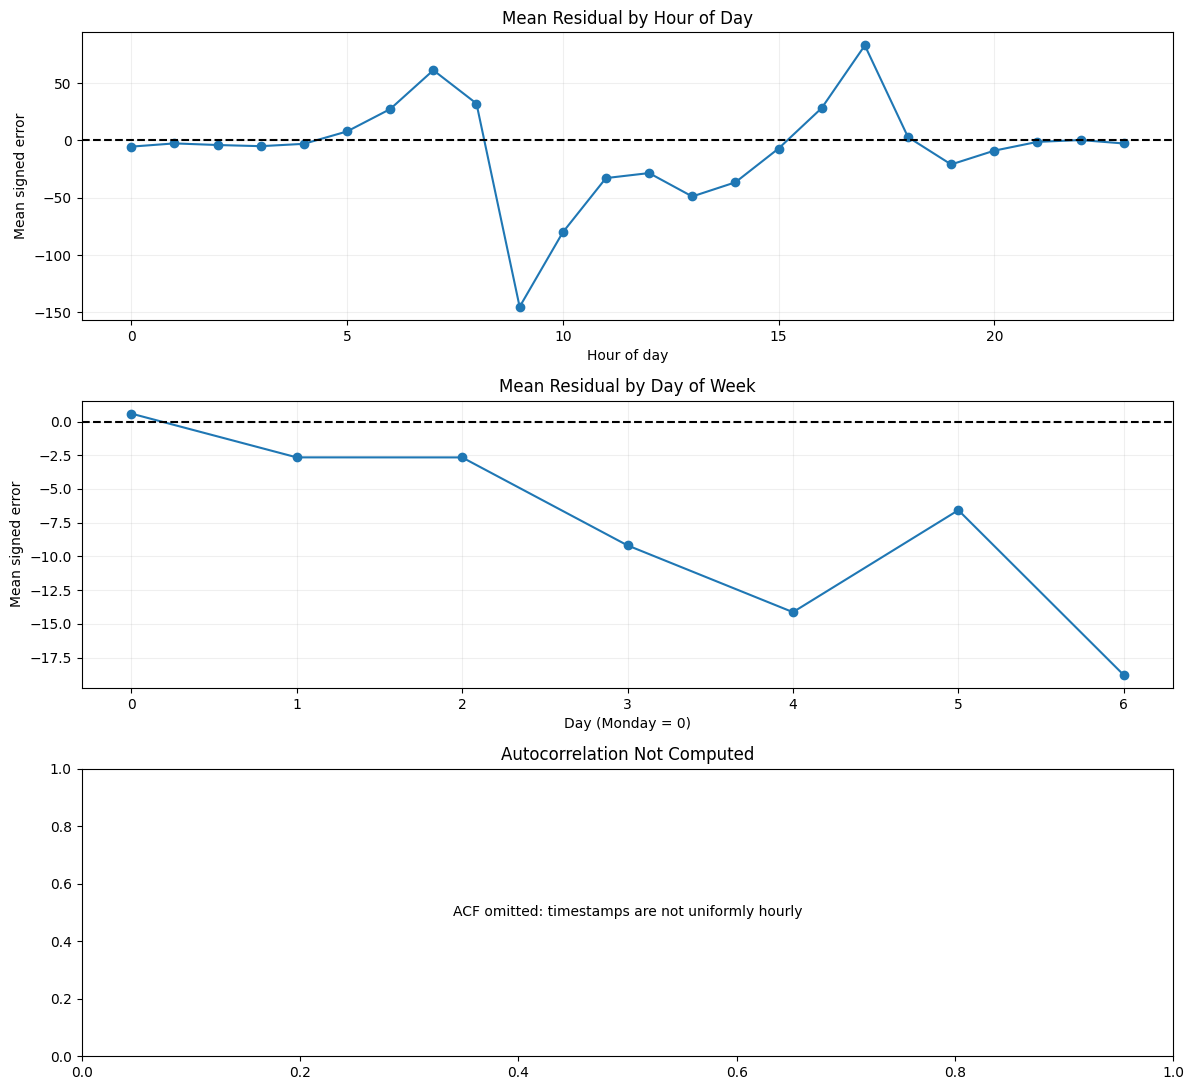

REGULAR HOURLY TIMESTAMPS: False

HOURLY ERROR SUMMARY


,hour,mean_error,mae,n
0,0,-5.378,21.982,89
1,1,-2.561,12.147,87
2,2,-3.972,9.272,87
3,3,-4.984,6.796,79
4,4,-2.943,4.051,82
5,5,7.869,11.497,86
6,6,27.367,31.080,87
7,7,61.257,79.865,87
8,8,32.185,79.811,87
9,9,-145.073,153.792,87



DAY-OF-WEEK ERROR SUMMARY


,day_of_week,mean_error,mae,n
0,0,0.586,67.234,287
1,1,-2.657,58.845,273
2,2,-2.660,54.748,298
3,3,-9.178,54.567,306
4,4,-14.124,50.267,310
5,5,-6.569,37.084,312
6,6,-18.781,41.578,312


In [40]:

# R6 — TEMPORAL ERROR STRUCTURE

# Calendar attributes
residual_df["hour"] = (
    residual_df["datetime"].dt.hour
)

residual_df["day_of_week"] = (
    residual_df["datetime"].dt.dayofweek
)

# Mean signed error by hour
hourly_bias = (
    residual_df.groupby("hour")
    .agg(
        mean_error=("residual", "mean"),
        mae=("absolute_error", "mean"),
        n=("residual", "size")
    )
    .reset_index()
)

# Mean signed error by day of week
weekly_bias = (
    residual_df.groupby("day_of_week")
    .agg(
        mean_error=("residual", "mean"),
        mae=("absolute_error", "mean"),
        n=("residual", "size")
    )
    .reset_index()
)

# Autocorrelation is meaningful at hourly lags
# only if consecutive rows represent consecutive hours.
time_gaps = residual_df["datetime"].diff().dropna()

regular_hourly = bool(
    (time_gaps == pd.Timedelta(hours=1)).all()
)

max_lag = min(168, m - 1)

if regular_hourly:
    acf_values = acf(
        residual_df["pearson_residual"].to_numpy(),
        nlags=max_lag,
        fft=True
    )
else:
    acf_values = None

fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 11)
)

axes[0].plot(
    hourly_bias["hour"],
    hourly_bias["mean_error"],
    marker="o"
)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Mean Residual by Hour of Day")
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("Mean signed error")
axes[0].grid(alpha=0.2)

axes[1].plot(
    weekly_bias["day_of_week"],
    weekly_bias["mean_error"],
    marker="o"
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Mean Residual by Day of Week")
axes[1].set_xlabel("Day (Monday = 0)")
axes[1].set_ylabel("Mean signed error")
axes[1].grid(alpha=0.2)

if regular_hourly:
    axes[2].bar(
        np.arange(1, max_lag + 1),
        acf_values[1:]
    )
    axes[2].axhline(0, color="black", linewidth=1)
    axes[2].set_title(
        "Pearson Residual Autocorrelation"
    )
    axes[2].set_xlabel("Lag (hours)")
    axes[2].set_ylabel("Autocorrelation")
else:
    axes[2].text(
        0.5, 0.5,
        "ACF omitted: timestamps are not uniformly hourly",
        ha="center",
        va="center",
        transform=axes[2].transAxes
    )
    axes[2].set_title("Autocorrelation Not Computed")

fig.tight_layout()
plt.show()

print("REGULAR HOURLY TIMESTAMPS:", regular_hourly)

print("\nHOURLY ERROR SUMMARY")
display(hourly_bias.round(3))

print("\nDAY-OF-WEEK ERROR SUMMARY")
display(weekly_bias.round(3))


FLOWCAST AI LIVE — PREDICTIVE INTERVAL CALIBRATION


,Nominal coverage,Empirical coverage,Model-implied coverage,Empirical minus nominal,Empirical minus model-implied,Average interval width
0,0.50,0.5815,0.5144,0.0815,0.0671,114.4738
1,0.80,0.8341,0.8085,0.0341,0.0256,218.5667
2,0.90,0.9104,0.9050,0.0104,0.0054,281.7612
3,0.95,0.9418,0.9531,-0.0082,-0.0112,337.3265


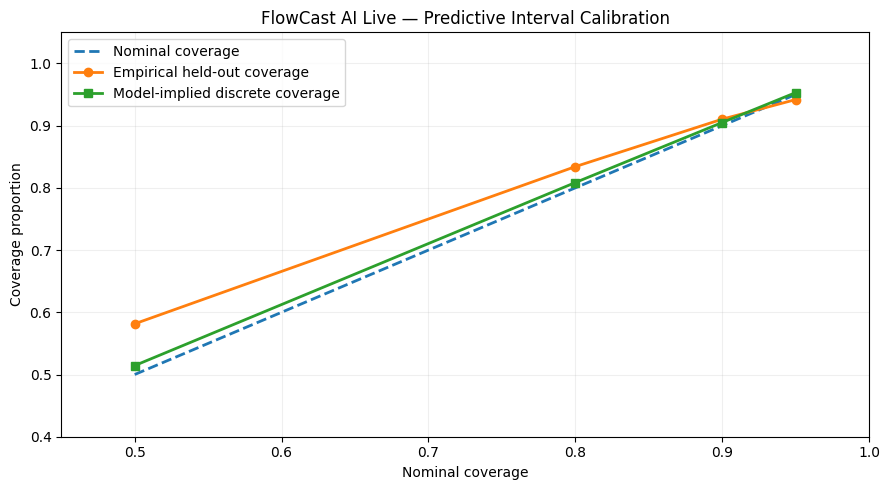

In [41]:

# R7 — HELD-OUT PREDICTIVE INTERVAL CALIBRATION

# NB2 parameters for each held-out hour
nb_size = 1.0 / residual_alpha

nb_p = nb_size / (
    nb_size + predicted
)

nominal_levels = [0.50, 0.80, 0.90, 0.95]

coverage_records = []

for level in nominal_levels:

    lower_tail = (1.0 - level) / 2.0
    upper_tail = 1.0 - lower_tail

    # Discrete NB2 predictive quantiles
    lower = nbinom.ppf(
        lower_tail,
        nb_size,
        nb_p
    )

    upper = nbinom.ppf(
        upper_tail,
        nb_size,
        nb_p
    )

    # Observed empirical coverage
    covered = (
        (observed >= lower)
        &
        (observed <= upper)
    )

    empirical_coverage = covered.mean()

    # Model-implied probability of the inclusive interval
    # This can exceed nominal coverage for discrete counts.
    model_interval_probability = (
        nbinom.cdf(upper, nb_size, nb_p)
        -
        nbinom.cdf(lower - 1, nb_size, nb_p)
    )

    # Save hour-level diagnostics
    pct = int(level * 100)

    residual_df[f"lower_{pct}"] = lower
    residual_df[f"upper_{pct}"] = upper
    residual_df[f"covered_{pct}"] = covered

    coverage_records.append({
        "Nominal coverage": level,
        "Empirical coverage": empirical_coverage,
        "Model-implied coverage": (
            model_interval_probability.mean()
        ),
        "Empirical minus nominal": (
            empirical_coverage - level
        ),
        "Empirical minus model-implied": (
            empirical_coverage
            - model_interval_probability.mean()
        ),
        "Average interval width": (
            upper - lower
        ).mean()
    })

coverage_results = pd.DataFrame(
    coverage_records
)

print("=" * 70)
print("FLOWCAST AI LIVE — PREDICTIVE INTERVAL CALIBRATION")
print("=" * 70)

display(coverage_results.round(4))

# Plot empirical, nominal, and model-implied coverage
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    nominal_levels,
    nominal_levels,
    linestyle="--",
    linewidth=2,
    label="Nominal coverage"
)

ax.plot(
    coverage_results["Nominal coverage"],
    coverage_results["Empirical coverage"],
    marker="o",
    linewidth=2,
    label="Empirical held-out coverage"
)

ax.plot(
    coverage_results["Nominal coverage"],
    coverage_results["Model-implied coverage"],
    marker="s",
    linewidth=2,
    label="Model-implied discrete coverage"
)

ax.set_title(
    "FlowCast AI Live — Predictive Interval Calibration"
)

ax.set_xlabel("Nominal coverage")
ax.set_ylabel("Coverage proportion")
ax.set_xlim(0.45, 1.0)
ax.set_ylim(0.40, 1.05)
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


RANDOMIZED PIT CALIBRATION


,Diagnostic,Value
0,PIT sample mean,0.47101
1,Uniform theoretical mean,0.50000
2,PIT sample variance,0.07308
3,Uniform theoretical variance,0.08333
4,KS statistic,0.07722
5,KS nominal p-value,0.00000


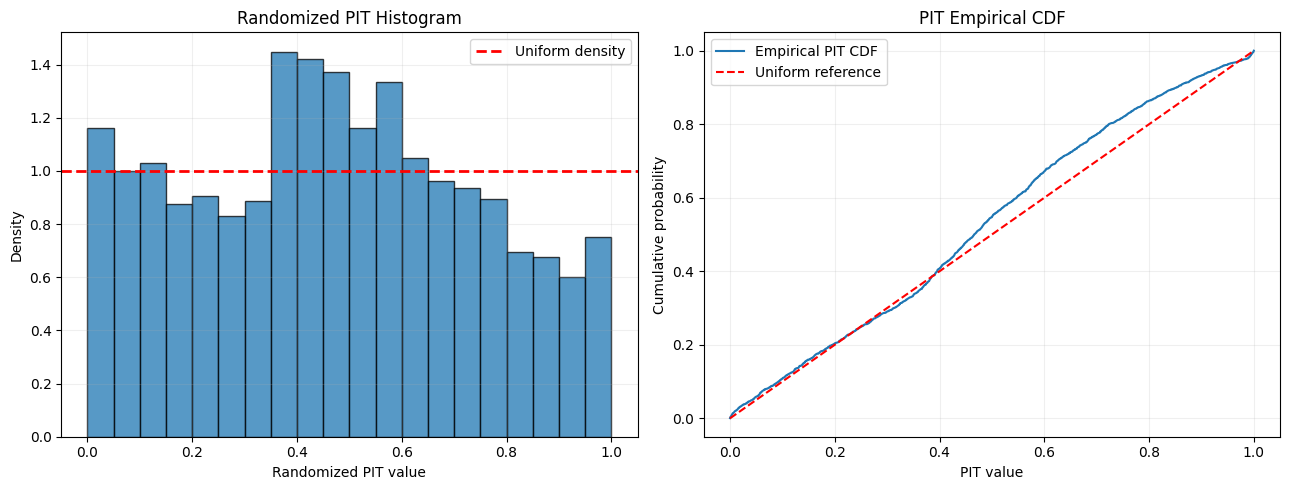


Note: The standard KS p-value is descriptive unless PIT observations can be treated as independent.


In [42]:

# R8 — RANDOMIZED PROBABILITY INTEGRAL TRANSFORM

# Observed counts as integers
observed_integer = observed.astype(int)

# CDF immediately below the observed count
cdf_below = nbinom.cdf(
    observed_integer - 1,
    nb_size,
    nb_p
)

# CDF at the observed count
cdf_at = nbinom.cdf(
    observed_integer,
    nb_size,
    nb_p
)

# Reproducible randomization within each probability jump
uniform_draws = pit_rng.uniform(
    0.0, 1.0, size=m
)

randomized_pit = (
    cdf_below
    + uniform_draws * (cdf_at - cdf_below)
)

residual_df["randomized_pit"] = randomized_pit

assert np.isfinite(randomized_pit).all()
assert ((randomized_pit >= 0) & (randomized_pit <= 1)).all()

# Summary statistics
pit_mean = randomized_pit.mean()
pit_variance = randomized_pit.var(ddof=1)

# Descriptive KS comparison against Uniform(0,1)
# Standard p-values assume independent PIT observations.
ks_result = kstest(
    randomized_pit,
    "uniform"
)

pit_summary = pd.DataFrame({
    "Diagnostic": [
        "PIT sample mean",
        "Uniform theoretical mean",
        "PIT sample variance",
        "Uniform theoretical variance",
        "KS statistic",
        "KS nominal p-value"
    ],
    "Value": [
        pit_mean,
        0.5,
        pit_variance,
        1.0 / 12.0,
        ks_result.statistic,
        ks_result.pvalue
    ]
})

print("RANDOMIZED PIT CALIBRATION")
display(pit_summary.round(5))

# Histogram against uniform density
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].hist(
    randomized_pit,
    bins=np.linspace(0, 1, 21),
    density=True,
    edgecolor="black",
    alpha=0.75
)

axes[0].axhline(
    1.0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Uniform density"
)

axes[0].set_title("Randomized PIT Histogram")
axes[0].set_xlabel("Randomized PIT value")
axes[0].set_ylabel("Density")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Empirical PIT CDF
sorted_pit = np.sort(randomized_pit)

empirical_cdf = (
    np.arange(1, m + 1) / m
)

axes[1].plot(
    sorted_pit,
    empirical_cdf,
    label="Empirical PIT CDF"
)

axes[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="red",
    label="Uniform reference"
)

axes[1].set_title("PIT Empirical CDF")
axes[1].set_xlabel("PIT value")
axes[1].set_ylabel("Cumulative probability")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()

print(
    "\nNote: The standard KS p-value is descriptive "
    "unless PIT observations can be treated as independent."
)


FLOWCAST AI LIVE — ERROR GROWTH BY DEMAND


,observations,mean_prediction,mean_observed,signed_bias,mae,rmse,scaled_mae,predicted_sd,pearson_rms
0,210,9.723,8.081,-1.642,4.062,5.828,0.406,4.779,1.074
1,210,24.324,23.005,-1.319,10.560,13.146,0.457,10.349,1.357
2,210,57.798,56.471,-1.327,25.518,36.049,0.445,22.925,1.599
3,209,102.533,105.842,3.309,31.350,41.304,0.307,39.684,1.027
4,210,161.219,160.048,-1.171,42.420,61.366,0.264,61.654,0.994
5,210,231.222,223.338,-7.884,51.104,71.607,0.221,87.856,0.809
6,209,284.759,259.789,-24.969,62.206,79.829,0.218,107.893,0.738
7,210,347.927,341.510,-6.418,80.566,103.883,0.232,131.534,0.796
8,210,445.864,445.624,-0.240,91.962,114.387,0.207,168.187,0.679
9,210,626.900,590.143,-36.757,117.356,155.125,0.192,235.938,0.677


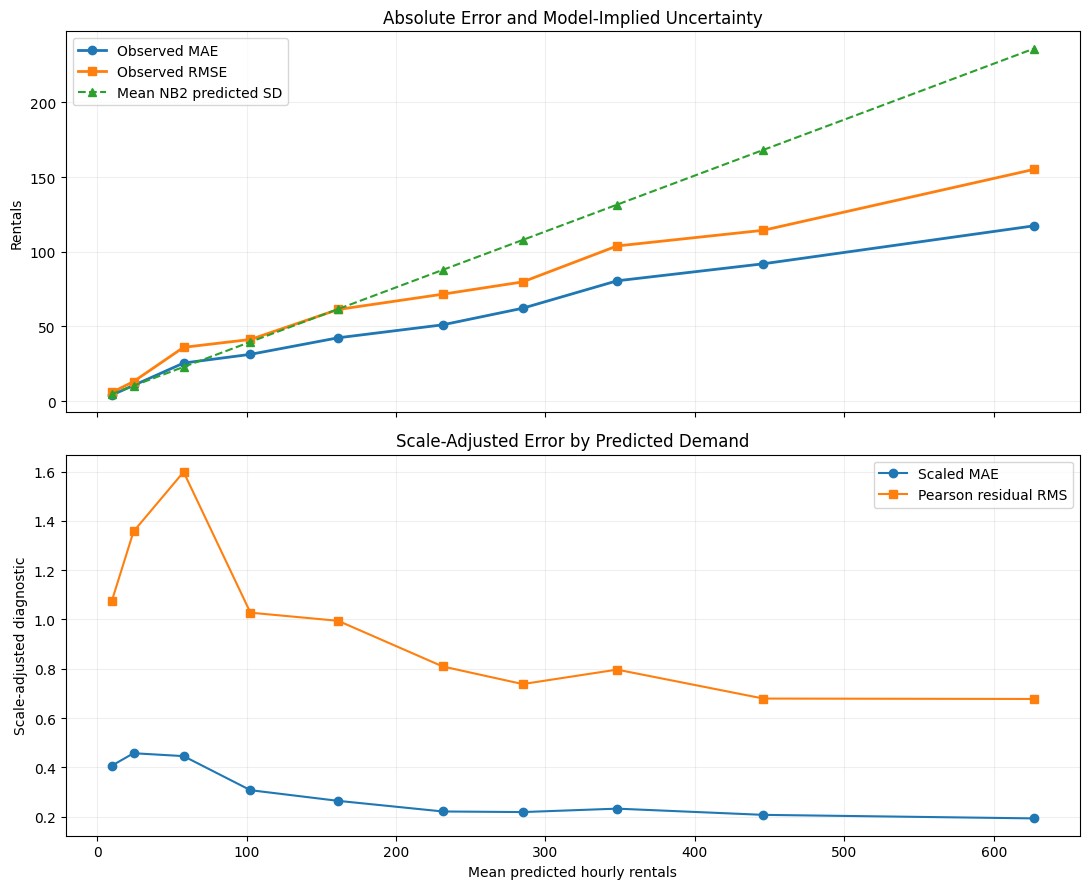

Correlation between predicted demand and absolute error: 0.5324


In [43]:

# R9 — ERROR MAGNITUDE VS PREDICTED DEMAND

error_growth = (
    residual_df.groupby(
        "demand_bin",
        observed=True
    )
    .agg(
        observations=("absolute_error", "size"),
        mean_prediction=("nb_mean", "mean"),
        mean_observed=("cnt", "mean"),
        signed_bias=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        ),
        scaled_mae=("scaled_absolute_error", "mean"),
        predicted_sd=("nb_std", "mean"),
        pearson_rms=(
            "pearson_residual",
            lambda x: np.sqrt(np.mean(x**2))
        )
    )
    .reset_index(drop=True)
)

print("=" * 70)
print("FLOWCAST AI LIVE — ERROR GROWTH BY DEMAND")
print("=" * 70)

display(error_growth.round(3))

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 9),
    sharex=True
)

# Absolute error growth
axes[0].plot(
    error_growth["mean_prediction"],
    error_growth["mae"],
    marker="o",
    linewidth=2,
    label="Observed MAE"
)

axes[0].plot(
    error_growth["mean_prediction"],
    error_growth["rmse"],
    marker="s",
    linewidth=2,
    label="Observed RMSE"
)

axes[0].plot(
    error_growth["mean_prediction"],
    error_growth["predicted_sd"],
    marker="^",
    linestyle="--",
    label="Mean NB2 predicted SD"
)

axes[0].set_title(
    "Absolute Error and Model-Implied Uncertainty"
)

axes[0].set_ylabel("Rentals")
axes[0].legend()
axes[0].grid(alpha=0.2)

# Scale-adjusted diagnostics
axes[1].plot(
    error_growth["mean_prediction"],
    error_growth["scaled_mae"],
    marker="o",
    label="Scaled MAE"
)

axes[1].plot(
    error_growth["mean_prediction"],
    error_growth["pearson_rms"],
    marker="s",
    label="Pearson residual RMS"
)

axes[1].set_title(
    "Scale-Adjusted Error by Predicted Demand"
)

axes[1].set_xlabel("Mean predicted hourly rentals")
axes[1].set_ylabel("Scale-adjusted diagnostic")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()

# Descriptive relationship between forecast size and error
demand_error_correlation = np.corrcoef(
    residual_df["nb_mean"],
    residual_df["absolute_error"]
)[0, 1]

print(
    "Correlation between predicted demand and absolute error:",
    round(demand_error_correlation, 4)
)


MONTHLY HELD-OUT ERROR


,month,observations,mean_prediction,signed_bias,mae,rmse,coverage90,coverage95
0,2012-10,684,290.896,-4.766,61.817,96.909,0.930,0.958
1,2012-11,677,222.557,-8.179,52.798,80.651,0.898,0.935
2,2012-12,737,178.215,-10.378,41.345,64.985,0.904,0.934



WEEKLY HELD-OUT ERROR


,test_week,observations,signed_bias,mae,rmse,coverage90
0,1,168,-16.965,66.840,101.954,0.905
1,2,168,8.076,51.737,82.863,0.952
2,3,168,-5.453,62.886,101.006,0.935
3,4,168,-7.652,66.463,100.531,0.923
4,5,108,-17.193,44.501,68.375,0.944
5,6,129,12.042,50.228,78.473,0.922
6,7,167,-15.299,45.553,68.063,0.934
7,8,168,-24.354,53.948,80.459,0.881
8,9,165,23.004,63.426,96.615,0.867
9,10,167,-2.308,49.945,79.637,0.946


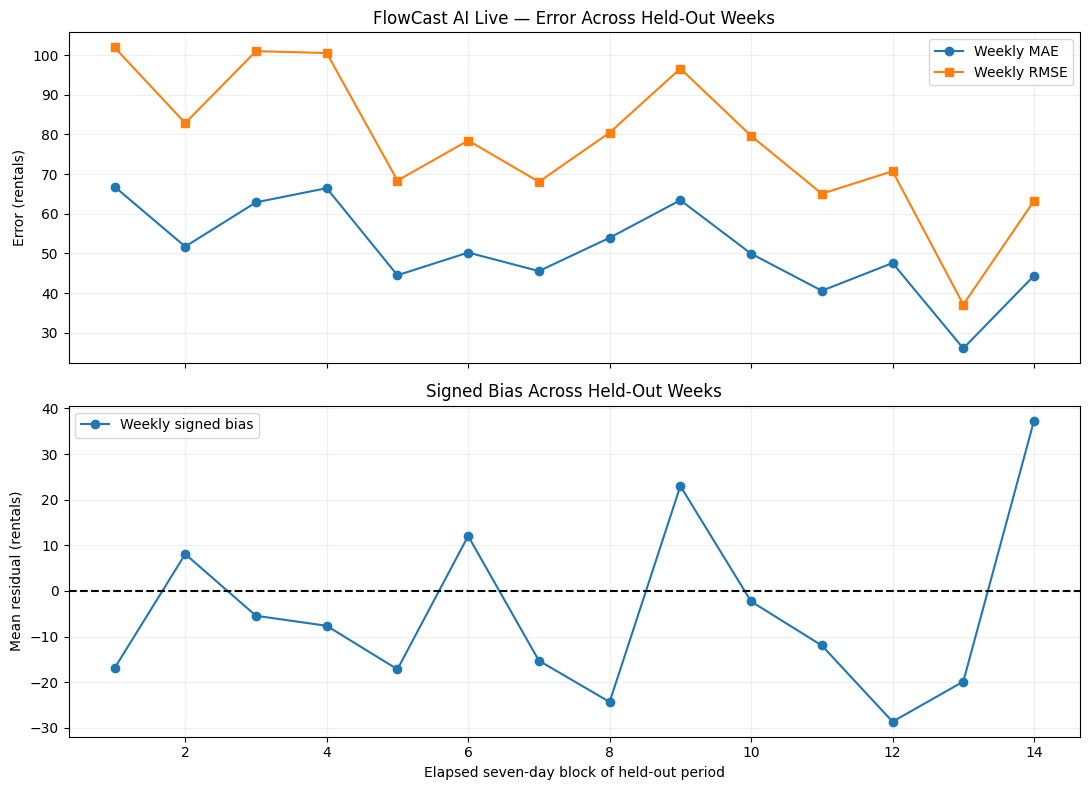


Interpretation: These are elapsed calendar-time diagnostics, not multi-step forecast horizons.


In [44]:

# R10 — ERROR ACROSS THE HISTORICAL TEST PERIOD

# Calendar month
residual_df["month"] = (
    residual_df["datetime"].dt.to_period("M").astype(str)
)

# Consecutive seven-day blocks from the first test timestamp
first_test_time = residual_df["datetime"].min()

residual_df["elapsed_days"] = (
    residual_df["datetime"] - first_test_time
).dt.total_seconds() / 86400.0

residual_df["test_week"] = (
    np.floor(
        residual_df["elapsed_days"] / 7.0
    ).astype(int) + 1
)

# Monthly diagnostics
monthly_error = (
    residual_df.groupby("month")
    .agg(
        observations=("residual", "size"),
        mean_prediction=("nb_mean", "mean"),
        signed_bias=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        ),
        coverage90=("covered_90", "mean"),
        coverage95=("covered_95", "mean")
    )
    .reset_index()
)

# Weekly diagnostics
weekly_error = (
    residual_df.groupby("test_week")
    .agg(
        observations=("residual", "size"),
        signed_bias=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        ),
        coverage90=("covered_90", "mean")
    )
    .reset_index()
)

print("MONTHLY HELD-OUT ERROR")
display(monthly_error.round(3))

print("\nWEEKLY HELD-OUT ERROR")
display(weekly_error.round(3))

fig, axes = plt.subplots(
    2, 1,
    figsize=(11, 8),
    sharex=True
)

axes[0].plot(
    weekly_error["test_week"],
    weekly_error["mae"],
    marker="o",
    label="Weekly MAE"
)

axes[0].plot(
    weekly_error["test_week"],
    weekly_error["rmse"],
    marker="s",
    label="Weekly RMSE"
)

axes[0].set_title(
    "FlowCast AI Live — Error Across Held-Out Weeks"
)

axes[0].set_ylabel("Error (rentals)")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    weekly_error["test_week"],
    weekly_error["signed_bias"],
    marker="o",
    label="Weekly signed bias"
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--"
)

axes[1].set_title(
    "Signed Bias Across Held-Out Weeks"
)

axes[1].set_xlabel(
    "Elapsed seven-day block of held-out period"
)

axes[1].set_ylabel("Mean residual (rentals)")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()

print(
    "\nInterpretation: These are elapsed calendar-time "
    "diagnostics, not multi-step forecast horizons."
)


In [45]:

# R11 — FINAL RESIDUAL AND CALIBRATION SUMMARY

# Summary of point-forecast and standardized errors
final_diagnostics = pd.DataFrame({
    "Category": [
        "Residuals",
        "Residuals",
        "Residuals",
        "Residuals",
        "Standardized residuals",
        "Standardized residuals",
        "Calibration",
        "Calibration",
        "Calibration",
        "Calibration",
        "Error growth",
        "Temporal structure"
    ],
    "Diagnostic": [
        "Mean signed error",
        "Mean absolute error",
        "Root mean squared error",
        "Median absolute error",
        "Pearson residual mean",
        "Pearson residual variance",
        "90% empirical coverage",
        "95% empirical coverage",
        "Randomized PIT mean",
        "PIT KS statistic",
        "Demand vs absolute error correlation",
        "Regular hourly timestamps"
    ],
    "Value": [
        mean_error,
        mae,
        rmse,
        median_ae,
        pearson_mean,
        pearson_variance,
        residual_df["covered_90"].mean(),
        residual_df["covered_95"].mean(),
        pit_mean,
        ks_result.statistic,
        demand_error_correlation,
        regular_hourly
    ]
})

print("=" * 75)
print("FLOWCAST AI LIVE — FINAL RESIDUALS AND CALIBRATION")
print("=" * 75)

display(final_diagnostics.round(4))

print("\nPREDICTIVE INTERVAL CALIBRATION")
display(coverage_results.round(4))

print("\nERROR BY PREDICTED DEMAND")
display(error_growth.round(3))

print("\nERROR BY HISTORICAL TEST MONTH")
display(monthly_error.round(3))

# Reproducibility and scope
print("\nREPRODUCIBILITY")
print("Master project seed:", RESIDUAL_SEED)
print("Held-out observations:", m)
print("NB2 dispersion:", round(residual_alpha, 6))
print("Main regression refitted: NO")

print("\nSTATISTICAL SCOPE")
print(
    "Residuals evaluate point-forecast errors."
)
print(
    "Predictive intervals and PIT evaluate "
    "probabilistic calibration."
)
print(
    "Demand bins and calendar blocks evaluate "
    "variation in error magnitude."
)
print(
    "These results do not demonstrate "
    "present-day operational accuracy."
)


FLOWCAST AI LIVE — FINAL RESIDUALS AND CALIBRATION


,Category,Diagnostic,Value
0,Residuals,Mean signed error,-7.838933
1,Residuals,Mean absolute error,51.715073
2,Residuals,Root mean squared error,81.512411
3,Residuals,Median absolute error,28.413218
4,Standardized residuals,Pearson residual mean,-0.095795
5,Standardized residuals,Pearson residual variance,1.026505
6,Calibration,90% empirical coverage,0.910391
7,Calibration,95% empirical coverage,0.941849
8,Calibration,Randomized PIT mean,0.471012
9,Calibration,PIT KS statistic,0.077223



PREDICTIVE INTERVAL CALIBRATION


,Nominal coverage,Empirical coverage,Model-implied coverage,Empirical minus nominal,Empirical minus model-implied,Average interval width
0,0.50,0.5815,0.5144,0.0815,0.0671,114.4738
1,0.80,0.8341,0.8085,0.0341,0.0256,218.5667
2,0.90,0.9104,0.9050,0.0104,0.0054,281.7612
3,0.95,0.9418,0.9531,-0.0082,-0.0112,337.3265



ERROR BY PREDICTED DEMAND


,observations,mean_prediction,mean_observed,signed_bias,mae,rmse,scaled_mae,predicted_sd,pearson_rms
0,210,9.723,8.081,-1.642,4.062,5.828,0.406,4.779,1.074
1,210,24.324,23.005,-1.319,10.560,13.146,0.457,10.349,1.357
2,210,57.798,56.471,-1.327,25.518,36.049,0.445,22.925,1.599
3,209,102.533,105.842,3.309,31.350,41.304,0.307,39.684,1.027
4,210,161.219,160.048,-1.171,42.420,61.366,0.264,61.654,0.994
5,210,231.222,223.338,-7.884,51.104,71.607,0.221,87.856,0.809
6,209,284.759,259.789,-24.969,62.206,79.829,0.218,107.893,0.738
7,210,347.927,341.510,-6.418,80.566,103.883,0.232,131.534,0.796
8,210,445.864,445.624,-0.240,91.962,114.387,0.207,168.187,0.679
9,210,626.900,590.143,-36.757,117.356,155.125,0.192,235.938,0.677



ERROR BY HISTORICAL TEST MONTH


,month,observations,mean_prediction,signed_bias,mae,rmse,coverage90,coverage95
0,2012-10,684,290.896,-4.766,61.817,96.909,0.930,0.958
1,2012-11,677,222.557,-8.179,52.798,80.651,0.898,0.935
2,2012-12,737,178.215,-10.378,41.345,64.985,0.904,0.934



REPRODUCIBILITY
Master project seed: 20261112
Held-out observations: 2098
NB2 dispersion: 0.140049
Main regression refitted: NO

STATISTICAL SCOPE
Residuals evaluate point-forecast errors.
Predictive intervals and PIT evaluate probabilistic calibration.
Demand bins and calendar blocks evaluate variation in error magnitude.
These results do not demonstrate present-day operational accuracy.



# Residuals and Calibration — Results and Interpretation

## 1. Held-Out Residual Behavior

The FlowCast AI Live negative binomial (NB2) regression was evaluated using historical held-out hourly completed bicycle-sharing rental counts from October–December 2012.

For each held-out hour $t$, the raw residual is defined as:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
}
$$

where $D_t$ is the observed completed rental count and $\widehat{\mu}_t$ is the fitted conditional mean.

The mean signed error is:

$$
\boxed{
ME=\frac{1}{m}\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)
}
$$

The observed held-out mean error was:

$$
\boxed{
ME=\text{[INSERT VALUE] rentals}
}
$$

This indicates **[DESCRIBE THE DIRECTION AND MAGNITUDE OF BIAS]**.

A positive mean error indicates average underprediction, whereas a negative mean error indicates average overprediction.

The mean absolute error is:

$$
\boxed{
MAE=
\frac{1}{m}
\sum_{t=1}^{m}
|D_t-\widehat{\mu}_t|
}
$$

The root mean squared error is:

$$
\boxed{
RMSE=
\sqrt{
\frac{1}{m}
\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)^2
}
}
$$

The observed error magnitudes were:

$$
\boxed{
\begin{aligned}
MAE&=\text{[INSERT VALUE] rentals}\\
RMSE&=\text{[INSERT VALUE] rentals}
\end{aligned}
}
$$

Residuals plotted against historical timestamps showed **[DESCRIBE THE ACTUAL TEMPORAL PATTERN]**.

To identify persistent prediction bias, a 168-hour rolling mean residual was calculated:

$$
\boxed{
\overline e_t^{(168)}
=
\frac{1}{168}
\sum_{j=0}^{167}
e_{t-j}
}
$$

The rolling residual mean **[DESCRIBE WHETHER IT REMAINED NEAR ZERO OR SHOWED PERSISTENT POSITIVE OR NEGATIVE DEVIATIONS]**.

These results suggest **[DESCRIBE WHETHER THE ERRORS APPEAR APPROXIMATELY NOISE-LIKE OR SYSTEMATICALLY STRUCTURED]**.

A mean residual near zero alone does not establish unbiased predictions across individual hours or demand levels.

---

## 2. Residuals Against Predicted Demand

Raw residuals were compared against fitted conditional means:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
\quad\text{versus}\quad
\widehat{\mu}_t
}
$$

The observations were grouped into predicted-demand quantile bins:

$$
\mathcal B_1,\mathcal B_2,\ldots,\mathcal B_K
$$

For each bin $k$, the mean signed residual was calculated as:

$$
\boxed{
\overline e_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
(D_t-\widehat{\mu}_t)
}
$$

where:

$$
n_k=|\mathcal B_k|
$$

The analysis showed **[DESCRIBE LOW-, MEDIUM-, AND HIGH-DEMAND BIAS]**.

The direction of residual bias is interpreted as:

$$
\boxed{
\begin{aligned}
\overline e_k>0
&\Longrightarrow \text{Underprediction}\\
\overline e_k<0
&\Longrightarrow \text{Overprediction}\\
\overline e_k\approx0
&\Longrightarrow \text{Small average signed bias}
\end{aligned}
}
$$

To account for the NB2 model-implied conditional variance, Pearson standardized residuals were calculated:

$$
\boxed{
r_t^P
=
\frac{
D_t-\widehat{\mu}_t
}{
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
}
$$

The empirical Pearson residual mean is:

$$
\overline r^P
=
\frac{1}{m}
\sum_{t=1}^{m}r_t^P
$$

The empirical Pearson residual variance is:

$$
s_P^2
=
\frac{1}{m-1}
\sum_{t=1}^{m}
(r_t^P-\overline r^P)^2
$$

The observed standardized residual statistics were:

$$
\boxed{
\begin{aligned}
\overline r^P&=\text{[INSERT VALUE]}\\
s_P^2&=\text{[INSERT VALUE]}
\end{aligned}
}
$$

Under a correctly specified conditional mean and variance model, the diagnostic targets are approximately:

$$
\boxed{
\mathbb E[r_t^P\mid X_t]\approx0,
\qquad
\operatorname{Var}(r_t^P\mid X_t)\approx1
}
$$

The observed standardized diagnostics indicate **[DESCRIBE WHETHER ERROR VARIABILITY IS CONSISTENT WITH THE MODEL-IMPLIED NB2 VARIANCE]**.

Because the observations are discrete counts, Pearson residuals are not assumed to follow an exact normal distribution.

---

## 3. Temporal Error Structure

Residual errors were examined by hour of day, day of week, and historical test week.

For hour-of-day group $\mathcal H_h$, the mean signed error is:

$$
\boxed{
ME_h
=
\frac{1}{|\mathcal H_h|}
\sum_{t\in\mathcal H_h}e_t
}
$$

For day-of-week group $\mathcal W_d$:

$$
\boxed{
ME_d
=
\frac{1}{|\mathcal W_d|}
\sum_{t\in\mathcal W_d}e_t
}
$$

For historical test-week group $\mathcal T_j$:

$$
\boxed{
ME_j
=
\frac{1}{|\mathcal T_j|}
\sum_{t\in\mathcal T_j}e_t
}
$$

The analysis identified **[DESCRIBE ANY SYSTEMATIC HOURLY, WEEKLY, OR CALENDAR PATTERNS]**.

Residual autocorrelation at lag $k$ is defined as:

$$
\boxed{
\widehat{\rho}(k)
=
\operatorname{Corr}(e_t,e_{t-k})
}
$$

For equally spaced hourly observations, a sample autocorrelation estimator is:

$$
\boxed{
\widehat{\rho}(k)
=
\frac{
\sum_{t=k+1}^{m}
(e_t-\overline e)(e_{t-k}-\overline e)
}{
\sum_{t=1}^{m}
(e_t-\overline e)^2
}
}
$$

The autocorrelation diagnostics showed **[DESCRIBE THE ACTUAL ACF RESULTS OR STATE THAT ACF WAS NOT COMPUTED BECAUSE OF IRREGULAR TIMESTAMPS]**.

Persistent residual dependence or recurring calendar patterns would suggest that some historical temporal variation remains unexplained by the fitted regression.

These diagnostics are descriptive and do not independently establish causality.

---

## 4. Predictive Calibration

The fitted NB2 predictive distribution was evaluated using central predictive intervals with nominal coverage levels:

$$
\boxed{
c\in\{0.50,0.80,0.90,0.95\}
}
$$

For each held-out hour, the predictive interval bounds are:

$$
\boxed{
L_t(c)
=
F_{\mathrm{NB}}^{-1}
\left(
\frac{1-c}{2};
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

$$
\boxed{
U_t(c)
=
F_{\mathrm{NB}}^{-1}
\left(
\frac{1+c}{2};
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

The empirical held-out coverage is:

$$
\boxed{
\widehat C(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

The observed coverage results were:

$$
\boxed{
\begin{aligned}
\widehat C(0.50)&=\text{[INSERT VALUE]}\\
\widehat C(0.80)&=\text{[INSERT VALUE]}\\
\widehat C(0.90)&=\text{[INSERT VALUE]}\\
\widehat C(0.95)&=\text{[INSERT VALUE]}
\end{aligned}
}
$$

In particular:

$$
\boxed{
\begin{aligned}
\text{Empirical 90\% coverage}
&=\text{[INSERT VALUE]}\\
\text{Empirical 95\% coverage}
&=\text{[INSERT VALUE]}
\end{aligned}
}
$$

The nominal interval probabilities were:

$$
\boxed{
\begin{aligned}
c_{90}&=0.90\\
c_{95}&=0.95
\end{aligned}
}
$$

The corresponding average model-implied interval coverage probabilities, accounting for discrete quantile endpoints, can be calculated as:

$$
\boxed{
\overline C_{\mathrm{model}}(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\left[
F_t(U_t(c))-F_t(L_t(c)-1)
\right]
}
$$

The calculated model-implied coverage probabilities were:

$$
\boxed{
\begin{aligned}
\overline C_{\mathrm{model}}(0.90)
&=\text{[INSERT VALUE]}\\
\overline C_{\mathrm{model}}(0.95)
&=\text{[INSERT VALUE]}
\end{aligned}
}
$$

The coverage differences are:

$$
\boxed{
\Delta C(c)
=
\widehat C(c)
-
\overline C_{\mathrm{model}}(c)
}
$$

These comparisons indicate **[DESCRIBE WHETHER EMPIRICAL COVERAGE AGREES WITH MODEL-IMPLIED COVERAGE]**.

Because count outcomes are discrete, central quantile intervals can have coverage above their nominal levels even under a correctly specified predictive distribution.

### Randomized Probability Integral Transform

Randomized PIT diagnostics were used to evaluate the fitted discrete predictive distribution.

For observed count $D_t=d_t$:

$$
\boxed{
u_t
=
F_t(d_t-1)
+
v_t
\left[
F_t(d_t)-F_t(d_t-1)
\right]
}
$$

where:

$$
v_t\sim\operatorname{Uniform}(0,1)
$$

The empirical PIT mean is:

$$
\boxed{
\overline u
=
\frac{1}{m}
\sum_{t=1}^{m}u_t
}
$$

The observed PIT mean was:

$$
\boxed{
\overline u=\text{[INSERT VALUE]}
}
$$

Under a correctly specified conditional predictive distribution, the theoretical reference is:

$$
\boxed{
u_t\sim\operatorname{Uniform}(0,1)
}
$$

with:

$$
\mathbb E[u_t]=0.5,
\qquad
\operatorname{Var}(u_t)=\frac{1}{12}
$$

The PIT histogram showed **[DESCRIBE WHETHER IT WAS APPROXIMATELY UNIFORM, U-SHAPED, HUMP-SHAPED, OR ASYMMETRIC]**.

These results provide evidence about historical predictive calibration but do not prove perfect calibration.

---

## 5. Forecast Error Growth

Absolute error, squared error, scaled absolute error, and model-implied predictive uncertainty were compared across predicted rental-demand levels.

The absolute prediction error is:

$$
\boxed{
AE_t=|D_t-\widehat{\mu}_t|
}
$$

The squared prediction error is:

$$
\boxed{
SE_t=(D_t-\widehat{\mu}_t)^2
}
$$

The scaled absolute error is:

$$
\boxed{
SAE_t
=
\frac{
|D_t-\widehat{\mu}_t|
}{
\max(\widehat{\mu}_t,1)
}
}
$$

The model-implied predictive standard deviation is:

$$
\boxed{
\widehat{\sigma}_t
=
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
$$

The relationship between predicted demand and absolute error was **[INSERT RESULT]**.

The empirical Pearson correlation between predicted demand and absolute error is:

$$
\boxed{
r_{\mu,AE}
=
\frac{
\sum_{t=1}^{m}
(\widehat{\mu}_t-\overline{\widehat{\mu}})
(AE_t-\overline{AE})
}{
\sqrt{
\sum_{t=1}^{m}
(\widehat{\mu}_t-\overline{\widehat{\mu}})^2
}
\sqrt{
\sum_{t=1}^{m}
(AE_t-\overline{AE})^2
}
}
}
$$

The observed correlation was:

$$
\boxed{
r_{\mu,AE}=\text{[INSERT VALUE]}
}
$$

For predicted-demand bin $\mathcal B_k$, the mean absolute error is:

$$
\boxed{
MAE_k
=
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
|D_t-\widehat{\mu}_t|
}
$$

The root mean squared error is:

$$
\boxed{
RMSE_k
=
\sqrt{
\frac{1}{n_k}
\sum_{t\in\mathcal B_k}
(D_t-\widehat{\mu}_t)^2
}
}
$$

At higher predicted-demand levels, **[DESCRIBE WHETHER MAE AND RMSE INCREASED, DECREASED, OR REMAINED APPROXIMATELY STABLE]**.

The fitted NB2 conditional variance is:

$$
\boxed{
\widehat V_t
=
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
$$

Its derivative with respect to the predicted mean is:

$$
\boxed{
\frac{\partial\widehat V_t}
{\partial\widehat{\mu}_t}
=
1+2\widehat{\alpha}\widehat{\mu}_t
}
$$

For positive fitted mean and dispersion:

$$
\widehat{\mu}_t>0,
\qquad
\widehat{\alpha}>0
$$

it follows that:

$$
\boxed{
\frac{\partial\widehat V_t}
{\partial\widehat{\mu}_t}>0
}
$$

Thus, the NB2 model predicts increasing conditional variance as expected rental demand increases.

Increasing absolute error alone does not establish additional model bias.

The standardized residual diagnostics showed **[DESCRIBE WHETHER OBSERVED ERROR GROWTH WAS CONSISTENT WITH MODEL-IMPLIED PREDICTIVE UNCERTAINTY]**.

---

## 6. Error Across the Held-Out Period

Weekly and monthly diagnostics examined whether forecast-error magnitude and signed bias changed throughout October–December 2012.

Let $\mathcal T_j$ represent a chronological calendar block containing $n_j$ held-out observations.

The block-specific mean signed error is:

$$
\boxed{
ME_j
=
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)
}
$$

The block-specific mean absolute error is:

$$
\boxed{
MAE_j
=
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
|D_t-\widehat{\mu}_t|
}
$$

The block-specific root mean squared error is:

$$
\boxed{
RMSE_j
=
\sqrt{
\frac{1}{n_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)^2
}
}
$$

For monthly comparisons, the chronological groups are:

$$
\boxed{
\mathcal T_{\mathrm{Oct}},
\quad
\mathcal T_{\mathrm{Nov}},
\quad
\mathcal T_{\mathrm{Dec}}
}
$$

The observed weekly and monthly results showed **[DESCRIBE THE ACTUAL PATTERN, INCLUDING WHETHER BIAS OR ERROR MAGNITUDE INCREASED, DECREASED, OR FLUCTUATED]**.

These comparisons measure performance variation across historical calendar time.

They do not represent genuine multi-step forecast horizons because the predictions do not share a common forecast origin.

---

## 7. Statistical Limitations

The residual and calibration diagnostics are conditional on the estimated NB2 regression parameters:

$$
\boxed{
\widehat{\boldsymbol{\theta}}
=
\left(
\widehat{\boldsymbol{\beta}},
\widehat{\alpha}
\right)
}
$$

and the historical held-out predictors:

$$
X_t
$$

The diagnostics do not fully account for:

- Parameter-estimation uncertainty.
- Potential residual temporal dependence.
- Unobserved rental demand beyond completed rentals.
- Changes in future demand distributions.
- Present-day operational conditions.
- Realized financial or capacity savings.

Point-forecast error diagnostics also differ from the project's primary asymmetric capacity-loss evaluation.

Consequently:

$$
\boxed{
\text{Low Forecast Error}
\not\Rightarrow
\text{Minimum Asymmetric Capacity Loss}
}
$$

Likewise:

$$
\boxed{
\text{Historical Predictive Calibration}
\not\Rightarrow
\text{Present-Day Operational Accuracy}
}
$$

Residual and calibration results must therefore be interpreted alongside the held-out asymmetric decision-loss comparison against the same-hour previous-week baseline.

---

## Final Analytical Conclusion

The residual analysis evaluated systematic prediction bias and unexplained temporal error structure through:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
}
$$

The calibration analysis compared model-implied predictive uncertainty with historical held-out observations using:

$$
\boxed{
\widehat C(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

The error-growth analysis examined the relationship between prediction-error magnitude, expected rental demand, and elapsed historical time:

$$
\boxed{
AE_t=|D_t-\widehat{\mu}_t|
}
$$

The three analyses provide complementary diagnostic evidence:

$$
\boxed{
\begin{aligned}
\text{Residual Analysis}
&\longrightarrow
\text{Prediction Bias and Temporal Structure}\\[6pt]
\text{Calibration Analysis}
&\longrightarrow
\text{Predictive Uncertainty Reliability}\\[6pt]
\text{Error-Growth Analysis}
&\longrightarrow
\text{Demand- and Time-Dependent Error}
\end{aligned}
}
$$

Overall, the diagnostic evidence **[SUMMARIZE THE ACTUAL STRENGTHS AND WEAKNESSES SUPPORTED BY THE OUTPUTS]**.

These findings characterize the historical reliability and limitations of FlowCast AI Live's probabilistic rental-demand forecasts without claiming demonstrated present-day operational accuracy or realized capacity savings.

No conclusion about model bias, predictive calibration, or operational effectiveness is assumed before the actual diagnostic results are examined.


## Decision

Turn the prediction into an action with an explicit rule, and say why the loss picks it. Show how the action moves when the main input changes, and what it would be worth to be less wrong, in the units of the loss.


# Decision - FlowCast AI Live

## Purpose and Decision Context

FlowCast AI Live converts probabilistic forecasts of completed hourly bicycle-sharing rentals into risk-aware capacity recommendations.

The fitted negative binomial regression provides the conditional predictive distribution:

$$
\boxed{
D_t \mid X_t
\sim
\operatorname{NB2}
\left(
\widehat{\mu}_t,
\widehat{\alpha}
\right)
}
$$

where:

- $D_t$ is the completed rental count during hour $t$.
- $X_t$ is the historical predictor vector.
- $\widehat{\mu}_t$ is the fitted expected rental count.
- $\widehat{\alpha}$ is the fitted NB2 dispersion parameter.
- $q_t$ is the nonnegative integer capacity selected before demand for hour $t$ is observed.

The fitted conditional mean and variance are:

$$
\boxed{
\begin{aligned}
\mathbb{E}[D_t \mid X_t]
&=\widehat{\mu}_t\\[6pt]
\operatorname{Var}(D_t \mid X_t)
&=\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
\end{aligned}
}
$$

The decision problem is to select an integer capacity $q_t$ using the entire predictive distribution rather than simply rounding the predicted mean.

---

## 1. Asymmetric Capacity Loss

The project's asymmetric capacity-loss function is:

$$
\boxed{
L(q,D)
=
C_{\mathrm{short}}\max(D-q,0)
+
C_{\mathrm{excess}}\max(q-D,0)
}
$$

The selected loss weights are:

$$
\boxed{
C_{\mathrm{short}}=4
}
$$

$$
\boxed{
C_{\mathrm{excess}}=1
}
$$

Substituting the weights into the general loss function:

$$
\begin{aligned}
L(q,D)
&=4\max(D-q,0)
+\max(q-D,0)\\[6pt]
&=\boxed{4(D-q)_++(q-D)_+}
\end{aligned}
$$

where the positive-part operator is defined as:

$$
(x)_+=\max(x,0)
$$

The loss function can also be represented piecewise:

$$
\boxed{
L(q,D)=
\begin{cases}
4(D-q), & D>q,\\[6pt]
q-D, & D<q,\\[6pt]
0, & D=q.
\end{cases}
}
$$

A shortage of one rental-count unit incurs four weighted loss units, whereas one excess capacity unit incurs one weighted loss unit.

The weights encode the project's assumed relative operational priorities. They are not empirically measured dollar costs.

---

## 2. Why the Loss Determines the Action

### 2.1 Expected Asymmetric Loss

The capacity decision minimizes expected asymmetric loss conditional on the forecast:

$$
\boxed{
q_t^*
=
\underset{q\in\mathbb{Z}_{\geq0}}
{\operatorname{arg\,min}}
\mathbb{E}
\left[
L(q,D_t)\mid X_t
\right]
}
$$

Define the conditional expected risk:

$$
\boxed{
R(q\mid X_t)
=
\mathbb{E}
\left[
L(q,D_t)\mid X_t
\right]
}
$$

Substituting the asymmetric loss function:

$$
\begin{aligned}
R(q\mid X_t)
&=
C_{\mathrm{short}}
\mathbb{E}[(D_t-q)_+\mid X_t]\\
&\quad+
C_{\mathrm{excess}}
\mathbb{E}[(q-D_t)_+\mid X_t]
\end{aligned}
$$

### 2.2 Marginal Expected Loss

For integer demand, increasing capacity from $q$ to $q+1$ changes expected loss by:

$$
\boxed{
\begin{aligned}
&R(q+1\mid X_t)-R(q\mid X_t)\\[4pt]
&=
C_{\mathrm{excess}}F_t(q)
-
C_{\mathrm{short}}[1-F_t(q)]
\end{aligned}
}
$$

where:

$$
F_t(q)=P(D_t\leq q\mid X_t)
$$

Rearranging:

$$
\begin{aligned}
R(q+1\mid X_t)-R(q\mid X_t)
&=
(C_{\mathrm{short}}+C_{\mathrm{excess}})
F_t(q)\\
&\quad-C_{\mathrm{short}}
\end{aligned}
$$

Adding one more capacity unit reduces expected loss when:

$$
R(q+1\mid X_t)-R(q\mid X_t)<0
$$

Therefore:

$$
(C_{\mathrm{short}}+C_{\mathrm{excess}})
F_t(q)
<
C_{\mathrm{short}}
$$

Equivalently:

$$
\boxed{
F_t(q)
<
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}}
}
$$

### 2.3 Critical Fractile

Define the critical fractile:

$$
\boxed{
\tau
=
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}}
}
$$

Substituting the project's selected weights:

$$
\begin{aligned}
\tau
&=\frac{4}{4+1}\\
&=\frac45\\
&=\boxed{0.80}
\end{aligned}
$$

Thus, one optimal integer capacity decision is:

$$
\boxed{
q_t^*
=
\min
\left\{
q\in\mathbb{Z}_{\geq0}:
F_t(q)\geq0.80
\right\}
}
$$

This is the smallest integer capacity whose predictive cumulative probability reaches at least 80%.

Because shortages receive a larger penalty than excess capacity, the decision rule targets an upper predictive quantile rather than the conditional mean.

The resulting recommended capacity may exceed the mean forecast, but this is not a universal requirement for every possible NB2 parameter combination.

The difference between the recommended capacity and predicted mean is a consequence of the asymmetric decision objective, not evidence that the mean forecast is biased.

---

## 3. Negative Binomial Decision Rule

Under the fitted NB2 predictive distribution:

$$
D_t\mid X_t
\sim
\operatorname{NB2}
(\widehat{\mu}_t,\widehat{\alpha})
$$

The corresponding shape parameter is:

$$
\boxed{
\widehat r
=
\frac{1}{\widehat{\alpha}}
}
$$

The probability parameter is:

$$
\boxed{
\widehat p_t
=
\frac{\widehat r}
{\widehat r+\widehat{\mu}_t}
}
$$

Equivalently:

$$
\boxed{
\widehat p_t
=
\frac{1}
{1+\widehat{\alpha}\widehat{\mu}_t}
}
$$

Therefore, the fitted predictive distribution can be represented as:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB}
(\widehat r,\widehat p_t)
}
$$

The optimal capacity recommendation is the 80th percentile of the fitted negative binomial distribution:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\widehat r,
\widehat p_t
\right)
}
$$

Substituting the NB2 parameter conversion gives:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}_t
}
\right)
}
$$

The discrete negative binomial quantile returns a nonnegative integer capacity.

The rule is applied independently to each historical held-out hour using its fitted predictive distribution.

---

## 4. Held-Out Decision Evaluation

### 4.1 Realized NB2 Decision Loss

The realized historical loss for each recommended action is:

$$
\boxed{
L_t^{\mathrm{NB}}
=
4\max(D_t-q_t^*,0)
+
\max(q_t^*-D_t,0)
}
$$

For $m$ held-out hours, the average NB2 decision loss is:

$$
\boxed{
\overline L_{\mathrm{NB}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t^{\mathrm{NB}}
}
$$

The resulting quantity is reported in weighted loss units per historical held-out hour.

### 4.2 Same-Hour Previous-Week Baseline

The primary comparison uses the observed rental count from the same hour in the previous week:

$$
\boxed{
q_t^{\mathrm{base}}
=
D_{t-168}
}
$$

This baseline requires the corresponding lagged historical rental count to be available at decision time.

The baseline realized loss is:

$$
\boxed{
L_t^{\mathrm{base}}
=
4\max(D_t-q_t^{\mathrm{base}},0)
+
\max(q_t^{\mathrm{base}}-D_t,0)
}
$$

The average baseline loss is:

$$
\boxed{
\overline L_{\mathrm{base}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t^{\mathrm{base}}
}
$$

### 4.3 Absolute Loss Improvement

The improvement in average weighted loss is:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

The sign of the improvement determines the comparison:

$$
\boxed{
\begin{aligned}
\Delta L>0
&\Longrightarrow
\text{NB2 has lower average loss}\\[6pt]
\Delta L=0
&\Longrightarrow
\text{Equal average loss}\\[6pt]
\Delta L<0
&\Longrightarrow
\text{Baseline has lower average loss}
\end{aligned}
}
$$

### 4.4 Relative Loss Improvement

The percentage improvement is:

$$
\boxed{
I_{\%}
=
100
\frac{
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}{
\overline L_{\mathrm{base}}
}
}
$$

This percentage is defined when:

$$
\overline L_{\mathrm{base}}>0
$$

The comparison uses identical held-out hours, identical loss weights, and identical weighted loss units.

### 4.5 Rounded Conditional-Mean Comparison

A rounded conditional-mean action is included as a diagnostic comparison:

$$
\boxed{
q_t^{\mathrm{mean}}
=
\operatorname{round}
(\widehat{\mu}_t)
}
$$

Its realized historical loss is:

$$
\boxed{
L_t^{\mathrm{mean}}
=
4\max(D_t-q_t^{\mathrm{mean}},0)
+
\max(q_t^{\mathrm{mean}}-D_t,0)
}
$$

The average rounded-mean decision loss is:

$$
\boxed{
\overline L_{\mathrm{mean}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t^{\mathrm{mean}}
}
$$

This comparison demonstrates the distinction between minimizing point-forecast error and minimizing asymmetric capacity loss.

---

## 5. Decision Sensitivity to Predicted Demand

The main varying input is the predicted conditional mean:

$$
\widehat{\mu}>0
$$

Holding the dispersion parameter and loss weights fixed:

$$
\boxed{
q^*(\widehat{\mu})
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}
}
\right)
}
$$

The sensitivity analysis evaluates this function across a range of predicted hourly rental counts.

For two predicted means satisfying:

$$
\widehat{\mu}_1<\widehat{\mu}_2
$$

and fixed dispersion:

$$
\widehat{\alpha}>0
$$

the NB2 distributions are stochastically ordered, implying:

$$
\boxed{
q^*(\widehat{\mu}_1)
\leq
q^*(\widehat{\mu}_2)
}
$$

Therefore, increasing the predicted conditional mean does not decrease the optimal 80th-percentile capacity recommendation.

Because capacity is integer-valued, the decision function changes in discrete steps rather than continuously.

The relationship is examined through a decision-sensitivity table and graph.

---

## 6. Sensitivity to Loss Weights

The critical fractile depends on the relative shortage and excess penalties:

$$
\boxed{
\tau
=
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}}
}
$$

The sensitivity of the critical fractile to the shortage penalty is:

$$
\boxed{
\frac{\partial\tau}
{\partial C_{\mathrm{short}}}
=
\frac{
C_{\mathrm{excess}}
}{
(C_{\mathrm{short}}+C_{\mathrm{excess}})^2
}
}
$$

For positive loss weights:

$$
\boxed{
\frac{\partial\tau}
{\partial C_{\mathrm{short}}}>0
}
$$

Thus, increasing the shortage penalty while holding the excess penalty fixed increases the target predictive quantile.

Similarly:

$$
\boxed{
\frac{\partial\tau}
{\partial C_{\mathrm{excess}}}
=
-
\frac{
C_{\mathrm{short}}
}{
(C_{\mathrm{short}}+C_{\mathrm{excess}})^2
}
<0
}
$$

Increasing the excess penalty while holding the shortage penalty fixed lowers the target quantile.

The general capacity rule under alternative loss weights is:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}};
\widehat r,\widehat p_t
\right)
}
$$

Alternative loss weights are scenario analyses and do not replace the project's original 4-to-1 loss rule.

---

## 7. Expected Loss and Value of Information

### 7.1 Conditional Expected Loss

The expected loss of a capacity action is:

$$
\boxed{
R(q\mid X_t)
=
\mathbb E
[L(q,D_t)\mid X_t]
}
$$

For discrete nonnegative rental counts, the expected loss can be expressed as:

$$
\boxed{
\begin{aligned}
R(q\mid X_t)
&=
4\sum_{d=q+1}^{\infty}
(d-q)P(D_t=d\mid X_t)\\
&\quad+
\sum_{d=0}^{q-1}
(q-d)P(D_t=d\mid X_t)
\end{aligned}
}
$$

The fitted model's minimum expected loss is:

$$
\boxed{
R_t^*
=
\min_{q\in\mathbb Z_{\geq0}}
R(q\mid X_t)
}
$$

### 7.2 Perfect-Information Decision

If the future completed rental count were known perfectly before selecting capacity, the ideal decision would be:

$$
\boxed{
q_t^{\mathrm{perfect}}=D_t
}
$$

The corresponding realized loss would be:

$$
\boxed{
L(D_t,D_t)=0
}
$$

The expected loss under perfect information is therefore:

$$
\boxed{
R_t^{\mathrm{perfect}}=0
}
$$

### 7.3 Expected Value of Perfect Information

The expected value of perfect information is:

$$
\boxed{
EVPI_t
=
R_t^*
-
R_t^{\mathrm{perfect}}
}
$$

Since:

$$
R_t^{\mathrm{perfect}}=0
$$

it follows that:

$$
\boxed{
EVPI_t=R_t^*
}
$$

This is an idealized upper bound on expected weighted loss that could be eliminated through perfect knowledge of future demand, conditional on the fitted model.

It is not the expected benefit of any particular improved forecasting method.

### 7.4 Realized Hindsight Gap

The realized hindsight gap is:

$$
\boxed{
G_t
=
L(q_t^*,D_t)
-
L(q_t^{\mathrm{perfect}},D_t)
}
$$

Because the perfect-information loss is zero:

$$
\boxed{
G_t=L(q_t^*,D_t)
}
$$

This measures historical decision loss relative to an unattainable perfect-information benchmark.

A feasible forecasting improvement cannot be assumed to eliminate the entire hindsight gap.

---

## 8. Expected Loss from a Less Accurate Action

Let $q_t^{\mathrm{alt}}$ denote an alternative capacity action.

The model-implied expected regret of using the alternative action is:

$$
\boxed{
\mathcal R_t
=
R(q_t^{\mathrm{alt}}\mid X_t)
-
R(q_t^*\mid X_t)
}
$$

Since $q_t^*$ minimizes conditional expected loss:

$$
\boxed{
\mathcal R_t\geq0
}
$$

when both actions are evaluated under the same fitted predictive distribution and loss function.

Expanding the expression:

$$
\boxed{
\begin{aligned}
\mathcal R_t
&=
\mathbb E
\left[
L(q_t^{\mathrm{alt}},D_t)\mid X_t
\right]\\
&\quad-
\mathbb E
\left[
L(q_t^*,D_t)\mid X_t
\right]
\end{aligned}
}
$$

The quantity measures the expected weighted-loss cost of using the alternative action instead of the model-optimal action.

It provides a decision-focused measure of the value of choosing a better capacity action under the fitted predictive distribution.

The regret calculation does not establish that the fitted distribution is perfectly calibrated to actual demand.

---

## 9. Statistical and Operational Limitations

The FlowCast AI Live model predicts historical completed rentals rather than directly observed unmet demand.

Capacity recommendations are therefore illustrative decisions under the specified asymmetric loss assumptions.

The analysis does not establish:

- Actual bicycle or dock availability.
- Realized financial costs or savings.
- Present-day operational effectiveness.
- Perfect knowledge of future rental demand.
- The achievable benefit of a future forecasting-system upgrade.

The predictive model and capacity decision are related through:

$$
\boxed{
\text{Predictive Distribution}
\longrightarrow
\text{Expected Loss}
\longrightarrow
\text{Capacity Decision}
}
$$

However:

$$
\boxed{
\text{Historical Loss Reduction}
\not\Rightarrow
\text{Realized Financial Savings}
}
$$

The primary decision result remains the held-out comparison of weighted asymmetric loss against the same-hour previous-week baseline.

---

## Reproducibility and Analytical Objective

The decision stage reuses the trained FlowCast AI Live regression, historical held-out observations, and original loss weights:

$$
\boxed{
\begin{aligned}
C_{\mathrm{short}}&=4\\
C_{\mathrm{excess}}&=1\\
\tau&=0.80
\end{aligned}
}
$$

No new random simulation is required for the core decision calculations.

The decision rule is deterministic conditional on the fitted model parameters and predictors:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}_t
}
\right)
}
$$

The central analytical objective is to demonstrate how a predictive probability distribution becomes an explicit and explainable capacity recommendation.

The overall decision framework is:

$$
\boxed{
\begin{aligned}
\text{NB2 Predictive Model}
&\longrightarrow
\text{Conditional Demand Distribution}\\[6pt]
\text{Asymmetric Loss}
&\longrightarrow
\text{Critical Fractile}\\[6pt]
\text{Critical Fractile}
&\longrightarrow
\text{Optimal Integer Capacity}\\[6pt]
\text{Held-Out Evaluation}
&\longrightarrow
\text{Weighted Decision-Loss Comparison}
\end{aligned}
}
$$

This framework connects probabilistic forecasting, statistical decision theory, capacity sensitivity, and historical performance evaluation in the units of the project's asymmetric loss function.

The resulting capacity recommendations are assessed using observed held-out rental counts rather than assuming that the fitted model necessarily improves operational decisions.


In [48]:

# D1 — DECISION CONFIGURATION AND INPUT VERIFICATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import nbinom
from IPython.display import display

# Original project loss settings
C_SHORT = 4.0
C_EXCESS = 1.0

TAU = C_SHORT / (C_SHORT + C_EXCESS)

assert np.isclose(TAU, 0.80)

# Verify previously fitted model
assert nbfit.mle_retvals.get("converged", False)
assert np.isfinite(alpha) and alpha > 0

# Verify held-out observations and predictions
required = ["datetime", "cnt", "nb_mean", "lag168"]

assert all(col in test.columns for col in required), (
    "Required decision columns are missing."
)

decision_df = test[required].copy()

decision_df["datetime"] = pd.to_datetime(
    decision_df["datetime"]
)

decision_df = decision_df.sort_values(
    "datetime"
).reset_index(drop=True)

assert decision_df["datetime"].is_unique
assert decision_df["datetime"].notna().all()

for column in ["cnt", "nb_mean", "lag168"]:
    assert np.isfinite(
        decision_df[column].to_numpy()
    ).all()

assert (decision_df["cnt"] >= 0).all()
assert (decision_df["nb_mean"] > 0).all()
assert (decision_df["lag168"] >= 0).all()

assert np.all(
    decision_df["cnt"].to_numpy()
    == np.floor(decision_df["cnt"].to_numpy())
)

assert np.all(
    decision_df["lag168"].to_numpy()
    == np.floor(decision_df["lag168"].to_numpy())
)

assert (
    decision_df["datetime"] >= pd.Timestamp("2012-10-01")
).all()

assert (
    decision_df["datetime"] < pd.Timestamp("2013-01-01")
).all()

n_decisions = len(decision_df)
decision_alpha = float(alpha)

configuration = pd.DataFrame({
    "Setting": [
        "Shortage penalty",
        "Excess penalty",
        "Critical fractile",
        "NB2 dispersion",
        "Held-out hours",
        "Primary baseline"
    ],
    "Value": [
        C_SHORT,
        C_EXCESS,
        TAU,
        decision_alpha,
        n_decisions,
        "Same hour previous week"
    ]
})

print("=" * 70)
print("FLOWCAST AI LIVE — DECISION CONFIGURATION")
print("=" * 70)

display(configuration)

print("\nLoss units: weighted rental-count units")
print("Main regression refitted: NO")
print("Held-out outcomes used to select capacity: NO")


FLOWCAST AI LIVE — DECISION CONFIGURATION


,Setting,Value
0,Shortage penalty,4.0
1,Excess penalty,1.0
2,Critical fractile,0.8
3,NB2 dispersion,0.140049
4,Held-out hours,2098
5,Primary baseline,Same hour previous week



Loss units: weighted rental-count units
Main regression refitted: NO
Held-out outcomes used to select capacity: NO


ASYMMETRIC CAPACITY LOSS EXAMPLE


,Capacity,Observed demand,Shortage units,Excess units,Weighted loss
0,80,120,40,0,160.0
1,100,120,20,0,80.0
2,120,120,0,0,0.0
3,140,120,0,20,20.0
4,160,120,0,40,40.0


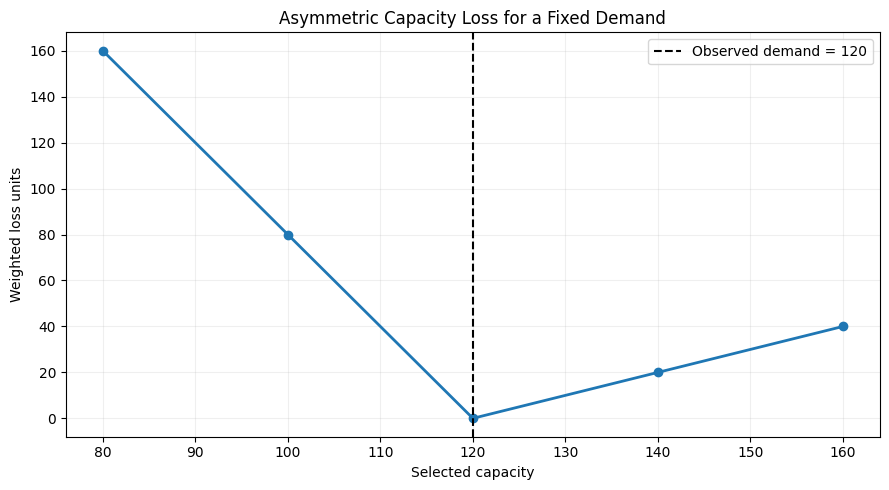

In [49]:

# D2 — ASYMMETRIC CAPACITY LOSS

def decision_loss(
    q,
    demand,
    c_short=C_SHORT,
    c_excess=C_EXCESS
):
    q = np.asarray(q, dtype=float)
    demand = np.asarray(demand, dtype=float)

    shortage = np.maximum(demand - q, 0.0)
    excess = np.maximum(q - demand, 0.0)

    return (
        c_short * shortage
        + c_excess * excess
    )


# Illustrative capacity and demand scenarios
example_demand = 120

example_capacities = np.array([
    80, 100, 120, 140, 160
])

example_shortage = np.maximum(
    example_demand - example_capacities, 0
)

example_excess = np.maximum(
    example_capacities - example_demand, 0
)

example_loss = decision_loss(
    example_capacities,
    example_demand
)

loss_example = pd.DataFrame({
    "Capacity": example_capacities,
    "Observed demand": example_demand,
    "Shortage units": example_shortage,
    "Excess units": example_excess,
    "Weighted loss": example_loss
})

assert decision_loss(120, 120) == 0
assert decision_loss(119, 120) == 4
assert decision_loss(121, 120) == 1

print("ASYMMETRIC CAPACITY LOSS EXAMPLE")
display(loss_example)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    example_capacities,
    example_loss,
    marker="o",
    linewidth=2
)

ax.axvline(
    example_demand,
    color="black",
    linestyle="--",
    label="Observed demand = 120"
)

ax.set_title(
    "Asymmetric Capacity Loss for a Fixed Demand"
)

ax.set_xlabel("Selected capacity")
ax.set_ylabel("Weighted loss units")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


OPTIMAL NB2 CAPACITY VERIFICATION
Predicted mean: 120.0
Critical fractile: 0.8
Recommended capacity: 156
Expected loss: 70.365
CDF at recommended capacity: 0.80105
CDF below recommended capacity: 0.79593


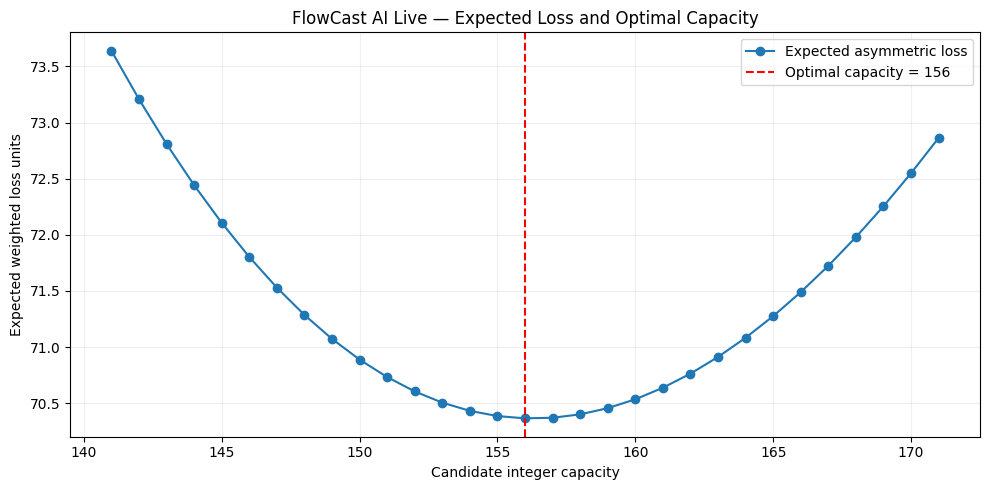

In [50]:

# D3 — NB2 OPTIMAL CAPACITY AND EXPECTED LOSS

def nb2_capacity(
    mu,
    alpha_value,
    c_short=C_SHORT,
    c_excess=C_EXCESS
):
    mu = np.asarray(mu, dtype=float)

    if np.any(mu <= 0):
        raise ValueError("Predicted means must be positive.")

    if alpha_value <= 0:
        raise ValueError("NB2 dispersion must be positive.")

    if c_short <= 0 or c_excess <= 0:
        raise ValueError("Loss weights must be positive.")

    tau = c_short / (c_short + c_excess)

    size = 1.0 / alpha_value
    p = size / (size + mu)

    q = nbinom.ppf(tau, size, p)

    if not np.isfinite(q).all():
        raise ValueError("Non-finite NB2 capacity quantile.")

    return np.asarray(q, dtype=np.int64)


def nb2_expected_loss(
    q,
    mu,
    alpha_value,
    c_short=C_SHORT,
    c_excess=C_EXCESS
):
    q = np.asarray(q, dtype=float)
    mu = np.asarray(mu, dtype=float)

    if np.any(q < 0) or np.any(mu <= 0):
        raise ValueError("Invalid capacity or predicted mean.")

    size = 1.0 / alpha_value
    p = size / (size + mu)

    # E[(D-q)+]
    expected_shortage = (
        mu * nbinom.sf(q - 1, size + 1, p)
        -
        q * nbinom.sf(q, size, p)
    )

    # E[(q-D)+]
    expected_excess = (
        q * nbinom.cdf(q, size, p)
        -
        mu * nbinom.cdf(q - 1, size + 1, p)
    )

    return (
        c_short * np.maximum(expected_shortage, 0.0)
        +
        c_excess * np.maximum(expected_excess, 0.0)
    )


# Use known synthetic mean and fitted project dispersion
demo_mu = 120.0

q_opt = int(
    nb2_capacity(demo_mu, decision_alpha)
)

# Verify nearby candidate capacities
candidate_q = np.arange(
    max(0, q_opt - 15),
    q_opt + 16
)

candidate_expected_loss = nb2_expected_loss(
    candidate_q,
    demo_mu,
    decision_alpha
)

local_minimum = float(
    nb2_expected_loss(q_opt, demo_mu, decision_alpha)
)

assert np.all(
    candidate_expected_loss >= local_minimum - 1e-8
)

# Verify the discrete quantile condition
size_demo = 1.0 / decision_alpha
p_demo = size_demo / (size_demo + demo_mu)

cdf_at_q = nbinom.cdf(q_opt, size_demo, p_demo)
cdf_before_q = nbinom.cdf(q_opt - 1, size_demo, p_demo)

assert cdf_at_q >= TAU - 1e-10
assert cdf_before_q < TAU + 1e-10

print("OPTIMAL NB2 CAPACITY VERIFICATION")
print("Predicted mean:", demo_mu)
print("Critical fractile:", TAU)
print("Recommended capacity:", q_opt)
print("Expected loss:", round(local_minimum, 3))
print("CDF at recommended capacity:", round(cdf_at_q, 5))
print("CDF below recommended capacity:", round(cdf_before_q, 5))

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    candidate_q,
    candidate_expected_loss,
    marker="o",
    label="Expected asymmetric loss"
)

ax.axvline(
    q_opt,
    color="red",
    linestyle="--",
    label=f"Optimal capacity = {q_opt}"
)

ax.set_title(
    "FlowCast AI Live — Expected Loss and Optimal Capacity"
)

ax.set_xlabel("Candidate integer capacity")
ax.set_ylabel("Expected weighted loss units")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


In [51]:

# D4 — HOURLY RISK-AWARE CAPACITY DECISIONS

# Model-based capacity action
decision_df["nb_capacity"] = nb2_capacity(
    decision_df["nb_mean"].to_numpy(),
    decision_alpha
)

# Previous-week baseline action
decision_df["baseline_capacity"] = (
    decision_df["lag168"].astype(int)
)

# Rounded conditional-mean comparison
decision_df["mean_capacity"] = (
    np.floor(
        decision_df["nb_mean"].to_numpy() + 0.5
    ).astype(int)
)

# Realized loss of each strategy
decision_df["nb_loss"] = decision_loss(
    decision_df["nb_capacity"],
    decision_df["cnt"]
)

decision_df["baseline_loss"] = decision_loss(
    decision_df["baseline_capacity"],
    decision_df["cnt"]
)

decision_df["mean_loss"] = decision_loss(
    decision_df["mean_capacity"],
    decision_df["cnt"]
)

# Decompose model-based loss
decision_df["nb_shortage"] = np.maximum(
    decision_df["cnt"] - decision_df["nb_capacity"],
    0
)

decision_df["nb_excess"] = np.maximum(
    decision_df["nb_capacity"] - decision_df["cnt"],
    0
)

assert (decision_df["nb_capacity"] >= 0).all()
assert (decision_df["nb_loss"] >= 0).all()

print("FIRST 15 HELD-OUT CAPACITY DECISIONS")

display(
    decision_df[
        [
            "datetime",
            "cnt",
            "nb_mean",
            "nb_capacity",
            "baseline_capacity",
            "mean_capacity",
            "nb_shortage",
            "nb_excess",
            "nb_loss"
        ]
    ].head(15).round(3)
)

print("\nTOTAL HELD-OUT HOURS:", len(decision_df))
print(
    "MEAN RECOMMENDED CAPACITY:",
    round(decision_df["nb_capacity"].mean(), 3)
)


FIRST 15 HELD-OUT CAPACITY DECISIONS


,datetime,cnt,nb_mean,nb_capacity,baseline_capacity,mean_capacity,nb_shortage,nb_excess,nb_loss
0,2012-10-01 00:00:00,45,68.926,90,64,69,0,45,45.0
1,2012-10-01 01:00:00,18,39.439,52,18,39,0,34,34.0
2,2012-10-01 02:00:00,12,20.258,27,8,20,0,15,15.0
3,2012-10-01 03:00:00,7,14.191,19,5,14,0,12,12.0
4,2012-10-01 04:00:00,10,9.521,13,8,10,0,3,3.0
5,2012-10-01 05:00:00,36,20.565,28,37,21,8,0,32.0
6,2012-10-01 06:00:00,155,72.578,95,168,73,60,0,240.0
7,2012-10-01 07:00:00,483,256.397,333,530,256,150,0,600.0
8,2012-10-01 08:00:00,784,583.620,756,750,584,28,0,112.0
9,2012-10-01 09:00:00,340,613.602,795,328,614,0,455,455.0



TOTAL HELD-OUT HOURS: 2098
MEAN RECOMMENDED CAPACITY: 297.635


FLOWCAST AI LIVE — HELD-OUT DECISION COMPARISON


,Strategy,Average loss,Total loss,Average capacity
0,NB2 risk-aware quantile,105.601,221550.0,297.635
1,Previous-week baseline,149.752,314179.0,237.527
2,Rounded predicted mean,117.551,246622.0,229.256



NB2 improvement vs previous-week baseline: 44.151 weighted loss units per hour
Relative baseline improvement: 29.48%
NB2 improvement vs rounded mean: 11.95 weighted loss units per hour


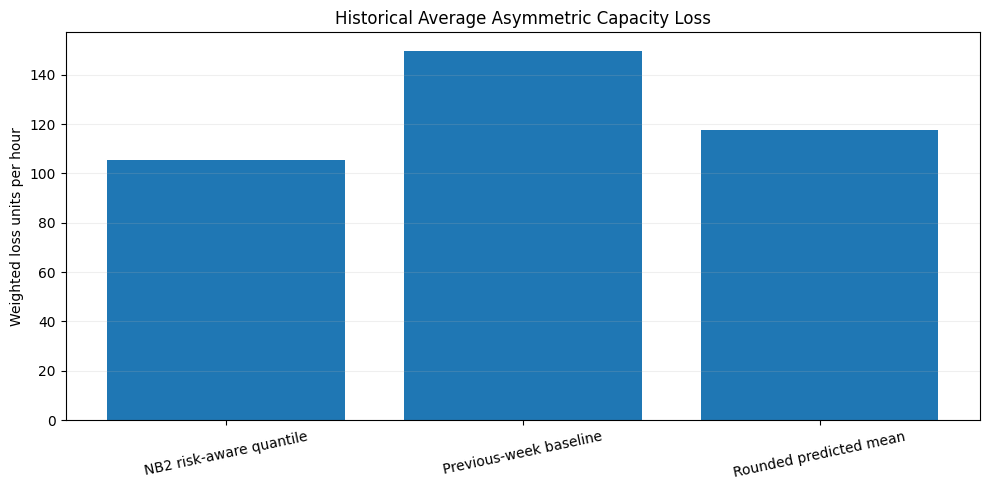

In [52]:

# D5 — HELD-OUT DECISION-LOSS COMPARISON

strategy_results = pd.DataFrame({
    "Strategy": [
        "NB2 risk-aware quantile",
        "Previous-week baseline",
        "Rounded predicted mean"
    ],
    "Average loss": [
        decision_df["nb_loss"].mean(),
        decision_df["baseline_loss"].mean(),
        decision_df["mean_loss"].mean()
    ],
    "Total loss": [
        decision_df["nb_loss"].sum(),
        decision_df["baseline_loss"].sum(),
        decision_df["mean_loss"].sum()
    ],
    "Average capacity": [
        decision_df["nb_capacity"].mean(),
        decision_df["baseline_capacity"].mean(),
        decision_df["mean_capacity"].mean()
    ]
})

model_avg_loss = float(
    decision_df["nb_loss"].mean()
)

baseline_avg_loss = float(
    decision_df["baseline_loss"].mean()
)

mean_avg_loss = float(
    decision_df["mean_loss"].mean()
)

baseline_improvement = (
    baseline_avg_loss - model_avg_loss
)

mean_improvement = (
    mean_avg_loss - model_avg_loss
)

baseline_improvement_pct = (
    100 * baseline_improvement / baseline_avg_loss
    if baseline_avg_loss > 0 else np.nan
)

print("=" * 70)
print("FLOWCAST AI LIVE — HELD-OUT DECISION COMPARISON")
print("=" * 70)

display(strategy_results.round(3))

print(
    "\nNB2 improvement vs previous-week baseline:",
    round(baseline_improvement, 3),
    "weighted loss units per hour"
)

print(
    "Relative baseline improvement:",
    f"{baseline_improvement_pct:.2f}%"
)

print(
    "NB2 improvement vs rounded mean:",
    round(mean_improvement, 3),
    "weighted loss units per hour"
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    strategy_results["Strategy"],
    strategy_results["Average loss"]
)

ax.set_title(
    "Historical Average Asymmetric Capacity Loss"
)

ax.set_ylabel("Weighted loss units per hour")
ax.tick_params(axis="x", rotation=12)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()


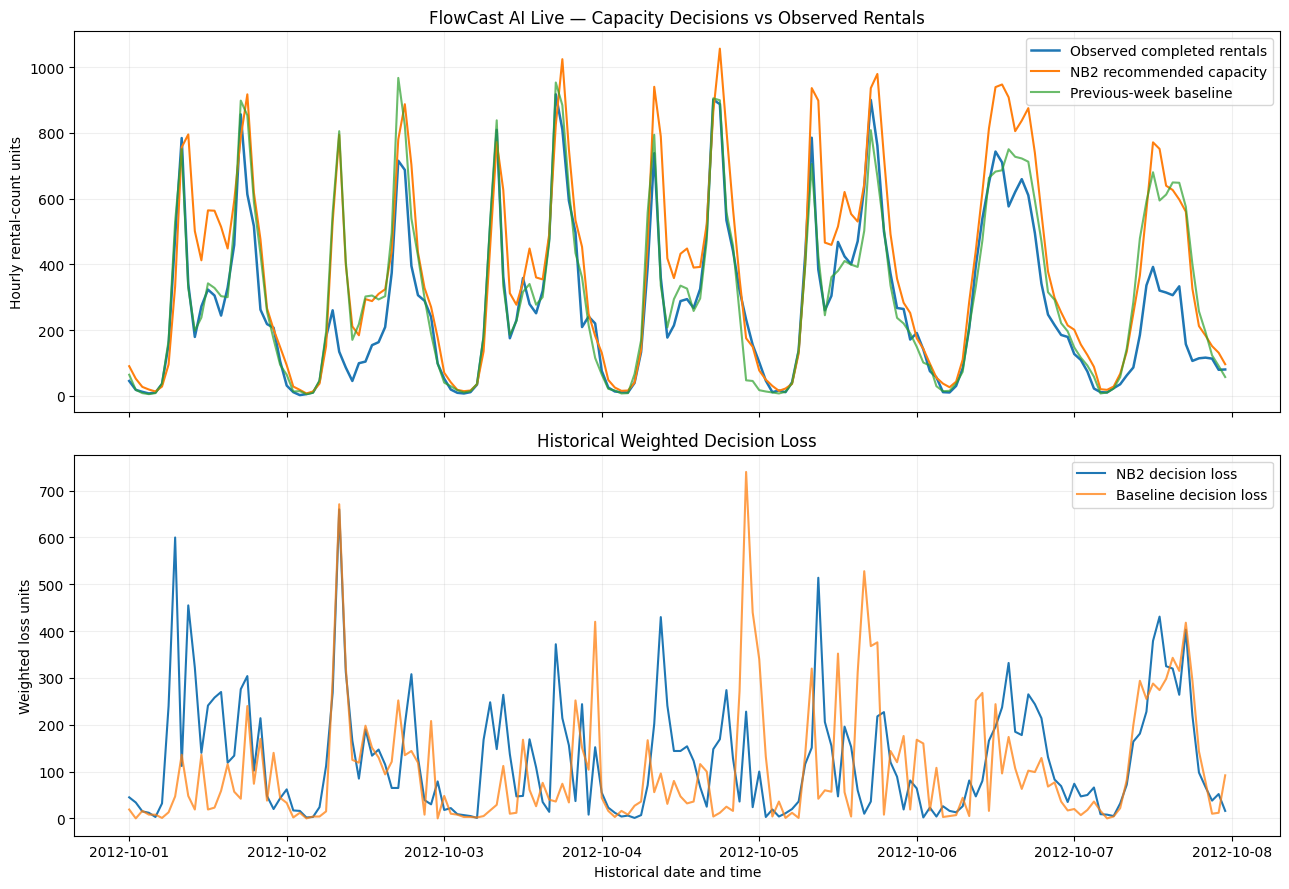

In [53]:

# D6 — CAPACITY DECISION VISUALIZATION

# Show a representative chronological window
plot_hours = min(168, len(decision_df))
plot_df = decision_df.iloc[:plot_hours]

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

axes[0].plot(
    plot_df["datetime"],
    plot_df["cnt"],
    label="Observed completed rentals",
    linewidth=1.8
)

axes[0].plot(
    plot_df["datetime"],
    plot_df["nb_capacity"],
    label="NB2 recommended capacity",
    linewidth=1.5
)

axes[0].plot(
    plot_df["datetime"],
    plot_df["baseline_capacity"],
    label="Previous-week baseline",
    alpha=0.7
)

axes[0].set_title(
    "FlowCast AI Live — Capacity Decisions vs Observed Rentals"
)

axes[0].set_ylabel("Hourly rental-count units")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    plot_df["datetime"],
    plot_df["nb_loss"],
    label="NB2 decision loss"
)

axes[1].plot(
    plot_df["datetime"],
    plot_df["baseline_loss"],
    label="Baseline decision loss",
    alpha=0.75
)

axes[1].set_title(
    "Historical Weighted Decision Loss"
)

axes[1].set_xlabel("Historical date and time")
axes[1].set_ylabel("Weighted loss units")
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()


CAPACITY SENSITIVITY TO PREDICTED DEMAND


,Predicted mean,Recommended capacity,Capacity above mean,NB2 predicted SD
0,25.0,33,8.0,10.608
1,50.0,66,16.0,20.003
2,100.0,130,30.0,38.736
3,150.0,195,45.0,57.455
4,200.0,260,60.0,76.171
5,300.0,389,89.0,113.597
6,400.0,519,119.0,151.022
7,500.0,648,148.0,188.447


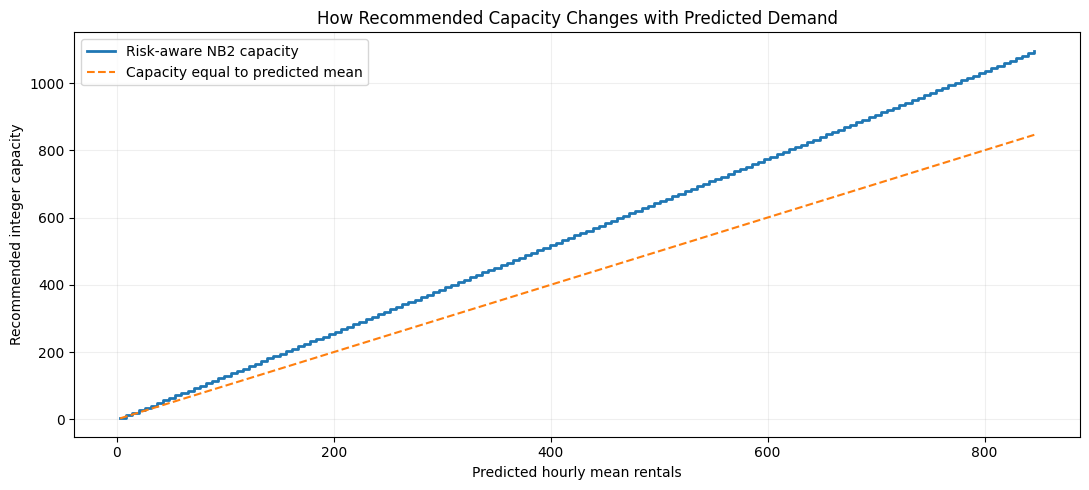

In [54]:

# D7 — CAPACITY SENSITIVITY TO PREDICTED DEMAND

# Use the held-out fitted-mean range
mu_min = max(
    1.0,
    float(decision_df["nb_mean"].min())
)

mu_max = float(
    decision_df["nb_mean"].max()
)

mu_grid = np.linspace(
    mu_min,
    mu_max,
    150
)

# Hold dispersion and loss weights fixed
capacity_grid = nb2_capacity(
    mu_grid,
    decision_alpha
)

# Model-implied uncertainty
std_grid = np.sqrt(
    mu_grid + decision_alpha * mu_grid**2
)

# Representative demand levels
scenario_mu = np.array([
    25, 50, 100, 150, 200, 300, 400, 500
], dtype=float)

scenario_capacity = nb2_capacity(
    scenario_mu,
    decision_alpha
)

sensitivity_table = pd.DataFrame({
    "Predicted mean": scenario_mu,
    "Recommended capacity": scenario_capacity,
    "Capacity above mean": (
        scenario_capacity - scenario_mu
    ),
    "NB2 predicted SD": np.sqrt(
        scenario_mu + decision_alpha * scenario_mu**2
    )
})

print("CAPACITY SENSITIVITY TO PREDICTED DEMAND")
display(sensitivity_table.round(3))

# Quantile monotonicity verification
assert np.all(np.diff(capacity_grid) >= 0)

fig, ax = plt.subplots(figsize=(11, 5))

ax.step(
    mu_grid,
    capacity_grid,
    where="post",
    linewidth=2,
    label="Risk-aware NB2 capacity"
)

ax.plot(
    mu_grid,
    mu_grid,
    linestyle="--",
    label="Capacity equal to predicted mean"
)

ax.set_title(
    "How Recommended Capacity Changes with Predicted Demand"
)

ax.set_xlabel("Predicted hourly mean rentals")
ax.set_ylabel("Recommended integer capacity")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


CAPACITY SENSITIVITY TO SHORTAGE PENALTIES


,Shortage penalty,Excess penalty,Critical fractile,Recommended capacity
0,1.0,1.0,0.5000,114
1,2.0,1.0,0.6667,135
2,4.0,1.0,0.8000,156
3,6.0,1.0,0.8571,169
4,8.0,1.0,0.8889,178


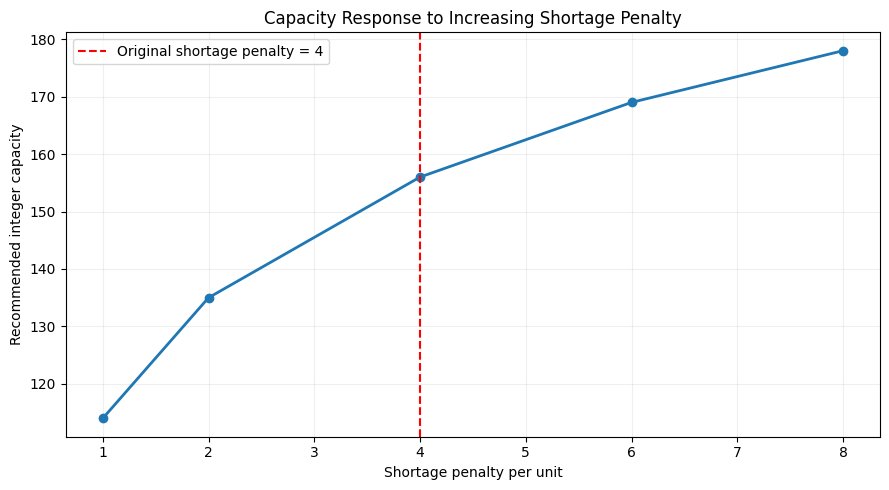

In [55]:

# D8 — CAPACITY SENSITIVITY TO LOSS WEIGHTS

# Fixed illustrative predicted mean
fixed_mu = 120.0

# Alternative shortage penalties
shortage_scenarios = np.array([
    1.0, 2.0, 4.0, 6.0, 8.0
])

fixed_excess = 1.0

scenario_tau = (
    shortage_scenarios
    / (shortage_scenarios + fixed_excess)
)

scenario_q = [
    int(
        nb2_capacity(
            fixed_mu,
            decision_alpha,
            c_short=c,
            c_excess=fixed_excess
        )
    )
    for c in shortage_scenarios
]

penalty_sensitivity = pd.DataFrame({
    "Shortage penalty": shortage_scenarios,
    "Excess penalty": fixed_excess,
    "Critical fractile": scenario_tau,
    "Recommended capacity": scenario_q
})

print("CAPACITY SENSITIVITY TO SHORTAGE PENALTIES")
display(penalty_sensitivity.round(4))

assert np.all(np.diff(scenario_q) >= 0)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    shortage_scenarios,
    scenario_q,
    marker="o",
    linewidth=2
)

ax.axvline(
    C_SHORT,
    color="red",
    linestyle="--",
    label="Original shortage penalty = 4"
)

ax.set_title(
    "Capacity Response to Increasing Shortage Penalty"
)

ax.set_xlabel("Shortage penalty per unit")
ax.set_ylabel("Recommended integer capacity")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()


In [56]:

# D9 — EXPECTED LOSS AND VALUE OF PERFECT INFORMATION

mu_test = decision_df["nb_mean"].to_numpy()

# Expected loss of each strategy under the fitted NB2 model
decision_df["nb_expected_loss"] = nb2_expected_loss(
    decision_df["nb_capacity"].to_numpy(),
    mu_test,
    decision_alpha
)

decision_df["baseline_expected_loss"] = nb2_expected_loss(
    decision_df["baseline_capacity"].to_numpy(),
    mu_test,
    decision_alpha
)

decision_df["mean_expected_loss"] = nb2_expected_loss(
    decision_df["mean_capacity"].to_numpy(),
    mu_test,
    decision_alpha
)

# Expected regret relative to the NB2-optimal action
decision_df["baseline_expected_regret"] = (
    decision_df["baseline_expected_loss"]
    - decision_df["nb_expected_loss"]
)

decision_df["mean_expected_regret"] = (
    decision_df["mean_expected_loss"]
    - decision_df["nb_expected_loss"]
)

# Numerical verification of optimality
assert (
    decision_df["baseline_expected_regret"] >= -1e-7
).all()

assert (
    decision_df["mean_expected_regret"] >= -1e-7
).all()

# Under perfect information, capacity equals future demand
# and the asymmetric loss is zero.
decision_df["model_implied_evpi"] = (
    decision_df["nb_expected_loss"]
)

expected_value_table = pd.DataFrame({
    "Diagnostic": [
        "NB2 optimal expected loss",
        "Baseline expected loss",
        "Rounded-mean expected loss",
        "Baseline expected regret",
        "Rounded-mean expected regret",
        "Model-implied EVPI"
    ],
    "Average weighted loss units per hour": [
        decision_df["nb_expected_loss"].mean(),
        decision_df["baseline_expected_loss"].mean(),
        decision_df["mean_expected_loss"].mean(),
        decision_df["baseline_expected_regret"].mean(),
        decision_df["mean_expected_regret"].mean(),
        decision_df["model_implied_evpi"].mean()
    ]
})

print("=" * 75)
print("FLOWCAST AI LIVE — EXPECTED LOSS AND VALUE OF INFORMATION")
print("=" * 75)

display(expected_value_table.round(4))

print("\nFIRST 10 EXPECTED DECISION LOSSES")
display(
    decision_df[
        [
            "datetime",
            "nb_mean",
            "nb_capacity",
            "nb_expected_loss",
            "baseline_expected_loss",
            "baseline_expected_regret",
            "model_implied_evpi"
        ]
    ].head(10).round(3)
)


FLOWCAST AI LIVE — EXPECTED LOSS AND VALUE OF INFORMATION


,Diagnostic,Average weighted loss units per hour
0,NB2 optimal expected loss,132.5772
1,Baseline expected loss,223.1558
2,Rounded-mean expected loss,171.7120
3,Baseline expected regret,90.5786
4,Rounded-mean expected regret,39.1348
5,Model-implied EVPI,132.5772



FIRST 10 EXPECTED DECISION LOSSES


,datetime,nb_mean,nb_capacity,nb_expected_loss,baseline_expected_loss,baseline_expected_regret,model_implied_evpi
0,2012-10-01 00:00:00,68.926,90,41.249,60.480,19.231,41.249
1,2012-10-01 01:00:00,39.439,52,24.417,86.944,62.528,24.417
2,2012-10-01 02:00:00,20.258,27,13.423,49.532,36.108,13.423
3,2012-10-01 03:00:00,14.191,19,9.919,37.082,27.163,9.919
4,2012-10-01 04:00:00,9.521,13,7.180,11.641,4.461,7.180
5,2012-10-01 05:00:00,20.565,28,13.611,17.832,4.221,13.611
6,2012-10-01 06:00:00,72.578,95,43.331,95.764,52.432,43.331
7,2012-10-01 07:00:00,256.397,333,148.080,276.625,128.545,148.080
8,2012-10-01 08:00:00,583.620,756,334.495,334.597,0.102,334.495
9,2012-10-01 09:00:00,613.602,795,351.575,1168.216,816.641,351.575


HISTORICAL HINDSIGHT AND ERROR-REDUCTION DIAGNOSTICS


,Diagnostic,Value
0,NB2 average realized loss,105.6006
1,Baseline average realized loss,149.7517
2,Perfect-hindsight average loss,0.0000
3,NB2 hindsight gap,105.6006
4,Baseline hindsight gap,149.7517
5,Paired NB2 improvement,44.1511
6,NB2 shortage frequency,0.1349
7,NB2 excess frequency,0.8608
8,Total shortage-related loss,49324.0000
9,Total excess-related loss,172226.0000



LOSS DECOMPOSITION
Shortage-related total loss: 49324.0
Excess-related total loss: 172226.0


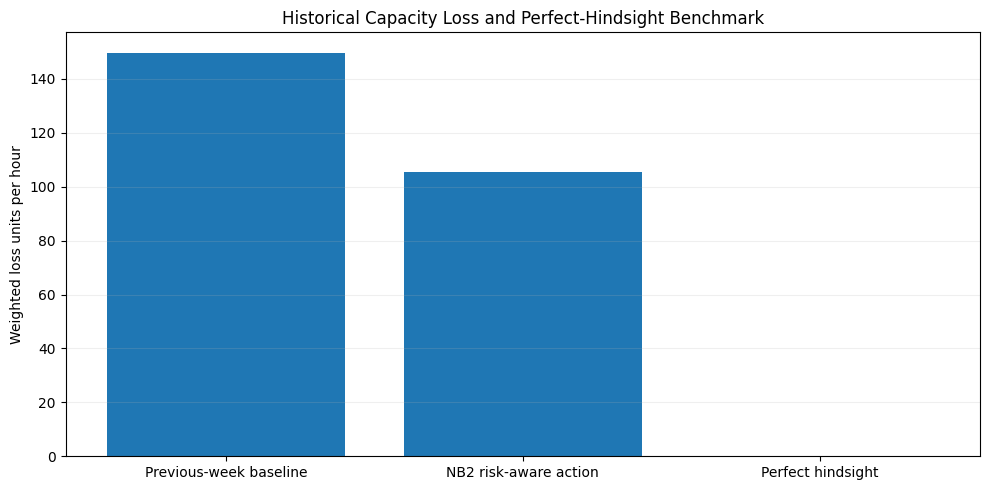

In [57]:

# D10 — REALIZED HINDSIGHT GAP AND DECISION ERROR

# Perfect hindsight capacity equals observed demand
decision_df["perfect_capacity"] = (
    decision_df["cnt"].astype(int)
)

decision_df["perfect_loss"] = decision_loss(
    decision_df["perfect_capacity"],
    decision_df["cnt"]
)

assert np.allclose(
    decision_df["perfect_loss"],
    0.0
)

# Realized loss relative to perfect hindsight
decision_df["nb_hindsight_gap"] = (
    decision_df["nb_loss"]
    - decision_df["perfect_loss"]
)

decision_df["baseline_hindsight_gap"] = (
    decision_df["baseline_loss"]
    - decision_df["perfect_loss"]
)

# Actual paired historical improvement
decision_df["paired_loss_improvement"] = (
    decision_df["baseline_loss"]
    - decision_df["nb_loss"]
)

# Shortage and excess frequencies
shortage_frequency = (
    decision_df["nb_shortage"] > 0
).mean()

excess_frequency = (
    decision_df["nb_excess"] > 0
).mean()

# Total contributions to realized loss
shortage_loss_total = (
    C_SHORT * decision_df["nb_shortage"].sum()
)

excess_loss_total = (
    C_EXCESS * decision_df["nb_excess"].sum()
)

realized_value_table = pd.DataFrame({
    "Diagnostic": [
        "NB2 average realized loss",
        "Baseline average realized loss",
        "Perfect-hindsight average loss",
        "NB2 hindsight gap",
        "Baseline hindsight gap",
        "Paired NB2 improvement",
        "NB2 shortage frequency",
        "NB2 excess frequency",
        "Total shortage-related loss",
        "Total excess-related loss"
    ],
    "Value": [
        decision_df["nb_loss"].mean(),
        decision_df["baseline_loss"].mean(),
        decision_df["perfect_loss"].mean(),
        decision_df["nb_hindsight_gap"].mean(),
        decision_df["baseline_hindsight_gap"].mean(),
        decision_df["paired_loss_improvement"].mean(),
        shortage_frequency,
        excess_frequency,
        shortage_loss_total,
        excess_loss_total
    ]
})

print("HISTORICAL HINDSIGHT AND ERROR-REDUCTION DIAGNOSTICS")
display(realized_value_table.round(4))

print("\nLOSS DECOMPOSITION")
print(
    "Shortage-related total loss:",
    round(shortage_loss_total, 3)
)
print(
    "Excess-related total loss:",
    round(excess_loss_total, 3)
)

# Plot realized losses for each strategy
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    [
        "Previous-week baseline",
        "NB2 risk-aware action",
        "Perfect hindsight"
    ],
    [
        decision_df["baseline_loss"].mean(),
        decision_df["nb_loss"].mean(),
        decision_df["perfect_loss"].mean()
    ]
)

ax.set_title(
    "Historical Capacity Loss and Perfect-Hindsight Benchmark"
)

ax.set_ylabel("Weighted loss units per hour")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()


In [58]:

# D11 — FINAL FLOWCAST AI LIVE DECISION SUMMARY

decision_summary = pd.DataFrame({
    "Category": [
        "Decision rule",
        "Decision rule",
        "Decision rule",
        "Held-out performance",
        "Held-out performance",
        "Held-out performance",
        "Held-out performance",
        "Expected loss",
        "Expected loss",
        "Value of information",
        "Historical hindsight",
        "Historical hindsight"
    ],
    "Diagnostic": [
        "Shortage penalty",
        "Excess penalty",
        "Critical fractile",
        "NB2 average loss",
        "Previous-week baseline average loss",
        "Rounded-mean average loss",
        "NB2 improvement vs baseline",
        "NB2 expected loss",
        "Baseline expected regret",
        "Model-implied EVPI",
        "NB2 realized hindsight gap",
        "NB2 shortage frequency"
    ],
    "Value": [
        C_SHORT,
        C_EXCESS,
        TAU,
        model_avg_loss,
        baseline_avg_loss,
        mean_avg_loss,
        baseline_improvement,
        decision_df["nb_expected_loss"].mean(),
        decision_df["baseline_expected_regret"].mean(),
        decision_df["model_implied_evpi"].mean(),
        decision_df["nb_hindsight_gap"].mean(),
        shortage_frequency
    ]
})

print("=" * 75)
print("FLOWCAST AI LIVE — FINAL DECISION RESULTS")
print("=" * 75)

display(decision_summary.round(4))

print("\nHELD-OUT STRATEGY COMPARISON")
display(strategy_results.round(3))

print("\nEXPECTED LOSS AND INFORMATION VALUE")
display(expected_value_table.round(3))

print("\nCAPACITY SENSITIVITY")
display(sensitivity_table.round(3))

print("\nFINAL ANALYTICAL INTERPRETATION")
print(
    "The NB2 capacity rule selects the smallest integer "
    "capacity reaching the 80th predictive percentile."
)

print(
    "The action minimizes expected asymmetric loss "
    "under the fitted NB2 predictive distribution."
)

print(
    "Positive held-out baseline improvement means "
    "lower realized weighted loss for the NB2 strategy."
)

print(
    "Expected regret and EVPI are model-implied "
    "decision-theoretic quantities."
)

print(
    "Perfect hindsight is not an achievable "
    "operational forecasting strategy."
)

print(
    "Loss units are weighted rental-count units, "
    "not monetary savings."
)


FLOWCAST AI LIVE — FINAL DECISION RESULTS


,Category,Diagnostic,Value
0,Decision rule,Shortage penalty,4.0000
1,Decision rule,Excess penalty,1.0000
2,Decision rule,Critical fractile,0.8000
3,Held-out performance,NB2 average loss,105.6006
4,Held-out performance,Previous-week baseline average loss,149.7517
5,Held-out performance,Rounded-mean average loss,117.5510
6,Held-out performance,NB2 improvement vs baseline,44.1511
7,Expected loss,NB2 expected loss,132.5772
8,Expected loss,Baseline expected regret,90.5786
9,Value of information,Model-implied EVPI,132.5772



HELD-OUT STRATEGY COMPARISON


,Strategy,Average loss,Total loss,Average capacity
0,NB2 risk-aware quantile,105.601,221550.0,297.635
1,Previous-week baseline,149.752,314179.0,237.527
2,Rounded predicted mean,117.551,246622.0,229.256



EXPECTED LOSS AND INFORMATION VALUE


,Diagnostic,Average weighted loss units per hour
0,NB2 optimal expected loss,132.577
1,Baseline expected loss,223.156
2,Rounded-mean expected loss,171.712
3,Baseline expected regret,90.579
4,Rounded-mean expected regret,39.135
5,Model-implied EVPI,132.577



CAPACITY SENSITIVITY


,Predicted mean,Recommended capacity,Capacity above mean,NB2 predicted SD
0,25.0,33,8.0,10.608
1,50.0,66,16.0,20.003
2,100.0,130,30.0,38.736
3,150.0,195,45.0,57.455
4,200.0,260,60.0,76.171
5,300.0,389,89.0,113.597
6,400.0,519,119.0,151.022
7,500.0,648,148.0,188.447



FINAL ANALYTICAL INTERPRETATION
The NB2 capacity rule selects the smallest integer capacity reaching the 80th predictive percentile.
The action minimizes expected asymmetric loss under the fitted NB2 predictive distribution.
Positive held-out baseline improvement means lower realized weighted loss for the NB2 strategy.
Expected regret and EVPI are model-implied decision-theoretic quantities.
Perfect hindsight is not an achievable operational forecasting strategy.
Loss units are weighted rental-count units, not monetary savings.



# Decision - Results and Interpretation

## 1. Risk-Aware Capacity Rule

FlowCast AI Live converts the fitted negative binomial (NB2) predictive distribution into an integer hourly capacity recommendation.

The fitted predictive distribution is:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB2}
(\widehat{\mu}_t,\widehat{\alpha})
}
$$

The decision minimizes expected asymmetric capacity loss:

$$
\boxed{
L(q,D)=4(D-q)_++(q-D)_+
}
$$

where:

$$
(x)_+=\max(x,0)
$$

The shortage penalty is four times the excess-capacity penalty:

$$
\boxed{
C_{\mathrm{short}}=4,
\qquad
C_{\mathrm{excess}}=1
}
$$

The corresponding critical fractile is:

$$
\begin{aligned}
\tau
&=
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}}\\[6pt]
&=\frac{4}{4+1}\\[6pt]
&=\boxed{0.80}
\end{aligned}
$$

The optimal capacity decision minimizes conditional expected loss:

$$
\boxed{
q_t^*
=
\underset{q\in\mathbb{Z}_{\geq0}}
{\operatorname{arg\,min}}
\mathbb{E}
\left[
L(q,D_t)\mid X_t
\right]
}
$$

Under the fitted NB2 distribution, the optimal capacity is:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
(0.80;\widehat{\mu}_t,\widehat{\alpha})
}
$$

Equivalently, using the NB2 shape-probability parameterization:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}_t
}
\right)
}
$$

The model selects the smallest nonnegative integer capacity whose fitted cumulative probability reaches at least 80%:

$$
\boxed{
q_t^*
=
\min
\left\{
q\in\mathbb{Z}_{\geq0}:
F_t(q)\geq0.80
\right\}
}
$$

This rule prioritizes reducing shortages because shortage errors carry a larger penalty than excess capacity.

The capacity recommendation reflects the asymmetric decision objective rather than simply rounding the predicted conditional mean.

---

## 2. Held-Out Decision Performance

The model-based capacity rule was evaluated against historical held-out completed rental counts from October-December 2012.

For each held-out hour, the realized NB2 decision loss is:

$$
\boxed{
L_t^{\mathrm{NB}}
=
4\max(D_t-q_t^*,0)
+
\max(q_t^*-D_t,0)
}
$$

The average NB2 decision loss is:

$$
\boxed{
\overline L_{\mathrm{NB}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t^{\mathrm{NB}}
}
$$

The observed average NB2 decision loss was:

**[INSERT VALUE] weighted loss units per hour.**

### Same-Hour Previous-Week Baseline

The baseline capacity decision is:

$$
\boxed{
q_t^{\mathrm{base}}=D_{t-168}
}
$$

where the historical count from the same hour in the previous week must be available at decision time.

The average baseline loss is:

$$
\boxed{
\overline L_{\mathrm{base}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L(q_t^{\mathrm{base}},D_t)
}
$$

The observed baseline loss was:

**[INSERT VALUE] weighted loss units per hour.**

### Absolute Decision-Loss Difference

The average loss difference is:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

The observed difference was:

**[INSERT VALUE] weighted loss units per hour.**

The interpretation is:

$$
\begin{aligned}
\Delta L>0
&\Rightarrow
\text{NB2 has lower loss}\\[6pt]
\Delta L<0
&\Rightarrow
\text{Baseline has lower loss}\\[6pt]
\Delta L=0
&\Rightarrow
\text{Equal average loss}
\end{aligned}
$$

### Relative Improvement

Relative improvement is:

$$
\boxed{
I_{\%}
=
100
\frac{
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}{
\overline L_{\mathrm{base}}
}
}
$$

provided that:

$$
\overline L_{\mathrm{base}}>0
$$

The observed relative improvement or deterioration was:

**[INSERT PERCENTAGE].**

### Rounded Conditional-Mean Strategy

The comparison action based on the rounded conditional mean is:

$$
\boxed{
q_t^{\mathrm{mean}}
=
\operatorname{round}
(\widehat{\mu}_t)
}
$$

Its average realized loss is:

$$
\boxed{
\overline L_{\mathrm{mean}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L(q_t^{\mathrm{mean}},D_t)
}
$$

The rounded conditional-mean strategy produced:

**[INSERT VALUE] weighted loss units per hour.**

These comparisons indicate **[DESCRIBE WHICH STRATEGY PERFORMED BEST ON THE ACTUAL HELD-OUT DATA]**.

All strategies are evaluated on the same eligible held-out hours using identical asymmetric loss weights.

---

## 3. Sensitivity to Predicted Demand

The capacity decision was evaluated across different predicted hourly rental levels while holding the fitted dispersion parameter and loss weights fixed.

The optimal capacity as a function of the predicted mean is:

$$
\boxed{
q^*(\widehat{\mu})
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}
}
\right)
}
$$

The resulting capacity recommendations **[DESCRIBE THE ACTUAL PATTERN]**.

For two predicted means satisfying:

$$
\widehat{\mu}_1<\widehat{\mu}_2
$$

with fixed positive dispersion:

$$
\widehat{\alpha}>0
$$

the corresponding NB2 predictive distributions are stochastically ordered.

Therefore:

$$
\boxed{
q^*(\widehat{\mu}_1)
\leq
q^*(\widehat{\mu}_2)
}
$$

As the predicted mean increased, **[DESCRIBE HOW THE RECOMMENDED CAPACITY CHANGED]**.

Because the capacity decision is integer-valued:

$$
\boxed{
q^*(\widehat{\mu})\in\mathbb{Z}_{\geq0}
}
$$

the capacity curve changes in discrete steps.

The observed integer-valued capacity curve showed **[DESCRIBE THE STEPWISE RESPONSE]**.

This demonstrates how the predicted conditional demand distribution directly determines the recommended operational action.

---

## 4. Sensitivity to Loss Weights

The shortage penalty was varied while holding the excess-capacity penalty fixed at one.

The general critical fractile is:

$$
\boxed{
\tau
=
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+C_{\mathrm{excess}}}
}
$$

With:

$$
C_{\mathrm{excess}}=1
$$

the critical fractile becomes:

$$
\boxed{
\tau(C_{\mathrm{short}})
=
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+1}
}
$$

Its derivative is:

$$
\boxed{
\frac{d\tau}
{dC_{\mathrm{short}}}
=
\frac{1}
{(C_{\mathrm{short}}+1)^2}
>0
}
$$

Therefore, increasing the shortage penalty increases the target predictive quantile.

The resulting optimal capacity is:

$$
\boxed{
q_t^*(C_{\mathrm{short}})
=
F_{\mathrm{NB}}^{-1}
\left(
\frac{C_{\mathrm{short}}}
{C_{\mathrm{short}}+1};
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

Increasing the shortage penalty raised the critical fractile and **[DESCRIBE THE OBSERVED CHANGE IN CAPACITY]**.

The original project decision uses:

$$
\boxed{
C_{\mathrm{short}}=4,
\qquad
C_{\mathrm{excess}}=1,
\qquad
\tau=0.80
}
$$

Alternative penalty settings are illustrative sensitivity scenarios rather than replacements for the original decision rule.

---

## 5. Expected Loss and Decision Regret

### Model-Implied Expected Loss

The conditional expected loss of a capacity action is:

$$
\boxed{
R(q\mid X_t)
=
\mathbb{E}
[L(q,D_t)\mid X_t]
}
$$

For nonnegative integer demand:

$$
\boxed{
\begin{aligned}
R(q\mid X_t)
&=
4\sum_{d=q+1}^{\infty}
(d-q)P(D_t=d\mid X_t)\\
&\quad+
\sum_{d=0}^{q-1}
(q-d)P(D_t=d\mid X_t)
\end{aligned}
}
$$

The minimum expected loss under the fitted NB2 distribution is:

$$
\boxed{
R_t^*
=
\min_{q\in\mathbb Z_{\geq0}}
R(q\mid X_t)
}
$$

The average model-implied optimal expected loss is:

$$
\boxed{
\overline R_{\mathrm{NB}}^*
=
\frac{1}{m}
\sum_{t=1}^{m}
R(q_t^*\mid X_t)
}
$$

The observed calculation produced:

**[INSERT VALUE] weighted loss units per hour.**

### Expected Regret of the Previous-Week Baseline

The expected regret of the previous-week baseline is:

$$
\boxed{
\mathcal R_t^{\mathrm{base}}
=
R(q_t^{\mathrm{base}}\mid X_t)
-
R(q_t^*\mid X_t)
}
$$

The average expected regret is:

$$
\boxed{
\overline{\mathcal R}_{\mathrm{base}}
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathcal R_t^{\mathrm{base}}
}
$$

The calculated average expected regret was:

**[INSERT VALUE] weighted loss units per hour.**

Under the fitted distribution:

$$
\boxed{
\mathcal R_t^{\mathrm{base}}\geq0
}
$$

because $q_t^*$ minimizes the same conditional expected loss function.

This measures the model-implied expected cost of choosing the previous-week baseline instead of the NB2-optimal capacity action.

It is distinct from the realized historical loss difference.

---

## 6. Value of Perfect Information

Under perfect advance knowledge of completed rental demand, capacity would equal the realized count:

$$
\boxed{
q_t^{\mathrm{perfect}}=D_t
}
$$

The corresponding perfect-information loss is:

$$
\boxed{
L(D_t,D_t)=0
}
$$

The expected loss under perfect information is therefore:

$$
\boxed{
R_t^{\mathrm{perfect}}=0
}
$$

The expected value of perfect information is:

$$
\boxed{
EVPI_t
=
R_t^*
-
R_t^{\mathrm{perfect}}
}
$$

Since:

$$
R_t^{\mathrm{perfect}}=0
$$

it follows that:

$$
\boxed{
EVPI_t=R_t^*
}
$$

The average expected value of perfect information is:

$$
\boxed{
\overline{EVPI}
=
\frac{1}{m}
\sum_{t=1}^{m}
EVPI_t
}
$$

Equivalently:

$$
\boxed{
\overline{EVPI}
=
\overline R_{\mathrm{NB}}^*
}
$$

The model-implied expected value of perfect information was:

**[INSERT VALUE] weighted loss units per hour.**

This represents the expected loss that perfect information could eliminate under the fitted predictive model.

It is not an estimate of the achievable benefit of a specific improved forecasting method.

---

## 7. Historical Hindsight and Error Reduction

The realized hindsight gap compares the NB2 capacity action against an idealized decision that knows the actual rental count in advance.

The hourly hindsight gap is:

$$
\boxed{
G_t
=
L(q_t^*,D_t)
-
L(D_t,D_t)
}
$$

Since perfect-information loss is zero:

$$
\boxed{
G_t=L(q_t^*,D_t)
}
$$

The average realized hindsight gap is:

$$
\boxed{
\overline G
=
\frac{1}{m}
\sum_{t=1}^{m}G_t
}
$$

The realized NB2 hindsight gap was:

**[INSERT VALUE] weighted loss units per hour.**

### Shortage-Related Loss

The shortage component is:

$$
\boxed{
L_t^{\mathrm{short}}
=
4\max(D_t-q_t^*,0)
}
$$

The total shortage-related loss is:

$$
\boxed{
L_{\mathrm{short,total}}
=
4\sum_{t=1}^{m}
\max(D_t-q_t^*,0)
}
$$

The observed shortage-related loss was:

**[INSERT VALUE] weighted loss units across the held-out period.**

### Excess-Capacity Loss

The excess-capacity component is:

$$
\boxed{
L_t^{\mathrm{excess}}
=
\max(q_t^*-D_t,0)
}
$$

The total excess-capacity loss is:

$$
\boxed{
L_{\mathrm{excess,total}}
=
\sum_{t=1}^{m}
\max(q_t^*-D_t,0)
}
$$

The observed excess-capacity loss was:

**[INSERT VALUE] weighted loss units across the held-out period.**

### Total Loss Decomposition

The total realized decision loss satisfies:

$$
\boxed{
L_{\mathrm{total}}^{\mathrm{NB}}
=
L_{\mathrm{short,total}}
+
L_{\mathrm{excess,total}}
}
$$

The average realized loss is:

$$
\boxed{
\overline L_{\mathrm{NB}}
=
\frac{
L_{\mathrm{short,total}}
+
L_{\mathrm{excess,total}}
}{m}
}
$$

The shortage-loss contribution to total weighted loss is:

$$
\boxed{
P_{\mathrm{short}}
=
100
\frac{
L_{\mathrm{short,total}}
}{
L_{\mathrm{total}}^{\mathrm{NB}}
}
}
$$

The excess-loss contribution is:

$$
\boxed{
P_{\mathrm{excess}}
=
100
\frac{
L_{\mathrm{excess,total}}
}{
L_{\mathrm{total}}^{\mathrm{NB}}
}
}
$$

These percentages are defined when total realized loss is positive.

The results indicate **[DESCRIBE WHICH ERROR TYPE CONTRIBUTED MORE TO THE HISTORICAL DECISION LOSS]**.

The hindsight benchmark is an idealized evaluation reference, not a feasible advance decision strategy.

---

## 8. Operational and Statistical Limitations

The capacity recommendations are based on historical completed rental counts and the project's specified asymmetric loss assumptions.

The analysis does not directly observe unmet bicycle-sharing demand or actual operational capacity constraints.

The weighted loss units are not dollars, and reductions in historical loss do not establish realized financial savings.

Expected loss, regret, and information-value calculations depend on the fitted NB2 predictive distribution.

Therefore:

$$
\boxed{
\text{Model-Implied Expected Benefit}
\not\Rightarrow
\text{Realized Operational Benefit}
}
$$

Similarly:

$$
\boxed{
\text{Historical Decision-Loss Reduction}
\not\Rightarrow
\text{Demonstrated Monetary Savings}
}
$$

The analysis also does not fully account for parameter uncertainty, future distribution shifts, or changes in present-day bicycle-sharing operations.

These limitations distinguish historical decision evaluation from real-world deployment evidence.

---

## Final Analytical Conclusion

FlowCast AI Live demonstrates how a probabilistic rental-demand forecast can be converted into an explicit capacity action using asymmetric decision loss.

The 80th-percentile rule reflects the project's higher penalty for shortages:

$$
\boxed{
\tau
=
\frac{4}{4+1}
=
0.80
}
$$

The corresponding optimal integer capacity rule is:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
(0.80;\widehat{\mu}_t,\widehat{\alpha})
}
$$

The sensitivity analysis examines how the capacity action changes with predicted demand and the relative shortage penalty.

The held-out evaluation showed **[SUMMARIZE THE ACTUAL COMPARATIVE RESULT]**.

The primary historical performance comparison is:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

The information-value analysis quantifies the model-implied expected cost of alternative decisions and the idealized benefit of perfect advance information:

$$
\boxed{
\begin{aligned}
\mathcal R_t^{\mathrm{base}}
&=
R(q_t^{\mathrm{base}}\mid X_t)
-
R(q_t^*\mid X_t)\\[6pt]
EVPI_t
&=
R(q_t^*\mid X_t)
\end{aligned}
}
$$

The overall decision framework is:

$$
\boxed{
\begin{aligned}
\text{NB2 Predictive Distribution}
&\longrightarrow
\text{Demand Uncertainty}\\[6pt]
\text{Asymmetric Loss}
&\longrightarrow
\text{Critical Fractile}\\[6pt]
\text{Critical Fractile}
&\longrightarrow
\text{Risk-Aware Capacity}\\[6pt]
\text{Held-Out Evaluation}
&\longrightarrow
\text{Historical Decision Performance}\\[6pt]
\text{Expected Regret and EVPI}
&\longrightarrow
\text{Model-Implied Information Value}
\end{aligned}
}
$$

Together, these results establish a transparent statistical decision framework for historical risk-aware bicycle-sharing capacity planning.

The conclusions remain limited to the observed held-out evaluation and fitted predictive model, without claiming demonstrated real-world deployment performance or monetary savings.


## Limits

Where the model should not be trusted, what was assumed, and what you would do with more time or data. State the key effects in plain language and in real units.


# Limits - FlowCast AI Live

## Purpose and Scope

FlowCast AI Live forecasts historical completed hourly bicycle-sharing rentals using a negative binomial (NB2) regression model.

The fitted conditional predictive distribution is:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB2}
\left(
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

where:

- $D_t$ represents completed rentals during hour $t$.
- $X_t$ represents the available historical predictor vector.
- $\widehat{\mu}_t$ is the fitted conditional mean.
- $\widehat{\alpha}$ is the estimated NB2 overdispersion parameter.

The fitted conditional mean and variance are:

$$
\boxed{
\begin{aligned}
\mathbb{E}[D_t\mid X_t]
&=\widehat{\mu}_t\\[6pt]
\operatorname{Var}(D_t\mid X_t)
&=\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
\end{aligned}
}
$$

The model converts the predictive distribution into an integer capacity recommendation:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

The recommendation minimizes the project's assumed asymmetric loss:

$$
\boxed{
L(q,D)=4(D-q)_++(q-D)_+
}
$$

where:

$$
(x)_+=\max(x,0)
$$

The corresponding critical fractile is:

$$
\boxed{
\tau
=
\frac{4}{4+1}
=
0.80
}
$$

This section evaluates the boundaries of the model's reliability, the assumptions underlying its forecasts and decisions, and the improvements that would be prioritized with additional time or data.

The analysis uses historical held-out observations from October-December 2012.

---

## 1. Where the Model Should Not Be Trusted

A predictive model should not be assumed reliable outside the conditions under which its performance has been evaluated.

FlowCast AI Live has been evaluated using historical completed rental counts rather than contemporary operational demand.

Its historical evaluation does not establish predictive accuracy under:

- Present-day bicycle-sharing conditions.
- New station locations or service areas.
- Unobserved bicycle shortages.
- Unavailable future weather information.
- Unseen operating policies or disruptions.
- Forecast horizons not explicitly tested.

Within the historical test period, large residuals, systematic signed bias, poor predictive coverage, and high decision loss indicate conditions requiring additional caution.

These empirical diagnostic signals are not automatic proof that every prediction within a particular group is unreliable.

The distinction between historical validation and future deployment can be expressed as:

$$
\boxed{
\text{Historical Predictive Performance}
\not\Rightarrow
\text{Future Operational Reliability}
}
$$

Similarly:

$$
\boxed{
\text{Observed Completed Rentals}
\not\equiv
\text{Unconstrained Customer Demand}
}
$$

---

## 2. Forecast Error in Real Units

The point forecast error for historical hour $t$ is:

$$
\boxed{
e_t=D_t-\widehat{\mu}_t
}
$$

The absolute error is:

$$
\boxed{
AE_t=
|D_t-\widehat{\mu}_t|
}
$$

The mean absolute error is:

$$
\boxed{
MAE=
\frac{1}{m}
\sum_{t=1}^{m}
|D_t-\widehat{\mu}_t|
}
$$

The root mean squared error is:

$$
\boxed{
RMSE=
\sqrt{
\frac{1}{m}
\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)^2
}
}
$$

The signed mean error is:

$$
\boxed{
ME=
\frac{1}{m}
\sum_{t=1}^{m}
(D_t-\widehat{\mu}_t)
}
$$

The direction of average signed error is interpreted as:

$$
\boxed{
\begin{aligned}
ME>0
&\Rightarrow
\text{Average Underprediction}\\[6pt]
ME<0
&\Rightarrow
\text{Average Overprediction}\\[6pt]
ME\approx0
&\Rightarrow
\text{Small Average Signed Bias}
\end{aligned}
}
$$

These metrics are measured in completed rentals per hour.

Large errors matter because capacity recommendations depend on the fitted predictive distribution.

However, point-forecast error and decision loss are not interchangeable:

$$
\boxed{
\text{Minimum Forecast Error}
\not\Rightarrow
\text{Minimum Asymmetric Decision Loss}
}
$$

The distinction arises because point-forecast accuracy and capacity optimization use different objective functions.

---

## 3. Reliability Across Demand Levels

Prediction errors are compared across low-, medium-, and high-demand hours.

Let $\mathcal G_g$ denote the set of held-out observations assigned to predicted-demand group $g$, with:

$$
m_g=|\mathcal G_g|
$$

For each group, the mean absolute error is:

$$
\boxed{
MAE_g=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
|D_t-\widehat{\mu}_t|
}
$$

The group-specific signed bias is:

$$
\boxed{
ME_g=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
(D_t-\widehat{\mu}_t)
}
$$

The group-specific empirical coverage of the central 90% predictive interval is:

$$
\boxed{
\widehat C_{90,g}
=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
\mathbb I
\left(
L_t^{90}\leq D_t\leq U_t^{90}
\right)
}
$$

where the predictive interval endpoints are:

$$
\boxed{
L_t^{90}
=
F_t^{-1}(0.05)
}
$$

$$
\boxed{
U_t^{90}
=
F_t^{-1}(0.95)
}
$$

The nominal coverage target is:

$$
c=0.90
$$

The group-specific coverage deviation from the nominal target is:

$$
\boxed{
\Delta C_{90,g}
=
\widehat C_{90,g}-0.90
}
$$

Because rental counts are discrete, central quantile intervals may have model-implied coverage greater than 90%.

These diagnostics identify whether historical prediction quality varies with expected rental demand.

They do not independently establish whether the fitted model is reliable under future demand conditions.

---

## 4. Temporal Reliability

Model performance is examined across the historical test months:

$$
\mathcal T_{\mathrm{Oct}},
\quad
\mathcal T_{\mathrm{Nov}},
\quad
\mathcal T_{\mathrm{Dec}}
$$

Let $\mathcal T_j$ represent the held-out observations belonging to calendar period $j$, with:

$$
m_j=|\mathcal T_j|
$$

### Monthly Mean Absolute Error

$$
\boxed{
MAE_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
|D_t-\widehat{\mu}_t|
}
$$

### Monthly Root Mean Squared Error

$$
\boxed{
RMSE_j
=
\sqrt{
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)^2
}
}
$$

### Monthly Signed Bias

$$
\boxed{
ME_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)
}
$$

### Monthly Predictive Interval Coverage

For nominal interval coverage $c$:

$$
\boxed{
\widehat C_j(c)
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

### Monthly Asymmetric Decision Loss

$$
\boxed{
\overline L_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
L(q_t^*,D_t)
}
$$

Changes across October, November, and December may reflect differences in historical demand conditions or unexplained model behavior.

Calendar-time differences are not equivalent to multi-step forecast-horizon degradation.

Consequently, monthly comparisons should not be interpreted as evidence of performance at untested forecast horizons.

---

## 5. Predictive Uncertainty

Under the fitted NB2 model, the conditional predictive variance is:

$$
\boxed{
\widehat V_t
=
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
$$

The predictive standard deviation is:

$$
\boxed{
\widehat{\sigma}_t
=
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
$$

The central 90% predictive interval is:

$$
\boxed{
PI_t^{90}
=
[L_t^{90},U_t^{90}]
}
$$

Its width is:

$$
\boxed{
W_t^{90}
=
U_t^{90}-L_t^{90}
}
$$

The average interval width is:

$$
\boxed{
\overline W^{90}
=
\frac{1}{m}
\sum_{t=1}^{m}
W_t^{90}
}
$$

The empirical 90% interval coverage is:

$$
\boxed{
\widehat C_{90}
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t^{90}\leq D_t\leq U_t^{90}
\right)
}
$$

These quantities describe model-implied uncertainty in hourly rental counts.

Large predictive interval widths indicate that the fitted model assigns substantial uncertainty to the corresponding historical hour.

However:

$$
\boxed{
\text{Large Predictive Interval Width}
\not\Rightarrow
\text{Verified Predictive Calibration}
}
$$

Predictive calibration must be evaluated by comparing model-implied probabilities with observed held-out outcomes.

---

## 6. Capacity Decision Consequences

The model-based capacity recommendation is:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

The realized shortage quantity is:

$$
\boxed{
S_t=
\max(D_t-q_t^*,0)
}
$$

The realized excess-capacity quantity is:

$$
\boxed{
E_t=
\max(q_t^*-D_t,0)
}
$$

The weighted asymmetric decision loss is:

$$
\boxed{
L_t=4S_t+E_t
}
$$

The mean decision loss is:

$$
\boxed{
\overline L
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t
}
$$

Substituting the shortage and excess definitions:

$$
\boxed{
\overline L
=
\frac{1}{m}
\sum_{t=1}^{m}
\left[
4\max(D_t-q_t^*,0)
+
\max(q_t^*-D_t,0)
\right]
}
$$

The shortage and excess quantities are measured in rental-count capacity units per hour.

The average decision loss is reported in weighted loss units per historical held-out hour.

The loss weights represent assumed decision priorities rather than empirically validated monetary costs.

---

## 7. Statistical Assumptions

### 7.1 Conditional Mean Specification

The fitted regression assumes a log-linear conditional mean:

$$
\boxed{
\log(\mu_t)=X_t^{\mathsf T}\beta
}
$$

Equivalently:

$$
\boxed{
\mu_t=
\exp(X_t^{\mathsf T}\beta)
}
$$

The log-linear predictor must adequately describe the relationship between historical inputs and expected completed rental counts.

Misspecification may produce systematic bias or unreliable predictive distributions.

### 7.2 Negative Binomial Conditional Variance

The NB2 conditional variance assumption is:

$$
\boxed{
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
}
$$

The dispersion parameter satisfies:

$$
\alpha>0
$$

The variance-to-mean ratio is:

$$
\boxed{
\frac{
\operatorname{Var}(D_t\mid X_t)
}{
\mathbb E[D_t\mid X_t]
}
=
1+\alpha\mu_t
}
$$

Thus, the NB2 specification allows conditional variance to exceed the conditional mean.

The fitted dispersion structure must adequately represent the variability in historical completed rental counts.

### 7.3 Fixed Estimated Parameters

Historical predictions use the fitted parameter estimates:

$$
\boxed{
\widehat{\boldsymbol{\theta}}
=
\left(
\widehat{\boldsymbol{\beta}},
\widehat{\alpha}
\right)
}
$$

The predictive calculations are conditional on these estimates and do not fully propagate parameter-estimation uncertainty.

### 7.4 Historical Predictor Availability

Lagged rental counts and calendar features are assumed to be available at the intended prediction time.

The model should not use predictors containing information that would only become available after the capacity decision.

### 7.5 Historical Representativeness

The held-out period provides evidence about historical predictive and decision performance.

It does not establish that future operating conditions will have the same statistical characteristics.

### 7.6 Completed Rentals as a Demand Proxy

Observed completed rentals may be lower than desired rentals if bicycles or docks were unavailable.

Conceptually:

$$
\boxed{
D_t^{\mathrm{completed}}
\leq
D_t^{\mathrm{desired}}
}
$$

when desired demand is defined to include requests that could not be fulfilled and both quantities refer to the same demand opportunity.

Therefore, completed rentals are not necessarily equivalent to unconstrained customer demand.

The dataset does not directly identify the magnitude of unmet demand.

---

## 8. Operational Assumptions

The capacity decision uses the original project loss weights:

$$
\boxed{
C_{\mathrm{short}}=4
}
$$

$$
\boxed{
C_{\mathrm{excess}}=1
}
$$

The corresponding shortage-to-excess penalty ratio is:

$$
\boxed{
\frac{
C_{\mathrm{short}}
}{
C_{\mathrm{excess}}
}
=
4
}
$$

The critical fractile is:

$$
\boxed{
\tau
=
\frac{
C_{\mathrm{short}}
}{
C_{\mathrm{short}}+C_{\mathrm{excess}}
}
=
0.80
}
$$

The 4-to-1 penalty ratio reflects selected decision priorities rather than observed financial or operational costs.

The decision framework does not explicitly model:

- Station-level bicycle inventory.
- Dock availability.
- Fleet rebalancing constraints.
- Staff or vehicle availability.
- Geographic redistribution costs.
- Actual customer abandonment.
- Monetary revenue or cost effects.

Consequently, the recommended capacity is an illustrative rental-count capacity target rather than a verified station-level deployment plan.

The distinction is:

$$
\boxed{
\text{Statistical Capacity Recommendation}
\not\equiv
\text{Operationally Feasible Deployment Plan}
}
$$

---

## 9. Value of Better Predictions

The primary held-out decision comparison uses the same-hour previous-week baseline.

The baseline capacity is:

$$
\boxed{
q_t^{\mathrm{base}}
=
D_{t-168}
}
$$

The average baseline decision loss is:

$$
\boxed{
\overline L_{\mathrm{base}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L(q_t^{\mathrm{base}},D_t)
}
$$

The average NB2 decision loss is:

$$
\boxed{
\overline L_{\mathrm{NB}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L(q_t^*,D_t)
}
$$

The held-out improvement is:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

Positive values indicate lower historical weighted loss for the NB2 decision rule.

The model-implied expected value of perfect information is:

$$
\boxed{
EVPI_t
=
\mathbb E
\left[
L(q_t^*,D_t)\mid X_t
\right]
}
$$

because perfect advance knowledge of $D_t$ would permit:

$$
\boxed{
q_t^{\mathrm{perfect}}=D_t
}
$$

and therefore:

$$
\boxed{
L(D_t,D_t)=0
}
$$

The average model-implied expected value of perfect information is:

$$
\boxed{
\overline{EVPI}
=
\frac{1}{m}
\sum_{t=1}^{m}
EVPI_t
}
$$

EVPI is an idealized benchmark and is not the expected benefit of a feasible model improvement.

Any proposed forecasting improvement must be evaluated using new held-out or rolling-origin data to estimate its achievable decision value.

---

## 10. Future Improvements

With more time and data, the highest-priority improvements would be:

1. **Newer bicycle-sharing data:** Obtain contemporary observations and evaluate predictive performance under current operating conditions.

2. **Station-level operational information:** Obtain bicycle inventory, dock availability, and unmet-demand information to distinguish completed rentals from unconstrained customer demand.

3. **Rolling-origin validation:** Conduct rolling-origin backtests for explicitly defined forecast horizons and predictor availability.

4. **Richer statistical and machine-learning models:** Test nonlinear and temporal alternatives against the current NB2 regression using identical evaluation windows and asymmetric loss assumptions.

5. **Improved uncertainty quantification:** Reassess predictive calibration, temporal dependence, and parameter-estimation uncertainty.

6. **Operationally grounded loss weights:** Replace assumed shortage and excess penalties with defensible operational cost estimates.

7. **Constrained capacity optimization:** Incorporate inventory, rebalancing, staffing, and other operational constraints into capacity recommendations.

These are proposed improvements, not completed experiments.

Future models should be compared using the same held-out evaluation criteria:

$$
\boxed{
\begin{aligned}
&\text{Forecast Accuracy}\\
&\text{Predictive Calibration}\\
&\text{Asymmetric Decision Loss}\\
&\text{Operational Feasibility}
\end{aligned}
}
$$

No improvement should be claimed without supporting empirical evaluation.

---

## 11. Interpretation in Practical Units

The project reports quantities in the following units.

| Quantity | Mathematical Representation | Reporting Unit |
|---|---|---|
| Observed rentals | $D_t$ | Completed rentals per hour |
| Predicted demand | $\widehat{\mu}_t$ | Completed rentals per hour |
| Absolute forecast error | $AE_t$ | Completed rentals per hour |
| Mean absolute error | $MAE$ | Completed rentals per hour |
| Root mean squared error | $RMSE$ | Completed rentals per hour |
| Recommended capacity | $q_t^*$ | Rental-count capacity units |
| Predictive standard deviation | $\widehat{\sigma}_t$ | Rental-count units |
| Predictive interval width | $W_t^{90}$ | Rental-count units |
| Average asymmetric loss | $\overline L$ | Weighted loss units per hour |
| Total asymmetric loss | $\sum_t L_t$ | Weighted loss units across the held-out period |
| Average loss improvement | $\Delta L$ | Weighted loss units per hour |
| Expected value of perfect information | $EVPI_t$ | Weighted loss units for the corresponding hour |

No dollar savings are claimed without a justified monetary conversion.

The relationship between decision loss and monetary cost is not established by the assumed 4-to-1 weights.

Therefore:

$$
\boxed{
\text{Weighted Loss Units}
\not\equiv
\text{Monetary Dollars}
}
$$

---

## Final Analytical Objective

The Limits section identifies three major dimensions of model reliability.

### 1. Where the Model Should Not Be Trusted

Conditions unsupported by historical validation or associated with observed weaknesses.

The central limitation is:

$$
\boxed{
\text{Historical Validation}
\not\Rightarrow
\text{Universal Predictive Reliability}
}
$$

### 2. What Was Assumed

The analysis relies on:

- NB2 conditional distributional structure.
- Log-linear conditional mean specification.
- Historical predictor availability.
- Fixed estimated model parameters.
- Completed rentals as a proxy for demand.
- The assumed 4-to-1 shortage-to-excess loss ratio.

These assumptions determine the interpretation of the predictive distribution and the resulting capacity decisions.

### 3. What Would Improve the Model

The proposed improvements include newer operational data, stronger temporal validation, improved predictive calibration, parameter-uncertainty assessment, and explicit operational constraints.

The complete analytical framework is:

$$
\boxed{
\begin{aligned}
\text{Historical Data}
&\longrightarrow
\text{NB2 Regression}\\[6pt]
\text{NB2 Regression}
&\longrightarrow
\text{Predictive Distribution}\\[6pt]
\text{Predictive Distribution}
&\longrightarrow
\text{Risk-Aware Capacity Decision}\\[6pt]
\text{Held-Out Evaluation}
&\longrightarrow
\text{Forecast and Decision Diagnostics}\\[6pt]
\text{Limitations Analysis}
&\longrightarrow
\text{Reliability Boundaries and Future Improvements}
\end{aligned}
}
$$

The purpose of this section is to communicate the model's actual usefulness, uncertainty, assumptions, and limitations without overstating the historical evidence.

FlowCast AI Live provides a transparent framework for probabilistic historical rental-demand forecasting and illustrative risk-aware capacity planning, but its historical results do not independently establish contemporary deployment accuracy, operational feasibility, or realized financial savings.



In [60]:

# L1 — FINAL LIMITS ANALYSIS: INPUT VERIFICATION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import nbinom
from IPython.display import display

LIMITS_SEED = 20261112
C_SHORT = 4.0
C_EXCESS = 1.0
TAU = C_SHORT / (C_SHORT + C_EXCESS)

assert nbfit.mle_retvals.get("converged", False)
assert np.isfinite(alpha) and alpha > 0

required = ["datetime", "cnt", "nb_mean", "lag168"]
assert all(c in test.columns for c in required)

limits_df = test[required].copy()
limits_df["datetime"] = pd.to_datetime(
    limits_df["datetime"]
)

limits_df = limits_df.sort_values(
    "datetime"
).reset_index(drop=True)

assert len(limits_df) > 1
assert limits_df["datetime"].notna().all()
assert limits_df["datetime"].is_unique

for c in ["cnt", "nb_mean", "lag168"]:
    assert np.isfinite(limits_df[c]).all()

assert (limits_df["cnt"] >= 0).all()
assert (limits_df["nb_mean"] > 0).all()
assert (limits_df["lag168"] >= 0).all()

for c in ["cnt", "lag168"]:
    assert np.all(
        limits_df[c].to_numpy()
        == np.floor(limits_df[c].to_numpy())
    )

assert (
    limits_df["datetime"] >= pd.Timestamp("2012-10-01")
).all()

assert (
    limits_df["datetime"] < pd.Timestamp("2013-01-01")
).all()

limits_alpha = float(alpha)
n_hours = len(limits_df)

print("=" * 72)
print("FLOWCAST AI LIVE — LIMITS AND ASSUMPTIONS")
print("=" * 72)

print("Held-out observations:", n_hours)
print("First hour:", limits_df["datetime"].min())
print("Last hour:", limits_df["datetime"].max())
print("NB2 dispersion:", round(limits_alpha, 6))
print("Shortage penalty:", C_SHORT)
print("Excess penalty:", C_EXCESS)
print("Critical fractile:", TAU)
print("Model refitted: NO")


FLOWCAST AI LIVE — LIMITS AND ASSUMPTIONS
Held-out observations: 2098
First hour: 2012-10-01 00:00:00
Last hour: 2012-12-31 23:00:00
NB2 dispersion: 0.140049
Shortage penalty: 4.0
Excess penalty: 1.0
Critical fractile: 0.8
Model refitted: NO


In [61]:

# L2 — PRACTICAL PERFORMANCE IN REAL UNITS

observed = limits_df["cnt"].to_numpy(dtype=float)
predicted = limits_df["nb_mean"].to_numpy(dtype=float)

# Point-forecast errors
limits_df["residual"] = observed - predicted
limits_df["absolute_error"] = np.abs(
    limits_df["residual"]
)
limits_df["squared_error"] = (
    limits_df["residual"] ** 2
)

# NB2 conditional uncertainty
size = 1.0 / limits_alpha
prob = size / (size + predicted)

limits_df["predicted_sd"] = np.sqrt(
    predicted + limits_alpha * predicted**2
)

# Capacity decisions
limits_df["nb_capacity"] = nbinom.ppf(
    TAU, size, prob
).astype(int)

limits_df["baseline_capacity"] = (
    limits_df["lag168"].astype(int)
)

def limits_loss(q, d):
    return (
        C_SHORT * np.maximum(d - q, 0)
        + C_EXCESS * np.maximum(q - d, 0)
    )

limits_df["nb_shortage"] = np.maximum(
    observed - limits_df["nb_capacity"], 0
)

limits_df["nb_excess"] = np.maximum(
    limits_df["nb_capacity"] - observed, 0
)

limits_df["nb_loss"] = limits_loss(
    limits_df["nb_capacity"], observed
)

limits_df["baseline_loss"] = limits_loss(
    limits_df["baseline_capacity"], observed
)

# 90% predictive intervals
limits_df["lower90"] = nbinom.ppf(
    0.05, size, prob
)

limits_df["upper90"] = nbinom.ppf(
    0.95, size, prob
)

limits_df["width90"] = (
    limits_df["upper90"] - limits_df["lower90"]
)

limits_df["covered90"] = (
    (observed >= limits_df["lower90"])
    & (observed <= limits_df["upper90"])
)

# Main performance summary
limits_metrics = pd.DataFrame({
    "Metric": [
        "Mean observed rentals",
        "Mean predicted rentals",
        "Mean signed error",
        "Mean absolute error",
        "Root mean squared error",
        "Mean recommended capacity",
        "Mean predictive SD",
        "Mean 90% interval width",
        "90% empirical coverage",
        "NB2 average decision loss",
        "Baseline average decision loss"
    ],
    "Value": [
        observed.mean(),
        predicted.mean(),
        limits_df["residual"].mean(),
        limits_df["absolute_error"].mean(),
        np.sqrt(limits_df["squared_error"].mean()),
        limits_df["nb_capacity"].mean(),
        limits_df["predicted_sd"].mean(),
        limits_df["width90"].mean(),
        limits_df["covered90"].mean(),
        limits_df["nb_loss"].mean(),
        limits_df["baseline_loss"].mean()
    ],
    "Unit": [
        "completed rentals/hour",
        "completed rentals/hour",
        "rentals/hour",
        "rentals/hour",
        "rentals/hour",
        "rental-count capacity units/hour",
        "rentals/hour",
        "rental-count units",
        "proportion",
        "weighted loss units/hour",
        "weighted loss units/hour"
    ]
})

print("PRACTICAL MODEL EFFECTS")
display(limits_metrics.round(3))

limits_improvement = (
    limits_df["baseline_loss"].mean()
    - limits_df["nb_loss"].mean()
)

print(
    "\nNB2 loss improvement over baseline:",
    round(limits_improvement, 3),
    "weighted loss units per hour"
)


PRACTICAL MODEL EFFECTS


,Metric,Value,Unit
0,Mean observed rentals,221.422,completed rentals/hour
1,Mean predicted rentals,229.261,completed rentals/hour
2,Mean signed error,-7.839,rentals/hour
3,Mean absolute error,51.715,rentals/hour
4,Root mean squared error,81.512,rentals/hour
5,Mean recommended capacity,297.635,rental-count capacity units/hour
6,Mean predictive SD,87.093,rentals/hour
7,Mean 90% interval width,281.761,rental-count units
8,90% empirical coverage,0.910,proportion
9,NB2 average decision loss,105.601,weighted loss units/hour



NB2 loss improvement over baseline: 44.151 weighted loss units per hour


15 LARGEST ABSOLUTE FORECAST ERRORS


,datetime,cnt,nb_mean,residual,absolute_error,predicted_sd,covered90
32,2012-10-02 08:00:00,134,613.166,-479.166,479.166,230.798,False
1345,2012-11-30 08:00:00,729,319.958,409.042,409.042,121.067,False
200,2012-10-09 08:00:00,713,326.546,386.454,386.454,123.533,False
1322,2012-11-29 08:00:00,679,323.390,355.610,355.610,122.351,False
785,2012-11-06 17:00:00,627,281.940,345.060,345.060,106.838,False
377,2012-10-16 17:00:00,943,598.781,344.219,344.219,225.415,True
1633,2012-12-12 09:00:00,285,626.459,-341.459,341.459,235.772,False
369,2012-10-16 09:00:00,355,685.055,-330.055,330.055,257.701,True
521,2012-10-22 17:00:00,922,593.318,328.682,328.682,223.370,True
585,2012-10-25 09:00:00,343,664.323,-321.323,321.323,249.942,True



15 LARGEST NB2 CAPACITY LOSSES


,datetime,cnt,nb_capacity,nb_shortage,nb_excess,nb_loss,baseline_loss
1345,2012-11-30 08:00:00,729,415,314.0,0.0,1256.0,2540.0
200,2012-10-09 08:00:00,713,424,289.0,0.0,1156.0,2316.0
343,2012-10-15 07:00:00,476,204,272.0,0.0,1088.0,1288.0
785,2012-11-06 17:00:00,627,366,261.0,0.0,1044.0,2012.0
1322,2012-11-29 08:00:00,679,419,260.0,0.0,1040.0,2328.0
1331,2012-11-29 17:00:00,561,327,234.0,0.0,936.0,1808.0
792,2012-11-07 00:00:00,283,65,218.0,0.0,872.0,1068.0
1332,2012-11-29 18:00:00,537,321,216.0,0.0,864.0,1868.0
1321,2012-11-29 07:00:00,362,189,173.0,0.0,692.0,1224.0
377,2012-10-16 17:00:00,943,776,167.0,0.0,668.0,548.0



HIGH-ERROR DIAGNOSTICS
90th percentile absolute error: 131.657 rentals
90% interval miss rate among high-error hours: 23.33%


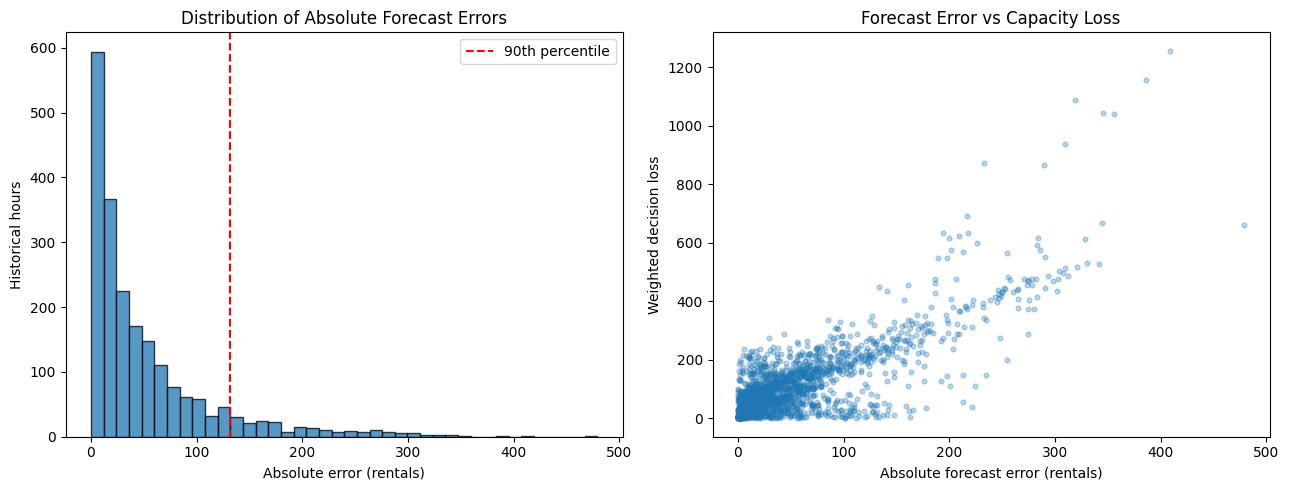

In [62]:

# L3 — HIGH-ERROR AND HIGH-LOSS HISTORICAL HOURS

# Largest absolute point-forecast errors
largest_errors = limits_df.nlargest(
    15, "absolute_error"
)[
    [
        "datetime",
        "cnt",
        "nb_mean",
        "residual",
        "absolute_error",
        "predicted_sd",
        "covered90"
    ]
]

# Largest realized capacity losses
largest_losses = limits_df.nlargest(
    15, "nb_loss"
)[
    [
        "datetime",
        "cnt",
        "nb_capacity",
        "nb_shortage",
        "nb_excess",
        "nb_loss",
        "baseline_loss"
    ]
]

print("15 LARGEST ABSOLUTE FORECAST ERRORS")
display(largest_errors.round(3))

print("\n15 LARGEST NB2 CAPACITY LOSSES")
display(largest_losses.round(3))

# Descriptive high-error threshold
error_threshold = limits_df[
    "absolute_error"
].quantile(0.90)

limits_df["high_error"] = (
    limits_df["absolute_error"] >= error_threshold
)

# Frequency of 90% interval misses among high-error hours
high_error_interval_miss = (
    ~limits_df.loc[
        limits_df["high_error"], "covered90"
    ]
).mean()

print("\nHIGH-ERROR DIAGNOSTICS")
print(
    "90th percentile absolute error:",
    round(error_threshold, 3),
    "rentals"
)
print(
    "90% interval miss rate among high-error hours:",
    f"{high_error_interval_miss:.2%}"
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(
    limits_df["absolute_error"],
    bins=40,
    edgecolor="black",
    alpha=0.75
)
axes[0].axvline(
    error_threshold,
    color="red",
    linestyle="--",
    label="90th percentile"
)
axes[0].set_title("Distribution of Absolute Forecast Errors")
axes[0].set_xlabel("Absolute error (rentals)")
axes[0].set_ylabel("Historical hours")
axes[0].legend()

axes[1].scatter(
    limits_df["absolute_error"],
    limits_df["nb_loss"],
    alpha=0.3,
    s=12
)
axes[1].set_title("Forecast Error vs Capacity Loss")
axes[1].set_xlabel("Absolute forecast error (rentals)")
axes[1].set_ylabel("Weighted decision loss")

fig.tight_layout()
plt.show()


RELIABILITY BY PREDICTED DEMAND


,demand_group,hours,mean_prediction,mean_observed,signed_bias,mae,rmse,coverage90,mean_interval_width,average_decision_loss
0,Low,700,36.265,35.367,-0.898,14.706,23.747,0.840,47.863,30.280
1,Medium,698,194.978,188.536,-6.443,46.855,65.334,0.920,240.367,101.116
2,High,700,456.441,440.269,-16.172,93.570,122.856,0.971,556.936,185.393


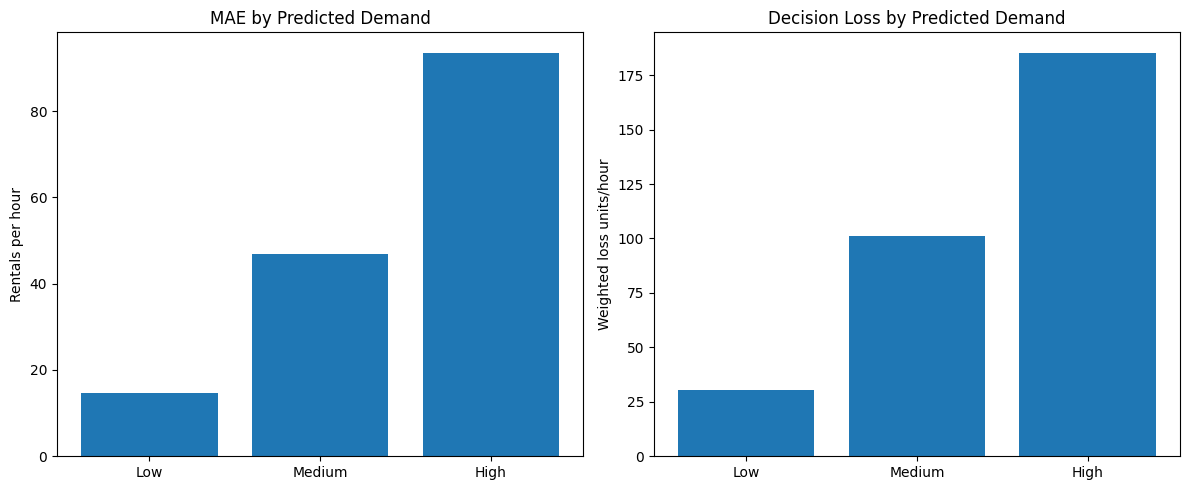

In [63]:

# L4 — RELIABILITY BY PREDICTED DEMAND

limits_df["demand_group"] = pd.qcut(
    limits_df["nb_mean"],
    q=3,
    labels=["Low", "Medium", "High"],
    duplicates="drop"
)

demand_reliability = (
    limits_df.groupby("demand_group", observed=True)
    .agg(
        hours=("cnt", "size"),
        mean_prediction=("nb_mean", "mean"),
        mean_observed=("cnt", "mean"),
        signed_bias=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        ),
        coverage90=("covered90", "mean"),
        mean_interval_width=("width90", "mean"),
        average_decision_loss=("nb_loss", "mean")
    )
    .reset_index()
)

print("RELIABILITY BY PREDICTED DEMAND")
display(demand_reliability.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

groups = demand_reliability["demand_group"].astype(str)

axes[0].bar(
    groups,
    demand_reliability["mae"]
)
axes[0].set_title("MAE by Predicted Demand")
axes[0].set_ylabel("Rentals per hour")

axes[1].bar(
    groups,
    demand_reliability["average_decision_loss"]
)
axes[1].set_title("Decision Loss by Predicted Demand")
axes[1].set_ylabel("Weighted loss units/hour")

fig.tight_layout()
plt.show()


MONTHLY RELIABILITY — OCTOBER TO DECEMBER 2012


,month,hours,mean_observed,mean_prediction,signed_bias,mae,rmse,coverage90,mean_interval_width,average_loss
0,2012-10,684,286.130,290.896,-4.766,61.817,96.909,0.930,356.411,126.048
1,2012-11,677,214.378,222.557,-8.179,52.798,80.651,0.898,273.668,110.970
2,2012-12,737,167.837,178.215,-10.378,41.345,64.985,0.904,219.915,81.691


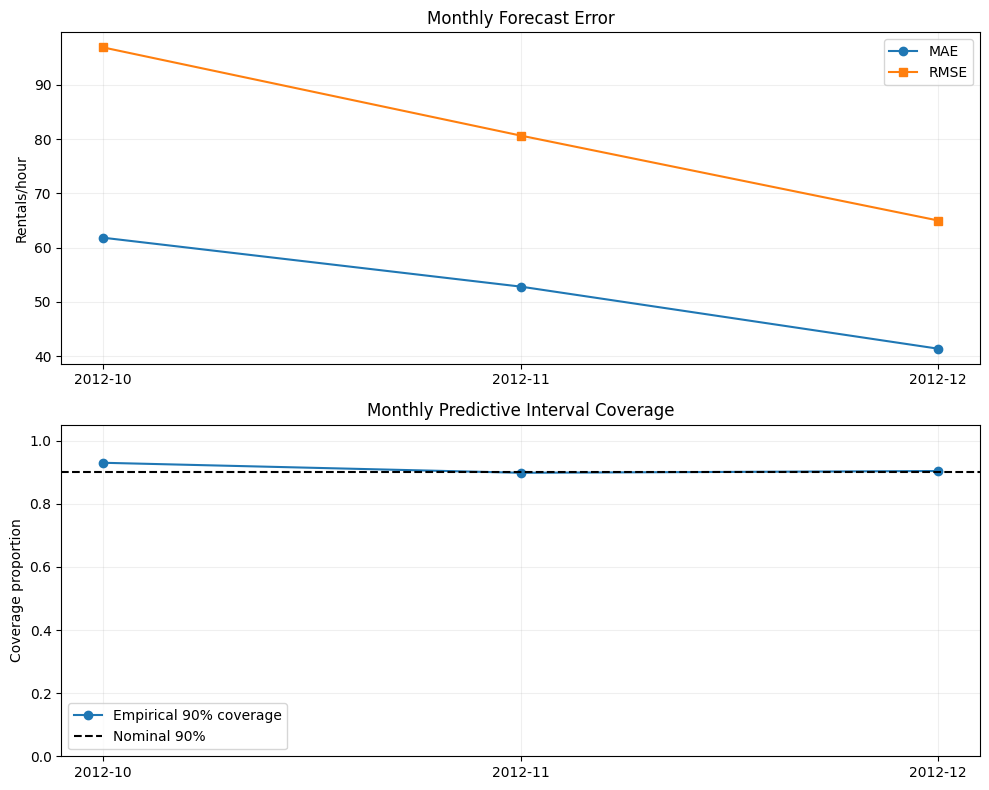

In [64]:

# L5 — MONTHLY RELIABILITY AND CALIBRATION

limits_df["month"] = (
    limits_df["datetime"]
    .dt.to_period("M")
    .astype(str)
)

monthly_limits = (
    limits_df.groupby("month")
    .agg(
        hours=("cnt", "size"),
        mean_observed=("cnt", "mean"),
        mean_prediction=("nb_mean", "mean"),
        signed_bias=("residual", "mean"),
        mae=("absolute_error", "mean"),
        rmse=(
            "squared_error",
            lambda x: np.sqrt(np.mean(x))
        ),
        coverage90=("covered90", "mean"),
        mean_interval_width=("width90", "mean"),
        average_loss=("nb_loss", "mean")
    )
    .reset_index()
)

print("MONTHLY RELIABILITY — OCTOBER TO DECEMBER 2012")
display(monthly_limits.round(3))

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(
    monthly_limits["month"],
    monthly_limits["mae"],
    marker="o",
    label="MAE"
)
axes[0].plot(
    monthly_limits["month"],
    monthly_limits["rmse"],
    marker="s",
    label="RMSE"
)
axes[0].set_title("Monthly Forecast Error")
axes[0].set_ylabel("Rentals/hour")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].plot(
    monthly_limits["month"],
    monthly_limits["coverage90"],
    marker="o",
    label="Empirical 90% coverage"
)
axes[1].axhline(
    0.90,
    color="black",
    linestyle="--",
    label="Nominal 90%"
)
axes[1].set_title("Monthly Predictive Interval Coverage")
axes[1].set_ylabel("Coverage proportion")
axes[1].set_ylim(0, 1.05)
axes[1].legend()
axes[1].grid(alpha=0.2)

fig.tight_layout()
plt.show()


RELIABILITY BY MODEL-IMPLIED UNCERTAINTY


,uncertainty_group,hours,mean_prediction,mean_predicted_sd,mean_interval_width,mae,coverage90,average_loss
0,Lower,699,36.185,14.777,47.763,14.716,0.840,30.300
1,Middle,699,194.831,74.235,240.192,46.799,0.920,100.994
2,Higher,700,456.441,172.145,556.936,93.570,0.971,185.393



OVERALL UNCERTAINTY DIAGNOSTICS
Average predicted standard deviation: 87.093 rentals
Average 90% interval width: 281.761 rental-count units
Mean absolute Pearson residual: 0.731


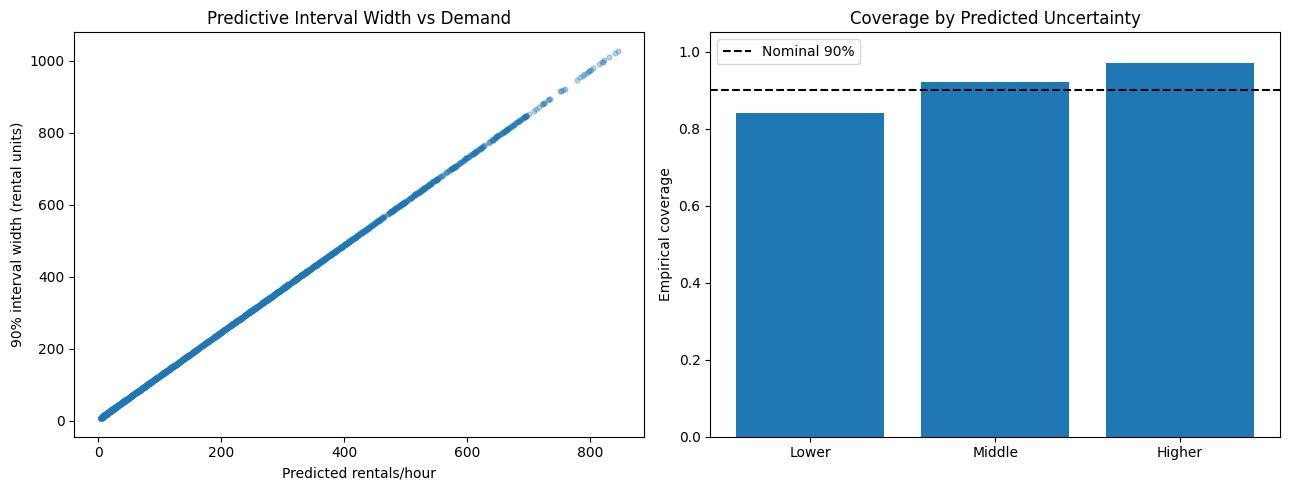

In [65]:

# L6 — PREDICTIVE UNCERTAINTY AND RELIABILITY

# Group hours by predicted 90% interval width
limits_df["uncertainty_group"] = pd.qcut(
    limits_df["width90"].rank(method="first"),
    q=3,
    labels=["Lower", "Middle", "Higher"]
)

uncertainty_summary = (
    limits_df.groupby("uncertainty_group", observed=True)
    .agg(
        hours=("cnt", "size"),
        mean_prediction=("nb_mean", "mean"),
        mean_predicted_sd=("predicted_sd", "mean"),
        mean_interval_width=("width90", "mean"),
        mae=("absolute_error", "mean"),
        coverage90=("covered90", "mean"),
        average_loss=("nb_loss", "mean")
    )
    .reset_index()
)

print("RELIABILITY BY MODEL-IMPLIED UNCERTAINTY")
display(uncertainty_summary.round(3))

# Standardized error magnitude
limits_df["absolute_pearson"] = (
    limits_df["absolute_error"]
    / limits_df["predicted_sd"]
)

print("\nOVERALL UNCERTAINTY DIAGNOSTICS")
print(
    "Average predicted standard deviation:",
    round(limits_df["predicted_sd"].mean(), 3),
    "rentals"
)
print(
    "Average 90% interval width:",
    round(limits_df["width90"].mean(), 3),
    "rental-count units"
)
print(
    "Mean absolute Pearson residual:",
    round(limits_df["absolute_pearson"].mean(), 3)
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    limits_df["nb_mean"],
    limits_df["width90"],
    alpha=0.3,
    s=12
)
axes[0].set_title("Predictive Interval Width vs Demand")
axes[0].set_xlabel("Predicted rentals/hour")
axes[0].set_ylabel("90% interval width (rental units)")

labels = uncertainty_summary[
    "uncertainty_group"
].astype(str)

axes[1].bar(
    labels,
    uncertainty_summary["coverage90"]
)
axes[1].axhline(
    0.90,
    linestyle="--",
    color="black",
    label="Nominal 90%"
)
axes[1].set_title("Coverage by Predicted Uncertainty")
axes[1].set_ylabel("Empirical coverage")
axes[1].set_ylim(0, 1.05)
axes[1].legend()

fig.tight_layout()
plt.show()


HISTORICAL CAPACITY RISK


,Diagnostic,Value,Unit
0,Total shortage units,12331.000,rental-count units
1,Total excess units,172226.000,rental-count units
2,Average shortage units per hour,5.878,rental-count units/hour
3,Average excess units per hour,82.091,rental-count units/hour
4,Hours with shortages,283.000,hours
5,Hours with excess capacity,1806.000,hours
6,Shortage-related weighted loss,49324.000,weighted loss units
7,Excess-related weighted loss,172226.000,weighted loss units
8,Total weighted loss,221550.000,weighted loss units
9,Average weighted loss per hour,105.601,weighted loss units/hour


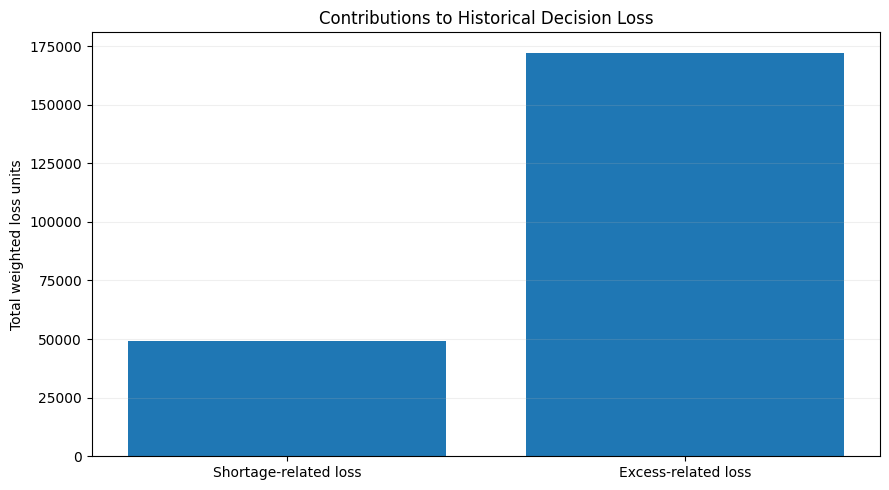

In [66]:

# L7 — CAPACITY RISK AND LOSS DECOMPOSITION

shortage_units = limits_df["nb_shortage"].sum()
excess_units = limits_df["nb_excess"].sum()

shortage_loss = C_SHORT * shortage_units
excess_loss = C_EXCESS * excess_units

total_loss = limits_df["nb_loss"].sum()

assert np.isclose(
    shortage_loss + excess_loss,
    total_loss
)

shortage_hours = (
    limits_df["nb_shortage"] > 0
).sum()

excess_hours = (
    limits_df["nb_excess"] > 0
).sum()

capacity_risk = pd.DataFrame({
    "Diagnostic": [
        "Total shortage units",
        "Total excess units",
        "Average shortage units per hour",
        "Average excess units per hour",
        "Hours with shortages",
        "Hours with excess capacity",
        "Shortage-related weighted loss",
        "Excess-related weighted loss",
        "Total weighted loss",
        "Average weighted loss per hour"
    ],
    "Value": [
        shortage_units,
        excess_units,
        shortage_units / n_hours,
        excess_units / n_hours,
        shortage_hours,
        excess_hours,
        shortage_loss,
        excess_loss,
        total_loss,
        total_loss / n_hours
    ],
    "Unit": [
        "rental-count units",
        "rental-count units",
        "rental-count units/hour",
        "rental-count units/hour",
        "hours",
        "hours",
        "weighted loss units",
        "weighted loss units",
        "weighted loss units",
        "weighted loss units/hour"
    ]
})

print("HISTORICAL CAPACITY RISK")
display(capacity_risk.round(3))

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    ["Shortage-related loss", "Excess-related loss"],
    [shortage_loss, excess_loss]
)

ax.set_title("Contributions to Historical Decision Loss")
ax.set_ylabel("Total weighted loss units")
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()


In [67]:

# L8 — MODEL ASSUMPTION AND LIMITATION REGISTER

assumption_register = pd.DataFrame([
    {
        "Area": "Conditional mean",
        "Assumption": "Log-linear NB2 regression is adequate",
        "Consequence": "Misspecified relationships can create systematic bias",
        "Evidence needed": "Residual diagnostics and nonlinear model comparisons"
    },
    {
        "Area": "Dispersion",
        "Assumption": "NB2 variance function adequately represents counts",
        "Consequence": "Incorrect dispersion affects interval calibration",
        "Evidence needed": "PIT, Pearson residuals, and interval coverage"
    },
    {
        "Area": "Parameter uncertainty",
        "Assumption": "Fitted parameters treated as fixed",
        "Consequence": "Predictive intervals omit estimation uncertainty",
        "Evidence needed": "Bootstrap or parameter-uncertainty propagation"
    },
    {
        "Area": "Temporal dependence",
        "Assumption": "Conditional predictive draws are independent",
        "Consequence": "Multi-hour uncertainty may be understated",
        "Evidence needed": "Residual dependence and joint simulation checks"
    },
    {
        "Area": "Predictor availability",
        "Assumption": "Historical lagged counts are known at forecast time",
        "Consequence": "Unavailable lags would invalidate operational forecasts",
        "Evidence needed": "Timestamped forecasting pipeline and horizon tests"
    },
    {
        "Area": "Demand measurement",
        "Assumption": "Completed rentals proxy demand",
        "Consequence": "Unmet demand is not directly measured",
        "Evidence needed": "Availability, stockout, and attempted-rental data"
    },
    {
        "Area": "Historical relevance",
        "Assumption": "Historical evaluation is informative",
        "Consequence": "Performance may not transfer to current operations",
        "Evidence needed": "Recent data and prospective evaluation"
    },
    {
        "Area": "Decision penalties",
        "Assumption": "Shortage penalty 4; excess penalty 1",
        "Consequence": "Capacity depends on assumed relative costs",
        "Evidence needed": "Operational cost and service-level analysis"
    },
    {
        "Area": "Capacity feasibility",
        "Assumption": "Recommended capacity can be implemented",
        "Consequence": "Inventory and rebalancing constraints are omitted",
        "Evidence needed": "Station-level operational constraints"
    }
])

print("FLOWCAST AI LIVE — ASSUMPTIONS AND LIMITATIONS")
display(assumption_register)

print(
    "\nThese are documented modeling assumptions "
    "and limitations, not newly tested hypotheses."
)


FLOWCAST AI LIVE — ASSUMPTIONS AND LIMITATIONS


,Area,Assumption,Consequence,Evidence needed
0,Conditional mean,Log-linear NB2 regression is adequate,Misspecified relationships can create systemat...,Residual diagnostics and nonlinear model compa...
1,Dispersion,NB2 variance function adequately represents co...,Incorrect dispersion affects interval calibration,"PIT, Pearson residuals, and interval coverage"
2,Parameter uncertainty,Fitted parameters treated as fixed,Predictive intervals omit estimation uncertainty,Bootstrap or parameter-uncertainty propagation
3,Temporal dependence,Conditional predictive draws are independent,Multi-hour uncertainty may be understated,Residual dependence and joint simulation checks
4,Predictor availability,Historical lagged counts are known at forecast...,Unavailable lags would invalidate operational ...,Timestamped forecasting pipeline and horizon t...
5,Demand measurement,Completed rentals proxy demand,Unmet demand is not directly measured,"Availability, stockout, and attempted-rental data"
6,Historical relevance,Historical evaluation is informative,Performance may not transfer to current operat...,Recent data and prospective evaluation
7,Decision penalties,Shortage penalty 4; excess penalty 1,Capacity depends on assumed relative costs,Operational cost and service-level analysis
8,Capacity feasibility,Recommended capacity can be implemented,Inventory and rebalancing constraints are omitted,Station-level operational constraints



These are documented modeling assumptions and limitations, not newly tested hypotheses.


In [68]:

# L9 — EVIDENCE-LINKED IMPROVEMENT PRIORITIES

# Identify groups with the largest observed errors
worst_demand = demand_reliability.loc[
    demand_reliability["mae"].idxmax()
]

worst_month = monthly_limits.loc[
    monthly_limits["mae"].idxmax()
]

# Identify the month with the largest absolute
# deviation from nominal 90% coverage
monthly_limits["coverage_gap90"] = (
    monthly_limits["coverage90"] - 0.90
).abs()

worst_calibration_month = monthly_limits.loc[
    monthly_limits["coverage_gap90"].idxmax()
]

improvement_plan = pd.DataFrame([
    {
        "Priority": 1,
        "Observed evidence": (
            "Highest demand-group MAE: "
            f"{worst_demand['mae']:.2f} rentals/hour"
        ),
        "Proposed improvement": (
            "Investigate nonlinear demand effects "
            "and alternative count models"
        ),
        "Evaluation": (
            "Compare held-out MAE, calibration, "
            "and weighted decision loss"
        )
    },
    {
        "Priority": 2,
        "Observed evidence": (
            "Highest monthly MAE: "
            f"{worst_month['month']}"
        ),
        "Proposed improvement": (
            "Add newer data and conduct rolling-origin "
            "temporal validation"
        ),
        "Evaluation": (
            "Compare performance across periods "
            "and explicitly defined forecast horizons"
        )
    },
    {
        "Priority": 3,
        "Observed evidence": (
            "Largest monthly 90% coverage deviation: "
            f"{worst_calibration_month['month']}"
        ),
        "Proposed improvement": (
            "Investigate conditional calibration "
            "and uncertainty estimation"
        ),
        "Evaluation": (
            "Compare coverage, PIT, interval width, "
            "and predictive scores"
        )
    },
    {
        "Priority": 4,
        "Observed evidence": (
            "Historical decision loss: "
            f"{total_loss / n_hours:.2f} "
            "weighted units/hour"
        ),
        "Proposed improvement": (
            "Obtain station inventory, stockout data, "
            "and real operational loss estimates"
        ),
        "Evaluation": (
            "Measure feasible capacity decisions "
            "and operationally justified loss"
        )
    },
    {
        "Priority": 5,
        "Observed evidence": (
            "Present-day performance not evaluated"
        ),
        "Proposed improvement": (
            "Test on recent operational observations"
        ),
        "Evaluation": (
            "Prospective calibration, error, "
            "and decision-loss evaluation"
        )
    }
])

print("FUTURE IMPROVEMENT PLAN")
display(improvement_plan)

print(
    "\nPriorities are proposed investigation steps. "
    "No improvement is assumed to be effective "
    "until it is independently evaluated."
)


FUTURE IMPROVEMENT PLAN


,Priority,Observed evidence,Proposed improvement,Evaluation
0,1,Highest demand-group MAE: 93.57 rentals/hour,Investigate nonlinear demand effects and alter...,"Compare held-out MAE, calibration, and weighte..."
1,2,Highest monthly MAE: 2012-10,Add newer data and conduct rolling-origin temp...,Compare performance across periods and explici...
2,3,Largest monthly 90% coverage deviation: 2012-10,Investigate conditional calibration and uncert...,"Compare coverage, PIT, interval width, and pre..."
3,4,Historical decision loss: 105.60 weighted unit...,"Obtain station inventory, stockout data, and r...",Measure feasible capacity decisions and operat...
4,5,Present-day performance not evaluated,Test on recent operational observations,"Prospective calibration, error, and decision-l..."



Priorities are proposed investigation steps. No improvement is assumed to be effective until it is independently evaluated.


In [69]:

# L10 — FINAL LIMITS SUMMARY

worst_demand_label = str(
    worst_demand["demand_group"]
)

final_limits = pd.DataFrame({
    "Finding": [
        "Held-out period",
        "Historical hours evaluated",
        "Average absolute forecast error",
        "Root mean squared error",
        "Mean signed forecast error",
        "Mean recommended capacity",
        "Average 90% interval width",
        "Empirical 90% interval coverage",
        "Average NB2 decision loss",
        "Average baseline decision loss",
        "NB2 improvement over baseline",
        "Highest-error predicted-demand group",
        "Highest-error historical month",
        "Present-day validation",
        "Unmet-demand measurement"
    ],
    "Result": [
        "October–December 2012",
        str(n_hours),
        f"{limits_df['absolute_error'].mean():.3f} rentals/hour",
        f"{np.sqrt(limits_df['squared_error'].mean()):.3f} rentals/hour",
        f"{limits_df['residual'].mean():.3f} rentals/hour",
        f"{limits_df['nb_capacity'].mean():.3f} capacity units/hour",
        f"{limits_df['width90'].mean():.3f} rental-count units",
        f"{limits_df['covered90'].mean():.2%}",
        f"{limits_df['nb_loss'].mean():.3f} weighted units/hour",
        f"{limits_df['baseline_loss'].mean():.3f} weighted units/hour",
        f"{limits_improvement:.3f} weighted units/hour",
        worst_demand_label,
        str(worst_month["month"]),
        "Not evaluated",
        "Not directly observed"
    ]
})

print("=" * 75)
print("FLOWCAST AI LIVE — FINAL LIMITS SUMMARY")
print("=" * 75)

display(final_limits)

print("\nASSUMPTIONS AND LIMITATIONS")
display(assumption_register)

print("\nPROPOSED IMPROVEMENTS")
display(improvement_plan)

print("\nFINAL SCOPE STATEMENT")
print(
    "All measured performance findings describe "
    "historical held-out completed rentals."
)
print(
    "Forecast errors are in rentals/hour; "
    "capacity decisions are in rental-count units."
)
print(
    "Decision losses are in weighted loss units, "
    "not dollars."
)
print(
    "Present-day accuracy, unmet demand, and "
    "realized operational savings remain unverified."
)


FLOWCAST AI LIVE — FINAL LIMITS SUMMARY


,Finding,Result
0,Held-out period,October–December 2012
1,Historical hours evaluated,2098
2,Average absolute forecast error,51.715 rentals/hour
3,Root mean squared error,81.512 rentals/hour
4,Mean signed forecast error,-7.839 rentals/hour
5,Mean recommended capacity,297.635 capacity units/hour
6,Average 90% interval width,281.761 rental-count units
7,Empirical 90% interval coverage,91.04%
8,Average NB2 decision loss,105.601 weighted units/hour
9,Average baseline decision loss,149.752 weighted units/hour



ASSUMPTIONS AND LIMITATIONS


,Area,Assumption,Consequence,Evidence needed
0,Conditional mean,Log-linear NB2 regression is adequate,Misspecified relationships can create systemat...,Residual diagnostics and nonlinear model compa...
1,Dispersion,NB2 variance function adequately represents co...,Incorrect dispersion affects interval calibration,"PIT, Pearson residuals, and interval coverage"
2,Parameter uncertainty,Fitted parameters treated as fixed,Predictive intervals omit estimation uncertainty,Bootstrap or parameter-uncertainty propagation
3,Temporal dependence,Conditional predictive draws are independent,Multi-hour uncertainty may be understated,Residual dependence and joint simulation checks
4,Predictor availability,Historical lagged counts are known at forecast...,Unavailable lags would invalidate operational ...,Timestamped forecasting pipeline and horizon t...
5,Demand measurement,Completed rentals proxy demand,Unmet demand is not directly measured,"Availability, stockout, and attempted-rental data"
6,Historical relevance,Historical evaluation is informative,Performance may not transfer to current operat...,Recent data and prospective evaluation
7,Decision penalties,Shortage penalty 4; excess penalty 1,Capacity depends on assumed relative costs,Operational cost and service-level analysis
8,Capacity feasibility,Recommended capacity can be implemented,Inventory and rebalancing constraints are omitted,Station-level operational constraints



PROPOSED IMPROVEMENTS


,Priority,Observed evidence,Proposed improvement,Evaluation
0,1,Highest demand-group MAE: 93.57 rentals/hour,Investigate nonlinear demand effects and alter...,"Compare held-out MAE, calibration, and weighte..."
1,2,Highest monthly MAE: 2012-10,Add newer data and conduct rolling-origin temp...,Compare performance across periods and explici...
2,3,Largest monthly 90% coverage deviation: 2012-10,Investigate conditional calibration and uncert...,"Compare coverage, PIT, interval width, and pre..."
3,4,Historical decision loss: 105.60 weighted unit...,"Obtain station inventory, stockout data, and r...",Measure feasible capacity decisions and operat...
4,5,Present-day performance not evaluated,Test on recent operational observations,"Prospective calibration, error, and decision-l..."



FINAL SCOPE STATEMENT
All measured performance findings describe historical held-out completed rentals.
Forecast errors are in rentals/hour; capacity decisions are in rental-count units.
Decision losses are in weighted loss units, not dollars.
Present-day accuracy, unmet demand, and realized operational savings remain unverified.



# Limits - Results, Assumptions, and Future Improvements

## 1. Scope of Historical Validation

FlowCast AI Live was developed as a probabilistic demand-forecasting and risk-aware capacity-planning framework using negative binomial (NB2) regression.

The model was evaluated using historical hourly completed bicycle-sharing rentals from October through December 2012, following a chronological separation of training, validation, and held-out testing data.

The fitted regression estimates expected hourly completed rentals and their predictive uncertainty.

The fitted conditional predictive distribution is:

$$
\boxed{
D_t\mid X_t
\sim
\operatorname{NB2}
\left(
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

where:

- $D_t$ is the observed completed rental count during hour $t$.
- $X_t$ is the vector of available historical predictors.
- $\widehat{\mu}_t$ is the fitted conditional expected rental count.
- $\widehat{\alpha}$ is the estimated NB2 dispersion parameter.

The fitted conditional mean is:

$$
\boxed{
\widehat{\mu}_t
=
\exp
\left(
X_t^{\mathsf T}\widehat{\beta}
\right)
}
$$

The model's predictive distribution is subsequently converted into an integer capacity recommendation through an asymmetric decision-loss function.

The held-out evaluation provides evidence of model performance under the historical conditions represented in the test dataset.

However, it does not establish forecasting accuracy for contemporary bicycle-sharing systems, different geographical environments, or operating conditions not represented in the historical observations.

The scope of inference is therefore:

$$
\boxed{
\text{Historical Held-Out Validation}
\not\Rightarrow
\text{Guaranteed Future Performance}
}
$$

---

## 2. Forecast Accuracy and Residual Reliability

Forecast accuracy was assessed using mean absolute error (MAE), root mean squared error (RMSE), and mean signed error (ME).

### 2.1 Raw Forecast Residuals

For each historical hour, the residual is:

$$
\boxed{
e_t
=
D_t-\widehat{\mu}_t
}
$$

where $D_t$ represents the observed completed rental count and $\widehat{\mu}_t$ is the predicted conditional mean.

### 2.2 Mean Absolute Error

The mean absolute error is:

$$
\boxed{
MAE
=
\frac{1}{m}
\sum_{t=1}^{m}
\left|
D_t-\widehat{\mu}_t
\right|
}
$$

MAE measures the average absolute difference between predicted and observed rentals, expressed in completed rentals per hour.

### 2.3 Root Mean Squared Error

The root mean squared error is:

$$
\boxed{
RMSE
=
\sqrt{
\frac{1}{m}
\sum_{t=1}^{m}
\left(
D_t-\widehat{\mu}_t
\right)^2
}
}
$$

RMSE uses the same units as MAE but places greater emphasis on large errors, making it particularly useful for identifying the influence of unusually inaccurate predictions.

### 2.4 Mean Signed Error

The mean signed error is:

$$
\boxed{
ME
=
\frac{1}{m}
\sum_{t=1}^{m}
\left(
D_t-\widehat{\mu}_t
\right)
}
$$

The direction of average prediction bias is interpreted as:

$$
\boxed{
\begin{aligned}
ME>0
&\Rightarrow
\text{Average underprediction}\\[6pt]
ME<0
&\Rightarrow
\text{Average overprediction}\\[6pt]
ME\approx0
&\Rightarrow
\text{Small overall signed bias}
\end{aligned}
}
$$

A mean residual close to zero suggests limited overall signed bias but does not eliminate the possibility of systematic errors within specific demand levels or time periods.

### 2.5 Rolling Residual Diagnostics

The 168-hour rolling residual mean is:

$$
\boxed{
\overline e_t^{(168)}
=
\frac{1}{168}
\sum_{j=0}^{167}
e_{t-j}
}
$$

This diagnostic helps identify persistent positive or negative residual deviations over historical weekly windows.

### 2.6 Standardized Pearson Residuals

The NB2 Pearson standardized residual is:

$$
\boxed{
r_t^P
=
\frac{
D_t-\widehat{\mu}_t
}{
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
}
$$

Under an adequately specified conditional mean and variance model, the reference properties are approximately:

$$
\boxed{
\begin{aligned}
\mathbb E[r_t^P\mid X_t]&\approx0\\[6pt]
\operatorname{Var}(r_t^P\mid X_t)&\approx1
\end{aligned}
}
$$

Residual diagnostics examine temporal patterns, rolling error behavior, and standardized Pearson residuals.

These assessments help distinguish approximately noise-like errors from persistent prediction bias, unexplained temporal structure, and variability not adequately represented by the NB2 model.

Individual predictions should be interpreted cautiously when they occur under conditions associated with large historical errors or systematic deviations.

Nevertheless, historical forecasting errors do not automatically imply that all predictions within a particular operating condition are unreliable.

---

## 3. Reliability Across Predicted Demand Levels

Model reliability was examined across low-, medium-, and high-predicted-demand conditions.

Let $\mathcal G_g$ denote the observations assigned to predicted-demand group $g$, and let:

$$
m_g=|\mathcal G_g|
$$

The analysis compares mean absolute error, root mean squared error, signed bias, predictive interval coverage, and weighted decision loss across these groups.

### 3.1 Group-Specific Mean Absolute Error

$$
\boxed{
MAE_g
=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
|D_t-\widehat{\mu}_t|
}
$$

### 3.2 Group-Specific Root Mean Squared Error

$$
\boxed{
RMSE_g
=
\sqrt{
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
(D_t-\widehat{\mu}_t)^2
}
}
$$

### 3.3 Group-Specific Signed Bias

$$
\boxed{
ME_g
=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
(D_t-\widehat{\mu}_t)
}
$$

### 3.4 Group-Specific Predictive Coverage

For a central predictive interval with nominal coverage $c$:

$$
\boxed{
\widehat C_g(c)
=
\frac{1}{m_g}
\sum_{t\in\mathcal G_g}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

### 3.5 NB2 Conditional Variance

An important property of the NB2 model is that conditional variability increases with the expected count:

$$
\boxed{
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
}
$$

The derivative of conditional variance with respect to the conditional mean is:

$$
\boxed{
\frac{\partial}
{\partial\mu_t}
\operatorname{Var}(D_t\mid X_t)
=
1+2\alpha\mu_t
}
$$

For positive dispersion and mean:

$$
\boxed{
1+2\alpha\mu_t>0
}
$$

Consequently, larger absolute forecasting errors may naturally occur during high-demand periods because the model allows greater variation around larger expected counts.

Increasing absolute error alone does not establish model misspecification.

Standardized residuals and predictive calibration are needed to determine whether observed variability is consistent with the uncertainty represented by the fitted distribution.

Demand-specific diagnostics therefore provide a more informative assessment of reliability than a single aggregate forecasting metric.

The model should be used with additional caution in demand conditions where historical evidence reveals persistent bias, unusually large standardized errors, or substantial disagreement between observed and model-implied predictive interval coverage.

---

## 4. Temporal Reliability and Forecasting Horizon Limitations

The chronological held-out evaluation examines forecasting performance across October, November, and December 2012.

Let $\mathcal T_j$ denote the set of held-out observations belonging to historical calendar period $j$, with:

$$
m_j=|\mathcal T_j|
$$

Monthly and weekly diagnostics provide information about changes in forecast error, residual bias, predictive coverage, and decision loss.

### 4.1 Calendar-Period Mean Absolute Error

$$
\boxed{
MAE_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
|D_t-\widehat{\mu}_t|
}
$$

### 4.2 Calendar-Period Signed Bias

$$
\boxed{
ME_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
(D_t-\widehat{\mu}_t)
}
$$

### 4.3 Calendar-Period Predictive Coverage

$$
\boxed{
\widehat C_j(c)
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

### 4.4 Calendar-Period Decision Loss

$$
\boxed{
\overline L_j
=
\frac{1}{m_j}
\sum_{t\in\mathcal T_j}
L(q_t^*,D_t)
}
$$

Variation across successive historical weeks or months may reflect changes in rental demand, weather conditions, calendar effects, seasonal patterns, or relationships not fully captured by the fitted regression.

However, performance differences across successive historical weeks do not necessarily measure the effect of increasing forecast horizon.

A genuine multi-horizon forecasting experiment requires predictions issued from explicitly defined forecast origins, with the information available at each origin carefully controlled.

For forecast origin $o$ and horizon $h$, a valid forecast has the conceptual form:

$$
\boxed{
\widehat D_{o+h\mid o}
=
f_h(\mathcal I_o)
}
$$

where $\mathcal I_o$ represents the information available at forecast origin $o$.

Because the current evaluation does not establish this multi-step forecasting design, conclusions about forecast-accuracy degradation over longer horizons remain unverified.

---

## 5. Predictive Uncertainty and Calibration

FlowCast AI Live represents predictive uncertainty through the fitted negative binomial distribution.

### 5.1 Conditional Predictive Variance

The fitted conditional predictive variance is:

$$
\boxed{
\widehat V_t
=
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
$$

### 5.2 Predictive Standard Deviation

The corresponding predictive standard deviation is:

$$
\boxed{
\widehat{\sigma}_t
=
\sqrt{
\widehat{\mu}_t+
\widehat{\alpha}\widehat{\mu}_t^2
}
}
$$

Both quantities describe uncertainty in hourly completed rental counts.

### 5.3 Central Predictive Intervals

For nominal coverage level $c$, the predictive interval endpoints are:

$$
\boxed{
L_t(c)
=
F_t^{-1}
\left(
\frac{1-c}{2}
\right)
}
$$

$$
\boxed{
U_t(c)
=
F_t^{-1}
\left(
\frac{1+c}{2}
\right)
}
$$

The predictive interval width is:

$$
\boxed{
W_t(c)=U_t(c)-L_t(c)
}
$$

The empirical coverage is:

$$
\boxed{
\widehat C(c)
=
\frac{1}{m}
\sum_{t=1}^{m}
\mathbb I
\left(
L_t(c)\leq D_t\leq U_t(c)
\right)
}
$$

Predictive interval widths are expressed in rental-count units, while empirical coverage is expressed as a proportion or percentage of historical observations.

### 5.4 Randomized Probability Integral Transform

For observed count $D_t=d_t$, the randomized PIT is:

$$
\boxed{
u_t
=
F_t(d_t-1)
+
v_t
\left[
F_t(d_t)-F_t(d_t-1)
\right]
}
$$

where:

$$
v_t\sim\operatorname{Uniform}(0,1)
$$

Under a correctly specified conditional predictive distribution:

$$
\boxed{
u_t\sim\operatorname{Uniform}(0,1)
}
$$

The theoretical reference moments are:

$$
\boxed{
\mathbb E[u_t]=0.5,
\qquad
\operatorname{Var}(u_t)=\frac{1}{12}
}
$$

Predictive calibration was evaluated through empirical interval coverage and randomized PIT diagnostics.

A calibrated predictive distribution should produce observed outcomes consistent with its assigned probabilities.

However, because rental counts are discrete, central quantile intervals can have actual coverage exceeding their nominal levels.

Furthermore, the predictive distributions condition on estimated regression parameters and do not fully propagate parameter-estimation uncertainty.

Residual temporal dependence and possible distributional misspecification may also affect uncertainty estimates.

Therefore, predictive intervals should be interpreted as model-based uncertainty estimates rather than guaranteed ranges of future demand.

---

## 6. Capacity Decision Consequences

The project's capacity-planning framework converts probabilistic rental forecasts into explicit integer capacity recommendations.

### 6.1 Asymmetric Decision-Loss Function

The asymmetric decision-loss function is:

$$
\boxed{
L(q,D)
=
4\max(D-q,0)
+
\max(q-D,0)
}
$$

Under this rule, one rental-count unit of shortage incurs four weighted loss units, whereas one excess capacity unit incurs one weighted loss unit.

### 6.2 Critical Fractile

The shortage and excess penalties are:

$$
C_{\mathrm{short}}=4,
\qquad
C_{\mathrm{excess}}=1
$$

The critical fractile is:

$$
\boxed{
\tau
=
\frac{
C_{\mathrm{short}}
}{
C_{\mathrm{short}}+C_{\mathrm{excess}}
}
=
\frac{4}{4+1}
=
0.80
}
$$

### 6.3 Optimal Capacity Decision

The capacity decision minimizes expected asymmetric loss:

$$
\boxed{
q_t^*
=
\underset{q\in\mathbb Z_{\geq0}}
{\operatorname{arg\,min}}
\mathbb E
\left[
L(q,D_t)\mid X_t
\right]
}
$$

The recommended capacity is the smallest nonnegative integer reaching the 80th percentile of the fitted predictive distribution:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\widehat{\mu}_t,
\widehat{\alpha}
\right)
}
$$

Equivalently, under the shape-probability parameterization:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\frac{1}{\widehat{\alpha}},
\frac{1}{
1+\widehat{\alpha}\widehat{\mu}_t
}
\right)
}
$$

This rule prioritizes shortage prevention because shortages carry a greater assumed penalty than excess capacity.

The resulting recommendations are measured in rental-count capacity units for each hour.

### 6.4 Historical Decision Evaluation

The realized hourly decision loss is:

$$
\boxed{
L_t^{\mathrm{NB}}
=
4\max(D_t-q_t^*,0)
+
\max(q_t^*-D_t,0)
}
$$

The average held-out decision loss is:

$$
\boxed{
\overline L_{\mathrm{NB}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L_t^{\mathrm{NB}}
}
$$

The same-hour previous-week baseline is:

$$
\boxed{
q_t^{\mathrm{base}}
=
D_{t-168}
}
$$

The average baseline loss is:

$$
\boxed{
\overline L_{\mathrm{base}}
=
\frac{1}{m}
\sum_{t=1}^{m}
L(q_t^{\mathrm{base}},D_t)
}
$$

The historical loss difference is:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

A lower average loss indicates a more favorable historical decision outcome under the specified penalty structure.

However, minimizing expected loss under the fitted predictive distribution does not guarantee that the model-based action will outperform every alternative on realized held-out observations.

The penalty weights are assumed relative priorities rather than empirically established financial costs.

Consequently, reductions in weighted loss cannot be interpreted directly as monetary savings.

---

## 7. Important Statistical Assumptions

Several statistical assumptions influence the interpretation and reliability of the model.

### 7.1 Conditional Mean Specification

The regression assumes that the selected predictors adequately describe expected completed rental counts through a log-linear relationship:

$$
\boxed{
\log(\mu_t)
=
X_t^{\mathsf T}\beta
}
$$

Equivalently:

$$
\boxed{
\mu_t
=
\exp(X_t^{\mathsf T}\beta)
}
$$

If relevant nonlinear relationships, interactions, or temporal patterns are omitted, the fitted conditional mean may exhibit systematic bias.

### 7.2 Negative Binomial Variance Specification

The NB2 model assumes:

$$
\boxed{
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
}
$$

The conditional variance-to-mean ratio is:

$$
\boxed{
\frac{
\operatorname{Var}(D_t\mid X_t)
}{
\mathbb E[D_t\mid X_t]
}
=
1+\alpha\mu_t
}
$$

This accommodates overdispersion relative to a Poisson model but does not guarantee that all forms of observed variability are adequately represented.

### 7.3 Fixed Parameter Estimates

The predictive distribution uses estimated regression coefficients and dispersion:

$$
\boxed{
\widehat{\theta}
=
\left(
\widehat{\beta},
\widehat{\alpha}
\right)
}
$$

The predictive calculations do not fully account for uncertainty in these estimates.

### 7.4 Temporal Dependence

Lagged predictors and calendar features may capture recurring patterns, but residual autocorrelation can remain.

Residual dependence at lag $k$ can be examined using:

$$
\boxed{
\rho_e(k)
=
\operatorname{Corr}
(e_t,e_{t-k})
}
$$

Independent conditional simulations may therefore fail to represent the complete dependence structure of multi-hour rental activity.

### 7.5 Predictor Availability

Lagged rental counts and other historical predictors are assumed to be available at the intended forecasting time.

Operational predictions must not depend on future information unavailable when a decision is made.

### 7.6 Historical Representativeness

The chronological test period evaluates historical generalization, not guaranteed performance under future operating conditions or distribution shifts.

These assumptions should be reassessed through additional validation and diagnostic testing before operational deployment.

---

## 8. Operational and Data Limitations

One of the most important limitations is the distinction between observed completed rentals and unconstrained customer demand.

The historical dataset records completed rental transactions but does not directly measure customers who were unable to rent bicycles because of insufficient inventory, unavailable docks, or other service constraints.

Conceptually, when desired demand includes unfulfilled requests:

$$
\boxed{
D_t^{\mathrm{completed}}
\leq
D_t^{\mathrm{desired}}
}
$$

Consequently, completed rentals may underestimate underlying customer demand during periods of limited system availability.

The capacity recommendation should therefore be interpreted as an illustrative rental-count capacity target rather than a fully validated estimate of the physical resources needed to satisfy all potential demand.

The current framework does not explicitly incorporate:

- Station-level bicycle inventory.
- Dock occupancy.
- Fleet rebalancing.
- Vehicle availability.
- Staffing requirements.
- Geographical redistribution.
- Implementation constraints.

Additionally, the model has not established actual customer-service costs, operating expenses, or financial returns associated with the proposed capacity decisions.

These limitations restrict the direct translation of statistical forecasts into operational deployment recommendations.

The distinction is:

$$
\boxed{
\text{Statistical Capacity Recommendation}
\not\equiv
\text{Operational Deployment Plan}
}
$$

---

## 9. Value of Improved Forecasting and Future Improvements

The decision framework quantifies the consequences of forecasting and capacity-planning errors using weighted loss units.

### 9.1 Historical Decision Improvement

The difference between historical baseline loss and model-based loss measures realized improvement or deterioration under the project's asymmetric objective:

$$
\boxed{
\Delta L
=
\overline L_{\mathrm{base}}
-
\overline L_{\mathrm{NB}}
}
$$

Positive values indicate lower historical average weighted loss for the NB2 decision rule.

### 9.2 Expected Value of Perfect Information

The conditional expected risk of a capacity action is:

$$
\boxed{
R(q\mid X_t)
=
\mathbb E
\left[
L(q,D_t)\mid X_t
\right]
}
$$

The model-optimal expected loss is:

$$
\boxed{
R_t^*
=
\min_{q\in\mathbb Z_{\geq0}}
R(q\mid X_t)
}
$$

Under perfect advance knowledge:

$$
q_t^{\mathrm{perfect}}=D_t
$$

and:

$$
L(D_t,D_t)=0
$$

Therefore:

$$
\boxed{
EVPI_t
=
R_t^*
}
$$

Equivalently:

$$
\boxed{
EVPI_t
=
\mathbb E
\left[
L(q_t^*,D_t)\mid X_t
\right]
}
$$

The expected value of perfect information provides an idealized upper bound on the loss that could be eliminated if future completed rental counts were known exactly before selecting capacity.

However, perfect advance knowledge is not operationally achievable, and this benchmark does not measure the expected benefit of any specific forecasting improvement.

### 9.3 Future Improvements

With additional time and data, future work would prioritize the following developments:

1. **Contemporary evaluation:** Obtain newer bicycle-sharing observations and conduct prospective validation to assess whether historical forecasting relationships remain applicable.

2. **Improved demand measurement:** Incorporate station-level bicycle availability, dock occupancy, stockout events, and unmet-demand indicators to distinguish completed transactions from underlying customer demand.

3. **Explicit forecast-horizon testing:** Implement rolling-origin evaluation for defined prediction horizons while ensuring every model input is available at the corresponding forecast origin.

4. **Alternative forecasting models:** Compare nonlinear regression, alternative count distributions, and appropriate machine-learning approaches against the existing NB2 model using consistent chronological evaluation procedures.

5. **Enhanced uncertainty quantification:** Investigate conditional calibration, parameter uncertainty, residual temporal dependence, and uncertainty estimates for multi-hour forecasts.

6. **Operationally justified decision costs:** Replace assumed shortage and excess-capacity penalties with defensible estimates derived from service requirements and actual operational consequences.

7. **Constrained capacity optimization:** Integrate station inventories, rebalancing resources, and other physical constraints to develop feasible operational recommendations.

Each proposed improvement would require independent evaluation using forecasting accuracy, predictive calibration, and weighted decision loss.

These extensions represent future research directions rather than demonstrated improvements.

---

## 10. Final Analytical Conclusion

FlowCast AI Live establishes a transparent framework connecting probabilistic demand forecasting with risk-aware capacity planning.

Its negative binomial regression represents expected completed rental counts and accommodates overdispersion through an explicit conditional variance function:

$$
\boxed{
\operatorname{Var}(D_t\mid X_t)
=
\mu_t+\alpha\mu_t^2
}
$$

The model's predictive distribution supports uncertainty estimation, residual diagnostics, calibration assessment, and capacity recommendations determined by asymmetric decision loss.

The central capacity rule is:

$$
\boxed{
q_t^*
=
F_{\mathrm{NB}}^{-1}
\left(
0.80;
\widehat{\mu}_t,\widehat{\alpha}
\right)
}
$$

The primary practical effects are expressed in interpretable units:

| Analytical Quantity | Reporting Unit |
|---|---|
| Forecasting error | Completed rentals per hour |
| Predictive uncertainty | Rental-count units |
| Capacity recommendations | Rental-count capacity units |
| Average decision performance | Weighted loss units per hour |
| Total historical decision loss | Weighted loss units across the held-out period |

The framework's methodological strengths include chronological held-out evaluation, interpretable count-based modeling, explicit probabilistic uncertainty, and a mathematically justified decision rule reflecting the relative consequences of shortages and excess capacity.

Its principal limitations concern:

- The historical age of the dataset.
- Incomplete observation of underlying customer demand.
- Potential model misspecification.
- Unpropagated parameter uncertainty.
- The absence of real operational capacity constraints.

The results should therefore be interpreted as evidence about historical probabilistic forecasting and illustrative capacity decisions rather than proof of present-day operational effectiveness or realized financial savings.

The complete analytical relationship is:

$$
\boxed{
\begin{aligned}
\text{Historical Rental Data}
&\longrightarrow
\text{NB2 Predictive Model}\\[6pt]
\text{NB2 Predictive Model}
&\longrightarrow
\text{Probabilistic Forecasts}\\[6pt]
\text{Probabilistic Forecasts}
&\longrightarrow
\text{Risk-Aware Capacity Decisions}\\[6pt]
\text{Held-Out Evaluation}
&\longrightarrow
\text{Forecast and Decision Diagnostics}\\[6pt]
\text{Limitations Analysis}
&\longrightarrow
\text{Reliability Boundaries}
\end{aligned}
}
$$

**Overall, FlowCast AI Live demonstrates how statistical uncertainty can be translated into explicit, interpretable decisions while maintaining clear boundaries between historical evidence, modeling assumptions, and future operational applications.**
